In [3]:
import numpy as np
import pandas as pd
from pandas import read_csv
from numpy import isnan
from sklearn.impute import KNNImputer
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import auc, roc_auc_score, RocCurveDisplay, roc_curve, accuracy_score, precision_score, recall_score, confusion_matrix, log_loss
from sklearn.preprocessing import StandardScaler
import shap
import collections
import seaborn as sns
from imblearn.over_sampling import SMOTE

def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).flatten()
    return tn / (tn + fp)

In [1]:
conda install -n sth ipykernel --update-deps --force-reinstall

DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): repo.anaconda.com:443
DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): repo.anaconda.com:443
DEBUG:urllib3.connectionpool:Starting new HTTPS connection (1): repo.anaconda.com:443
/ DEBUG:urllib3.connectionpool:https://repo.anaconda.com:443 "GET /pkgs/r/osx-arm64/current_repodata.json HTTP/1.1" 304 0
- DEBUG:urllib3.connectionpool:https://repo.anaconda.com:443 "GET /pkgs/main/osx-arm64/current_repodata.json HTTP/1.1" 304 0
DEBUG:urllib3.connectionpool:https://repo.anaconda.com:443 "GET /pkgs/main/noarch/current_repodata.json HTTP/1.1" 304 0
\ DEBUG:urllib3.connectionpool:https://repo.anaconda.com:443 "GET /pkgs/r/noarch/current_repodata.json HTTP/1.1" 304 0
done
Solving environment: | Solving environment: done
done


==> WARNING: A newer version of conda exists. <==
  current version: 23.7.4
  latest version: 25.7.0

Please update conda by running

    $ conda update -n base -c defaults conda

Or to minimize 

In [4]:
def Standardize(data, cutoff, feature):
    data = data.copy()
    data.reset_index(drop=True)
    section1 = data.loc[data['visitday'] < cutoff, feature] # select the rows before cutoff
    section2 = data.loc[data['visitday'] > cutoff, feature] # select the rows after cutoff
    df_bef_aft = pd.concat([section1, section2], axis=1) #concatenate the feature of both sections as separate columns
    df_bef_aft.columns  = ['before', 'after'] # give names to columns
    
    object= StandardScaler() 
    scale = object.fit_transform(df_bef_aft) # scale the columns/sections
    
    combined = np.array([row[~np.isnan(row)][0] if np.any(~np.isnan(row)) else np.nan for row in scale]) #stack the arrays into one
    combined_feature = combined.reshape(-1,1) # reshape to make it nx1 (column-wise)
    df_bef_aft[f"{feature}_ss"] = combined_feature # make the scaled column part of the dataframe
    data[feature] = df_bef_aft[f"{feature}_ss"] # make the scaled column part of the dataframe with other features

    return data[feature]

# Data clean up 

In [5]:
# Choose 55 features
df= pd.read_csv("/Users/kayharuni/Desktop/ib_lab/colorectar_cancer/data/health_check_english.csv", index_col=0)
df = df[['sex', 'age', 'visitday', 'height', 'weight', 'SW', 'degree_of_obesity',
       'eye_pressure_right', 'eye_pressure_left', 'blood_pressure_sitting_up',
       'blood_pressure_sitting_down', 'wbc', 'lymph', 'mono', 'basophil',
       'red_blood_cell', 'hemo_content', 'hematocrit', 'MCV', 'MCH', 'MCHC',
       'PLT', 'total_cho', 'HDL', 'LDL', 'neutral_fat', 'blood_sugar_hungry',
       'uric_acid', 'total_protein', 'albumin', 'protein_a1', 'protein_a2',
       'protein_b1', 'protein_r', 'ZTT', 'total_bil', 'cholinesterase', 'GOT',
       'GPT', 'alp', 'r_GTP', 'LAP', 'LDH', 'serum_amylase', 'urea_N', 'Cr',
       'Na', 'K', 'Cl', 'Ca', 'P', 'PH', 'urine_ratio', 'CF', 'ID']]
df = df.reset_index(drop=True)
# Remove all values that are strins in each column
for i in df.columns:
    df= df[df[i]!= '未検査']
    df = df[df[i] != '測定不能']
    df = df[df[i] != '判定不能']
    df = df[df[i] != '検査不能']
    df = df[df[i] != '検査中止']
    df = df[df[i]  !=  '≧1.050']
    df = df[df[i]  !=  '>47']
    df = df[df[i]  !=  '<3']
    df = df[df[i]  !=  '凝固']
    df = df[df[i]  !=  '<60']
    df = df[df[i]  !=  '>5.7']
    df = df[df[i]  !=  '>47']
    df = df[df[i] != '>42.6']
    df = df[df[i] != '>36.9']
    df = df[df[i] != '>1.9']
    df = df[df[i] != '本人希望未検査']

df = df.replace({'.39.7':39.7})
df_fix = df.copy()
check = df.loc[df['cholinesterase'] < 1000]
df_fix.loc[check.index, 'cholinesterase']*=10
df_fix[['total_protein', 'albumin', 'protein_a1', 'protein_a2', 'protein_b1', 'protein_r']]
df_fix['albumin'] = (df_fix['albumin']/100)*df_fix['total_protein']
df_fix['protein_a1'] = (df_fix['protein_a1']/100)*df_fix['total_protein']
df_fix['protein_a2'] = (df_fix['protein_a2']/100)*df_fix['total_protein']
df_fix['protein_b1'] = (df_fix['protein_b1']/100)*df_fix['total_protein']
df_fix['protein_r'] = (df_fix['protein_r']/100)*df_fix['total_protein']
df_fix[['total_protein', 'albumin', 'protein_a1', 'protein_a2', 'protein_b1', 'protein_r']]
df_fix['basophil'] = pd.to_numeric(df_fix['basophil'], errors='coerce').round()
df_fix['mono'] = pd.to_numeric(df_fix['mono'], errors='coerce').round()
df_fix['visitday'] = pd.to_datetime(df_fix['visitday'], format = '%Y%m%d')
df_fix

Columns (8,9,10,11,12,13,14,16,18,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,50,52,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,72,73,74,76,78,79,80,81,82,83,84,85,86,87,88,89,93,94,95,96,100,101,102,103,104,105,106,107,108,110,111,112,113,114,115,116,117,118,119,121,122,123,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,196,197,199,200,202,203,204,205,206,207,208,209,210,211,213,214,215,216,217,218,219,220,221,223,224,225,226,227,228,229,230,231,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,251,252,254,256,257,259,260,261,262,263,264,265,266,270,271,272,273,274,275,276,277,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,304,306,315,316,319,320,321,322,323,324,325,326,337,340,342,3

,sex,age,visitday,height,weight,SW,degree_of_obesity,eye_pressure_right,eye_pressure_left,blood_pressure_sitting_up,...,Cr,Na,K,Cl,Ca,P,PH,urine_ratio,CF,ID
0,1.0,62,1994-01-07,163.6,69.5,61.4,13.0,11.0,10.0,186.0,...,0.8,144.0,4.8,105.0,9.2,4.2,5.5,1.024,NaN,101000592
1,2.0,61,1994-01-07,157.2,52.1,54.2,-3.0,12.0,8.0,104.0,...,0.7,142.0,4.0,101.0,9.6,4.2,5.0,1.016,NaN,121209859
2,2.0,62,1994-03-14,153.7,56.9,52.8,8.0,16.0,16.0,124.0,...,0.8,138.0,4.0,104.0,8.7,2.8,5.0,1.014,経過観察が必要です。,103655851
3,1.0,47,1994-03-14,160.8,68.6,59.3,16.0,13.0,12.0,130.0,...,1.0,144.0,4.0,103.0,9.9,3.2,5.0,1.024,正常です。,119943677
4,2.0,59,1994-03-15,164.3,58.0,57.9,0.0,9.0,9.0,118.0,...,0.8,140.0,3.6,101.0,8.8,3.8,5.5,1.018,NaN,105945035
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51330,1.0,43,1993-03-03,177.4,91.1,71.3,28.0,17.0,19.0,160.0,...,1.0,143.0,3.5,102.0,9.9,3.8,6.0,1.019,Ｓ字結腸は経過観察が必要です。,105935023
51331,1.0,61,1993-03-04,176.9,65.0,71.3,-8.0,17.0,13.0,125.0,...,0.9,143.0,4.2,106.0,8.9,3.0,5.5,1.015,NaN,101000524
51332,1.0,57,1993-03-04,168.2,72.0,64.3,12.0,9.0,9.0,115.0,...,1.0,144.0,4.7,106.0,9.4,3.7,5.0,1.022,結腸は経過観察が必要です。,101012004
51333,2.0,56,1993-03-04,159.8,52.9,55.7,-4.0,12.0,12.0,120.0,...,0.9,142.0,4.0,106.0,9.0,3.8,5.0,1.02,Ｓ字結腸は経過観察が必要です。,101018004


In [6]:
df_ss =  df_fix.copy()
df_ss['cholinesterase'] = Standardize(df_fix, cutoff = '2006-04-01', feature = 'cholinesterase')
df_ss['protein_a1'] = Standardize(df_fix, cutoff = '2016-03-01', feature = 'protein_a1')
df_ss['protein_b1'] = Standardize(df_fix, cutoff = '2016-04-02', feature = 'protein_b1')
df_ss['protein_a2'] = Standardize(df_fix, cutoff = '2008-03-01', feature = 'protein_a2')
df_ss['LDL'] = Standardize(df_fix, cutoff = '2001-04-01', feature = 'LDL')
df_ss['LDH'] = Standardize(df_fix, cutoff = '2001-04-01', feature = 'LDH')
df_ss['LAP'] = Standardize(df_fix, cutoff = '2006-04-01', feature = 'LAP')
df_ss['albumin'] = Standardize(df_fix, cutoff = '2016-02-01', feature = 'albumin')
df_ss['serum_amylase'] = Standardize(df_fix, cutoff = '2001-04-01', feature = 'serum_amylase')
df_ss['ZTT'] = Standardize(df_fix, cutoff = '2016-02-01', feature = 'ZTT')

invalid value encountered in divide
invalid value encountered in divide
invalid value encountered in divide


In [7]:
df_label = df_ss.copy()
df_label['label'] = df_ss['CF'].copy()
replace_dict = {k:0 for k in ['正常です。', 'Ｓ字結腸は正常です。', '直腸は正常です。']}
#replace_dict.update({k:1 for k in ['大腸ポリープ','多発性大腸ポリープ','盲腸ポリープ','大腸癌','大腸ポリープ疑い', '直腸ポリープ', '潰瘍性大腸炎', '大腸炎']})
replace_dict.update({k:1 for k in ['大腸ポリープ','多発性大腸ポリープ','盲腸ポリープ','大腸癌','大腸ポリープ疑い', '直腸ポリープ']})
replace_dict.update({k:999 for k in ['経過観察が必要です。','直腸手術後。経過観察が必要です。','結腸手術後。経過観察が必要です。','Ｓ字結腸は経過観察が必要です。'
                                   ,'結腸は経過観察が必要です。','直腸は経過観察が必要です。','手術後。経過観察が必要です。','多発性大腸憩室','大腸術後','直腸炎' ,'大腸粘膜下腫瘍','大腸脂肪腫',
                              '大腸びらん','肛門血管形成異常','脱肛','盲腸潰瘍性変化','肛門びらん','直腸粘膜下腫瘍'
                              ,'大腸血管拡張症','直腸びらん','直腸びらん疑い','大腸血管形成異常疑い','大腸潰瘍性変化','肛門憩室','直腸血管形成異常','盲腸びらん','直腸憩室'
                              ,'大腸脂肪腫疑い','大腸粘膜下腫瘍疑い','大腸メラノーシス','大腸炎疑い','今回は検査致しませんでした。','大腸憩室','大腸憩室疑い'
                              ,'内痔核', '肛門ポリープ', '肛門ポリープ疑い', np.nan,'精密検査が必要です。','異常所見が認められます。','再検査が必要です。','結腸に異常所見が認められます。'
                                   ,'直腸は精密検査が必要です。','直腸に異常所見が認められます。','Ｓ字結腸は再検査が必要です。','Ｓ字結腸は精密検査が必要です。'
                                   ,'結腸は再検査が必要です。','結腸は精密検査が必要です。','Ｓ字結腸に異常所見が認められます。', '潰瘍性大腸炎', '大腸炎', '異常なし']})
df_label['label'].replace(replace_dict, inplace=True)
df_label = df_label.reset_index(drop=True)
df_label

,sex,age,visitday,height,weight,SW,degree_of_obesity,eye_pressure_right,eye_pressure_left,blood_pressure_sitting_up,...,Na,K,Cl,Ca,P,PH,urine_ratio,CF,ID,label
0,1.0,62,1994-01-07,163.6,69.5,61.4,13.0,11.0,10.0,186.0,...,144.0,4.8,105.0,9.2,4.2,5.5,1.024,NaN,101000592,999
1,2.0,61,1994-01-07,157.2,52.1,54.2,-3.0,12.0,8.0,104.0,...,142.0,4.0,101.0,9.6,4.2,5.0,1.016,NaN,121209859,999
2,2.0,62,1994-03-14,153.7,56.9,52.8,8.0,16.0,16.0,124.0,...,138.0,4.0,104.0,8.7,2.8,5.0,1.014,経過観察が必要です。,103655851,999
3,1.0,47,1994-03-14,160.8,68.6,59.3,16.0,13.0,12.0,130.0,...,144.0,4.0,103.0,9.9,3.2,5.0,1.024,正常です。,119943677,0
4,2.0,59,1994-03-15,164.3,58.0,57.9,0.0,9.0,9.0,118.0,...,140.0,3.6,101.0,8.8,3.8,5.5,1.018,NaN,105945035,999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50896,1.0,43,1993-03-03,177.4,91.1,71.3,28.0,17.0,19.0,160.0,...,143.0,3.5,102.0,9.9,3.8,6.0,1.019,Ｓ字結腸は経過観察が必要です。,105935023,999
50897,1.0,61,1993-03-04,176.9,65.0,71.3,-8.0,17.0,13.0,125.0,...,143.0,4.2,106.0,8.9,3.0,5.5,1.015,NaN,101000524,999
50898,1.0,57,1993-03-04,168.2,72.0,64.3,12.0,9.0,9.0,115.0,...,144.0,4.7,106.0,9.4,3.7,5.0,1.022,結腸は経過観察が必要です。,101012004,999
50899,2.0,56,1993-03-04,159.8,52.9,55.7,-4.0,12.0,12.0,120.0,...,142.0,4.0,106.0,9.0,3.8,5.0,1.02,Ｓ字結腸は経過観察が必要です。,101018004,999


In [9]:
df_trans = df_label.copy()
df_trans['CF_eng'] = df_trans['CF'].replace({'正常です。':'Normal', 
                                         '結腸は経過観察が必要です。':'Colon needs to be monitored',
                                         '経過観察が必要です。': 'Follow-up observation required',
                                         '今回は検査致しませんでした。': 'Did not check this time',
                                         '精密検査が必要です。': 'A detailed examination is required.', 
                                         '内痔核': 'Internal hemorrhoids', 
                                         '大腸ポリープ': 'Colon polyps', 
                                         '直腸は経過観察が必要です。': 'Rectum requires follow-up observation', 
                                         '再検査が必要です。': 'Re-examination is required',
        'Ｓ字結腸は経過観察が必要です。': 'Sigmoid colon requires follow-up observation', '異常なし': 'No abnormalities', '大腸憩室': 'Colonic diverticulum', '異常所見が認められます。': 'Abnormal findings are observed',
       '結腸に異常所見が認められます。': 'Abnormal findings in the colon', 'Ｓ字結腸は精密検査が必要です。':'Sigmoid colon requires detailed examination', '大腸憩室疑い': 'Suspected colonic diverticulum', '直腸に異常所見が認められます。': 'Abnormal findings in the rectum',
       '結腸手術後。経過観察が必要です。':'After colon surgery. Follow-up is required', 'Ｓ字結腸に異常所見が認められます。':'Abnormal findings in the sigmoid colon', '多発性大腸ポリープ': 'Multiple colonic polyps', 'Ｓ字結腸は正常です。': 'Sigmoid colon is normal',
       '大腸ポリープ疑い': 'Suspected colon polyp', '直腸は正常です。': 'Rectum is normal.', '大腸メラノーシス': 'Melanosis coli', '直腸は精密検査が必要です。': 'A detailed examination of the rectum is required',
       '結腸は精密検査が必要です。': 'The colon requires detailed examination', 'Ｓ字結腸は再検査が必要です。': 'The sigmoid colon needs to be re-examined', '多発性大腸憩室': 'Multiple colonic diverticula', '手術後。経過観察が必要です。':'After surgery, follow-up is required',
       '直腸ポリープ': 'Rectal polyps', '大腸術後': 'After colon surgery', '直腸炎': 'Proctitis', '肛門ポリープ':'Anal polyps', '潰瘍性大腸炎':'Ulcerative colitis', '大腸粘膜下腫瘍':'Colorectal submucosal tumor', '肛門血管形成異常':'Anal vascular malformations',
       '大腸脂肪腫':'Colonic Lipoma', '大腸びらん':'Large intestine erosion', '大腸癌':'Colorectal cancer', '直腸手術後。経過観察が必要です。':'After rectal surgery. Follow-up is required', '結腸は再検査が必要です。':'The colon needs to be re-examined',
       '直腸血管形成異常':'Rectal vascular malformation', '大腸炎':'Colitis', '盲腸ポリープ':'Cecal polyps', '脱肛':'Prolapse', '盲腸びらん':'Cecal erosion', '大腸血管形成異常疑い':'Suspected colonic vascular malformation', '直腸びらん':'Rectal erosion',
       '大腸血管拡張症':'Colonic vascular ectasia', '肛門憩室':'Anal diverticulum', '大腸脂肪腫疑い':'Suspected colonic lipoma', '大腸粘膜下腫瘍疑い':'Suspected colonic submucosal tumor', '盲腸潰瘍性変化':'Cecal ulcerative changes', '大腸潰瘍性変化':'Colonic ulcerative changes',
       '直腸憩室':'Rectal diverticulum', '肛門びらん':'Anal erosion', '直腸粘膜下腫瘍':'Rectal submucosal tumor', '大腸炎疑い':'Suspected colitis', '直腸びらん疑い':'Suspected rectal erosion', '肛門ポリープ疑い':'Suspected anal polyps', np.nan: 'NaN'})
       

In [10]:
((df_trans.isnull().sum())/len(df_trans))*100

sex                             0.001965
age                             0.000000
visitday                        0.000000
height                          8.153081
weight                          8.155046
SW                              8.520461
degree_of_obesity               8.944814
eye_pressure_right             24.323687
eye_pressure_left              24.335475
blood_pressure_sitting_up       7.789631
blood_pressure_sitting_down     7.805348
wbc                             9.074478
lymph                          11.938862
mono                           11.938862
basophil                       11.940826
red_blood_cell                  8.752284
hemo_content                    6.862341
hematocrit                      9.066620
MCV                            10.648121
MCH                            10.648121
MCHC                           10.648121
PLT                             9.481150
total_cho                       9.555804
HDL                             6.726783
LDL             

In [11]:
df_trans = df_trans.drop(['eye_pressure_right', 'eye_pressure_left', 'ZTT'], axis=1)

In [12]:
df_features = df_trans.copy().drop(['CF', 'label', 'CF_eng'], axis=1)

null_indices = df_trans[df_trans.isnull().sum(axis=1) > 0.5*len(df_features.columns)].index
null_indices

Index([   18,    19,    20,    21,    36,    37,    38,    39,    80,    81,
       ...
       50809, 50810, 50826, 50854, 50855, 50862, 50868, 50869, 50870, 50871],
      dtype='int64', length=5028)

In [13]:
df_trimmed = df_trans.drop(null_indices).reset_index(drop=True)
df_trimmed

,sex,age,visitday,height,weight,SW,degree_of_obesity,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,...,K,Cl,Ca,P,PH,urine_ratio,CF,ID,label,CF_eng
0,1.0,62,1994-01-07,163.6,69.5,61.4,13.0,186.0,96.0,5.1,...,4.8,105.0,9.2,4.2,5.5,1.024,NaN,101000592,999,NaN
1,2.0,61,1994-01-07,157.2,52.1,54.2,-3.0,104.0,64.0,3.8,...,4.0,101.0,9.6,4.2,5.0,1.016,NaN,121209859,999,NaN
2,2.0,62,1994-03-14,153.7,56.9,52.8,8.0,124.0,80.0,4.7,...,4.0,104.0,8.7,2.8,5.0,1.014,経過観察が必要です。,103655851,999,Follow-up observation required
3,1.0,47,1994-03-14,160.8,68.6,59.3,16.0,130.0,92.0,5.1,...,4.0,103.0,9.9,3.2,5.0,1.024,正常です。,119943677,0,Normal
4,2.0,59,1994-03-15,164.3,58.0,57.9,0.0,118.0,86.0,4.5,...,3.6,101.0,8.8,3.8,5.5,1.018,NaN,105945035,999,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45868,1.0,43,1993-03-03,177.4,91.1,71.3,28.0,160.0,102.0,9.4,...,3.5,102.0,9.9,3.8,6.0,1.019,Ｓ字結腸は経過観察が必要です。,105935023,999,Sigmoid colon requires follow-up observation
45869,1.0,61,1993-03-04,176.9,65.0,71.3,-8.0,125.0,90.0,6.6,...,4.2,106.0,8.9,3.0,5.5,1.015,NaN,101000524,999,NaN
45870,1.0,57,1993-03-04,168.2,72.0,64.3,12.0,115.0,76.0,5.7,...,4.7,106.0,9.4,3.7,5.0,1.022,結腸は経過観察が必要です。,101012004,999,Colon needs to be monitored
45871,2.0,56,1993-03-04,159.8,52.9,55.7,-4.0,120.0,80.0,4.5,...,4.0,106.0,9.0,3.8,5.0,1.02,Ｓ字結腸は経過観察が必要です。,101018004,999,Sigmoid colon requires follow-up observation


In [14]:
df_trimmed['height'].iloc[4268] = 157.8 


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


In [524]:
df_bmi = df_trimmed.copy()
df_bmi['bmi'] = (df_bmi['weight'].astype(float))/(((df_bmi['height'].astype(float))*0.01)**2)
df_clean = df_bmi.copy()
df_clean

,sex,age,visitday,height,weight,SW,degree_of_obesity,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,...,Cl,Ca,P,PH,urine_ratio,CF,ID,label,CF_eng,bmi
0,1.0,62,1994-01-07,163.6,69.5,61.4,13.0,186.0,96.0,5.1,...,105.0,9.2,4.2,5.5,1.024,NaN,101000592,999,NaN,25.966786
1,2.0,61,1994-01-07,157.2,52.1,54.2,-3.0,104.0,64.0,3.8,...,101.0,9.6,4.2,5.0,1.016,NaN,121209859,999,NaN,21.083011
2,2.0,62,1994-03-14,153.7,56.9,52.8,8.0,124.0,80.0,4.7,...,104.0,8.7,2.8,5.0,1.014,経過観察が必要です。,103655851,999,Follow-up observation required,24.085992
3,1.0,47,1994-03-14,160.8,68.6,59.3,16.0,130.0,92.0,5.1,...,103.0,9.9,3.2,5.0,1.024,正常です。,119943677,0,Normal,26.530903
4,2.0,59,1994-03-15,164.3,58.0,57.9,0.0,118.0,86.0,4.5,...,101.0,8.8,3.8,5.5,1.018,NaN,105945035,999,NaN,21.485866
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45868,1.0,43,1993-03-03,177.4,91.1,71.3,28.0,160.0,102.0,9.4,...,102.0,9.9,3.8,6.0,1.019,Ｓ字結腸は経過観察が必要です。,105935023,999,Sigmoid colon requires follow-up observation,28.947506
45869,1.0,61,1993-03-04,176.9,65.0,71.3,-8.0,125.0,90.0,6.6,...,106.0,8.9,3.0,5.5,1.015,NaN,101000524,999,NaN,20.771014
45870,1.0,57,1993-03-04,168.2,72.0,64.3,12.0,115.0,76.0,5.7,...,106.0,9.4,3.7,5.0,1.022,結腸は経過観察が必要です。,101012004,999,Colon needs to be monitored,25.449574
45871,2.0,56,1993-03-04,159.8,52.9,55.7,-4.0,120.0,80.0,4.5,...,106.0,9.0,3.8,5.0,1.02,Ｓ字結腸は経過観察が必要です。,101018004,999,Sigmoid colon requires follow-up observation,20.715820


In [15]:
cols_convert = df_trimmed.drop(['visitday', 'CF', 'CF_eng'], axis=1).columns
df_trimmed[cols_convert] = df_trimmed[cols_convert].astype(float)
df_trimmed.dtypes

sex                                   float64
age                                   float64
visitday                       datetime64[ns]
height                                float64
weight                                float64
SW                                    float64
degree_of_obesity                     float64
blood_pressure_sitting_up             float64
blood_pressure_sitting_down           float64
wbc                                   float64
lymph                                 float64
mono                                  float64
basophil                              float64
red_blood_cell                        float64
hemo_content                          float64
hematocrit                            float64
MCV                                   float64
MCH                                   float64
MCHC                                  float64
PLT                                   float64
total_cho                             float64
HDL                               

In [16]:
df_clean = df_trimmed.copy()

In [17]:
df_clean

,sex,age,visitday,height,weight,SW,degree_of_obesity,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,...,K,Cl,Ca,P,PH,urine_ratio,CF,ID,label,CF_eng
0,1.0,62.0,1994-01-07,163.6,69.5,61.4,13.0,186.0,96.0,5.1,...,4.8,105.0,9.2,4.2,5.5,1.024,NaN,101000592.0,999.0,NaN
1,2.0,61.0,1994-01-07,157.2,52.1,54.2,-3.0,104.0,64.0,3.8,...,4.0,101.0,9.6,4.2,5.0,1.016,NaN,121209859.0,999.0,NaN
2,2.0,62.0,1994-03-14,153.7,56.9,52.8,8.0,124.0,80.0,4.7,...,4.0,104.0,8.7,2.8,5.0,1.014,経過観察が必要です。,103655851.0,999.0,Follow-up observation required
3,1.0,47.0,1994-03-14,160.8,68.6,59.3,16.0,130.0,92.0,5.1,...,4.0,103.0,9.9,3.2,5.0,1.024,正常です。,119943677.0,0.0,Normal
4,2.0,59.0,1994-03-15,164.3,58.0,57.9,0.0,118.0,86.0,4.5,...,3.6,101.0,8.8,3.8,5.5,1.018,NaN,105945035.0,999.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45868,1.0,43.0,1993-03-03,177.4,91.1,71.3,28.0,160.0,102.0,9.4,...,3.5,102.0,9.9,3.8,6.0,1.019,Ｓ字結腸は経過観察が必要です。,105935023.0,999.0,Sigmoid colon requires follow-up observation
45869,1.0,61.0,1993-03-04,176.9,65.0,71.3,-8.0,125.0,90.0,6.6,...,4.2,106.0,8.9,3.0,5.5,1.015,NaN,101000524.0,999.0,NaN
45870,1.0,57.0,1993-03-04,168.2,72.0,64.3,12.0,115.0,76.0,5.7,...,4.7,106.0,9.4,3.7,5.0,1.022,結腸は経過観察が必要です。,101012004.0,999.0,Colon needs to be monitored
45871,2.0,56.0,1993-03-04,159.8,52.9,55.7,-4.0,120.0,80.0,4.5,...,4.0,106.0,9.0,3.8,5.0,1.020,Ｓ字結腸は経過観察が必要です。,101018004.0,999.0,Sigmoid colon requires follow-up observation


In [18]:
df_clean.loc[df_clean['sex'] == 2]['ID'].nunique()

3322

# Model building 

In [19]:
# please use only the features selected by powershap
patient_data = df_clean.copy()

# Get only healty or polyp patients
index_healtyOrPolyp = [i for i,x in enumerate(patient_data["label"]) if (x==0)|(x==1)]
index_others = [i for i,x in enumerate(patient_data["label"]) if x==999]

X_all = patient_data.drop(['height'],axis=1)
y_all = patient_data["label"]

X_healtyOrPolyp = X_all.iloc[index_healtyOrPolyp]
y_healtyOrPolyp = y_all.iloc[index_healtyOrPolyp]
X_Others = X_all.iloc[index_others]
y_Others = y_all.iloc[index_others]

In [20]:
X_train, X_test, y_train, y_test = train_test_split(X_healtyOrPolyp, y_healtyOrPolyp, test_size=0.05, random_state=42)

In [21]:
test_ID = X_test.ID.unique()
len(test_ID)
HP_df = patient_data.iloc[index_healtyOrPolyp]
HP_test = HP_df[HP_df['ID'].isin(test_ID)]
HP_train = HP_df[~HP_df['ID'].isin(test_ID)]
HP_test
print((len(HP_test)/len(X_healtyOrPolyp))*100)
all_features = df_clean.drop(['height', 'CF', 'CF_eng', 'label', 'ID', 'visitday'], axis=1).columns

16.859555833593994


[LightGBM] [Info] Number of positive: 1419, number of negative: 1419
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000556 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11553
[LightGBM] [Info] Number of data points in the train set: 2838, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
y_test == y_pred_binary
[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True False  True  True  True
  True  True  True  True False  True  True  True False  True  True  True
  True False  True  True  True  True  True False  True False  True  True
  True  True  True  True False  True  True  True  True  True  True  True
  True  True  True  True  Tr

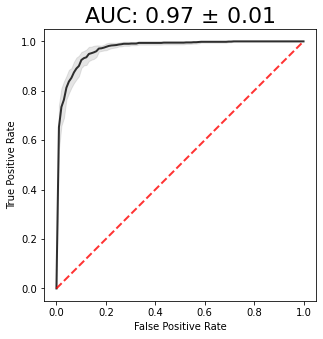

      Accuracy  Precision    Recall  Specificity     AUROC
mean  0.918752   0.869297  0.940849     0.903623  0.969925
std   0.019790   0.054449  0.027643     0.034230  0.006732
0.9721048776462474


In [22]:
from sklearn.model_selection import KFold, GroupKFold

model = lgb.LGBMClassifier()

X_categorical_col=[]
n_sm=5
n_cv=10
seed=42
figsize=(5,5)
prex_axTitle="AUC"
X=HP_train[all_features].reset_index(drop=True)
y=HP_train['label'].reset_index(drop=True)
ID = HP_train['ID']

#X=patient_data.iloc[index_healtyOrPolyp].reset_index(drop=True)
#y=patient_data.iloc[index_healtyOrPolyp]['label'].reset_index(drop=True)
#fileName="default.pdf"
chance=True

# 予測精度を視覚的に評価するために、ROCカーブをプロットする
#cv = StratifiedKFold(n_splits=n_cv,shuffle=True,random_state=seed)
gkf = GroupKFold(n_splits = n_cv)
groups = np.array(ID)

tprs,aucs,other_metrics, rocaucs, cv_pred, imputed_test, visitday, get_misc = [],[],[], [], [], [], [], []
mean_fpr = np.linspace(0, 1, 100)

#fig, ax = plt.subplots(figsize=figsize)
for i, (train, test) in enumerate(gkf.split(X, y, groups)):
    X_train, X_test, y_train, y_test = X.iloc[train,:], X.iloc[test,:], y[train], y[test]
    test_indices = y_test.index  
    get_misc.append(X_test)
    
   # Initialize the imputer
    imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')

    # Fit on training set and transform both training and testing sets
    X_train = imputer.fit_transform(X_train[all_features])  # Fit and transform training set
    X_test = imputer.transform(X_test[all_features])  # Transform test set (without fitting)

    # Convert back to DataFrame with original column names
    X_train = pd.DataFrame(X_train, columns=all_features)
    X_test = pd.DataFrame(X_test, columns=all_features)
    X_test['index'] = test_indices  # Save original indices for traceability
    imputed_test.append(X_test.copy())


    # SMOTE if needs
    if (n_sm != 0)&(X_categorical_col != []):
        sm = SMOTE(categorical_features=X_categorical_col,k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    elif (n_sm != 0)&(X_categorical_col == []):
        sm = SMOTE(k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    
    # Train the model
    model.fit(X_train,y_train)
    # Prediction 
    y_pred = model.predict_proba(X_test[all_features])[:,1]
    cv_pred.append(pd.Series(y_pred, index=test_indices))
    
    # Calculate ROC 
    fpr, tpr, threshold = roc_curve(y_test,y_pred)
    # Calculate best cutoff value
    youden = tpr-fpr
    cutoff = threshold[np.argmax(youden)]
    y_pred_binary = y_pred >= cutoff
    y_pred_binary = [int(i) for i in y_pred_binary]
    # Interporate tor
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    rocauc = roc_auc_score(y_test,y_pred, multi_class='ovr', average='macro')
    
    # Record each metrics
    accu,prec,sensi,speci = accuracy_score(y_test,y_pred_binary),precision_score(y_test,y_pred_binary),recall_score(y_test,y_pred_binary),specificity_score(y_test,y_pred_binary)
    print("y_test == y_pred_binary")
    print(y_test.values == np.array(y_pred_binary))
    other_metrics.append([accu,prec,sensi,speci])
    aucs.append(auc(fpr,tpr))
    rocaucs.append(rocauc)

fig, ax = plt.subplots(figsize=figsize)

# Calculate mean tpr for plotting
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
ax.plot(
    mean_fpr,
    mean_tpr,
    color="black",
    label="Mean ROC",
    lw=2,
    alpha=0.8,
)

# Calculate std using tprs and plot the shade
std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
ax.fill_between(
    mean_fpr,
    tprs_lower,
    tprs_upper,
    color="grey",
    alpha=0.2,
    label=r"$\pm$ 1 std. dev.",
)
if chance:
    ax.plot([0, 1], [0, 1], linestyle="--", lw=2, color="r", label="Chance", alpha=0.8)

ax.set(
    xlim=[-0.05, 1.05],
    ylim=[-0.05, 1.05],
    xlabel="False Positive Rate",
    ylabel="True Positive Rate"
)

# Calculate mean and std of AUROC
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)
mean_rocauc = np.mean(rocaucs)

ax.set_title(""+prex_axTitle+": %0.2f $\pm$ %0.2f" % (mean_auc, std_auc),fontsize=22)
#ax.legend(fontsize=16, bbox_to_anchor=(1, 0), loc='lower right', borderaxespad=1, frameon=False)
# ax.legend(loc="lower right")
plt.axis('square')
# ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()
#plt.savefig(fileName, bbox_inches="tight")
plt.close()


# Calculate mean and std of other metrics
mean_metrics = np.mean(other_metrics,axis=0).tolist()
mean_metrics.append(mean_auc)
std_metrics = np.std(other_metrics,axis=0).tolist()
std_metrics.append(std_auc)

evalMetrics = pd.DataFrame([mean_metrics,std_metrics],
                                   columns=["Accuracy","Precision","Recall","Specificity","AUROC"],
                                   index=["mean","std"])

print(evalMetrics)
print(mean_rocauc)

# HP tuning - Optuna 

In [23]:
X_train = HP_train[all_features]
y_train = HP_train['label']

In [25]:
import optuna
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline

def lgbm_objective(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 500, 1000),
        'max_depth': trial.suggest_int('max_depth', 3, 20),
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),
        'learning_rate': trial.suggest_float('learning_rate', 1e-3, 0.1, log=True),
        'objective': 'binary',
        'metric': 'auc',
        'random_state': 42,
        'verbosity': -1,
        'n_jobs': -1
    }
    model = Pipeline([
        ('imputer', KNNImputer(n_neighbors=5, weights='uniform')),
        ('smote', SMOTE(k_neighbors=5, random_state=42)),
        ('lgb', lgb.LGBMClassifier(**param))
    ])
    score = cross_val_score(model, X_train, y_train, cv=10, scoring='roc_auc', n_jobs=-1)
    return score.mean()

# Random Forest Objective
def rf_objective(trial):
    param = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 1000),
        'max_depth': trial.suggest_int('max_depth', 5, 30),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'random_state': 42,
        'n_jobs': -1
    }

    model = Pipeline([
        ('imputer', KNNImputer(n_neighbors=5, weights='uniform')),
        ('smote', SMOTE(k_neighbors=5, random_state=42)),
        ('rf', RandomForestClassifier(**param))
    ])

    score = cross_val_score(model, X_train, y_train, cv=10, scoring='roc_auc', n_jobs=-1)
    return score.mean()

# Logistic Regression Objective
def logreg_objective(trial):
    penalty = trial.suggest_categorical('penalty', ['l1', 'l2', 'elasticnet', 'none'])
    solver = trial.suggest_categorical('solver', ['liblinear', 'saga'])

    if penalty == 'elasticnet' and solver != 'saga':
        raise optuna.exceptions.TrialPruned()
    if penalty == 'none' and solver not in ['lbfgs', 'saga']:
        raise optuna.exceptions.TrialPruned()
    if penalty == 'l1' and solver not in ['liblinear', 'saga']:
        raise optuna.exceptions.TrialPruned()

    param = {
        'penalty': penalty,
        'C': trial.suggest_float('C', 1e-4, 10.0, log=True),
        'solver': solver,
        'l1_ratio': trial.suggest_float('l1_ratio', 0.0, 1.0) if penalty == 'elasticnet' else None,
        'max_iter': 1000,
        'random_state': 42
    }

    model = Pipeline([
        ('imputer', KNNImputer(n_neighbors=5, weights='uniform')),
        ('smote', SMOTE(k_neighbors=5, random_state=42)),
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(**param))
    ])

    score = cross_val_score(model, X_train, y_train, cv=10, scoring='roc_auc', n_jobs=-1)
    return score.mean()

# SVM Objective
def svm_objective(trial):
    kernel = trial.suggest_categorical('kernel', ['linear', 'rbf', 'poly', 'sigmoid'])
    param = {
        'C': trial.suggest_float('C', 1e-3, 10.0, log=True),
        'kernel': kernel,
        'probability': True,
        'random_state': 42
    }

    model = Pipeline([
        ('imputer', KNNImputer(n_neighbors=5, weights='uniform')),
        ('smote', SMOTE(k_neighbors=5, random_state=42)),
        ('scaler', StandardScaler()),
        ('svm', SVC(**param))
    ])

    if kernel != 'linear':
        param['gamma'] = trial.suggest_float('gamma', 1e-6, 1.0, log=True)
    if kernel == 'poly':
        param['degree'] = trial.suggest_int('degree', 2, 5)

    score = cross_val_score(model, X_train, y_train, cv=10, scoring='roc_auc', n_jobs=-1)
    return score.mean()

In [26]:
study_rf = optuna.create_study(direction='maximize')
study_rf.optimize(rf_objective, n_trials=50)
rf_best_params = study_rf.best_params

study_logreg = optuna.create_study(direction='maximize')
study_logreg.optimize(logreg_objective, n_trials=50)
logreg_best_params = study_logreg.best_params

study_svm = optuna.create_study(direction='maximize')
study_svm.optimize(svm_objective, n_trials=50)
svm_best_params = study_svm.best_params


[I 2025-09-08 12:53:34,931] A new study created in memory with name: no-name-9b45d15b-ec23-4887-b8f9-55d669496486
[I 2025-09-08 12:53:45,531] Trial 0 finished with value: 0.9418366897494932 and parameters: {'n_estimators': 730, 'max_depth': 13, 'min_samples_split': 6, 'min_samples_leaf': 3}. Best is trial 0 with value: 0.9418366897494932.
[I 2025-09-08 12:53:46,796] Trial 1 finished with value: 0.9316028678844127 and parameters: {'n_estimators': 135, 'max_depth': 16, 'min_samples_split': 9, 'min_samples_leaf': 10}. Best is trial 0 with value: 0.9418366897494932.
[I 2025-09-08 12:53:55,301] Trial 2 finished with value: 0.936505057020255 and parameters: {'n_estimators': 945, 'max_depth': 27, 'min_samples_split': 10, 'min_samples_leaf': 9}. Best is trial 0 with value: 0.9418366897494932.
[I 2025-09-08 12:53:58,833] Trial 3 finished with value: 0.9365900125716298 and parameters: {'n_estimators': 369, 'max_depth': 14, 'min_samples_split': 5, 'min_samples_leaf': 7}. Best is trial 0 with valu

In [28]:
study_lgbm = optuna.create_study(direction='maximize')
study_lgbm.optimize(lgbm_objective, n_trials=50)
lgb_best_params = study_lgbm.best_params

[I 2025-09-08 13:24:25,804] A new study created in memory with name: no-name-f7c12c36-0635-41fb-a74b-23553e986cb6


[I 2025-09-08 13:25:08,925] Trial 0 finished with value: 0.972664319564263 and parameters: {'n_estimators': 969, 'max_depth': 17, 'num_leaves': 42, 'learning_rate': 0.0769640587801169}. Best is trial 0 with value: 0.972664319564263.
[I 2025-09-08 13:25:51,410] Trial 1 finished with value: 0.970675516078846 and parameters: {'n_estimators': 876, 'max_depth': 7, 'num_leaves': 95, 'learning_rate': 0.08715692165060104}. Best is trial 0 with value: 0.972664319564263.
[I 2025-09-08 13:27:50,218] Trial 2 finished with value: 0.9397913363254411 and parameters: {'n_estimators': 742, 'max_depth': 11, 'num_leaves': 165, 'learning_rate': 0.0044327499262482774}. Best is trial 0 with value: 0.972664319564263.
[I 2025-09-08 13:29:01,437] Trial 3 finished with value: 0.9679202462964455 and parameters: {'n_estimators': 890, 'max_depth': 13, 'num_leaves': 132, 'learning_rate': 0.06392621689905263}. Best is trial 0 with value: 0.972664319564263.
[I 2025-09-08 13:29:52,064] Trial 4 finished with value: 0.9

In [31]:
lgb_best_params

{'n_estimators': 942,
 'max_depth': 18,
 'num_leaves': 19,
 'learning_rate': 0.09990756928055847}


Evaluating: Random Forest

Evaluating: SVM

Evaluating: Logistic Regression


/Users/kayharuni/anaconda3/envs/conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/kayharuni/anaconda3/envs/conda/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/kayharuni/anaconda3/envs/conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warnings.warn(
/Users/kayharuni/anaconda3/envs/conda/lib/python3.11/site-packages/sklearn/linear_model/_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/kayharuni/anaconda3/envs/conda/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1113: UserWarning: Setting penalty='none' will ignore the C and l1_ratio parameters
  warni


Evaluating: LightGBM
[LightGBM] [Info] Number of positive: 1419, number of negative: 1419
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003395 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11553
[LightGBM] [Info] Number of data points in the train set: 2838, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warn

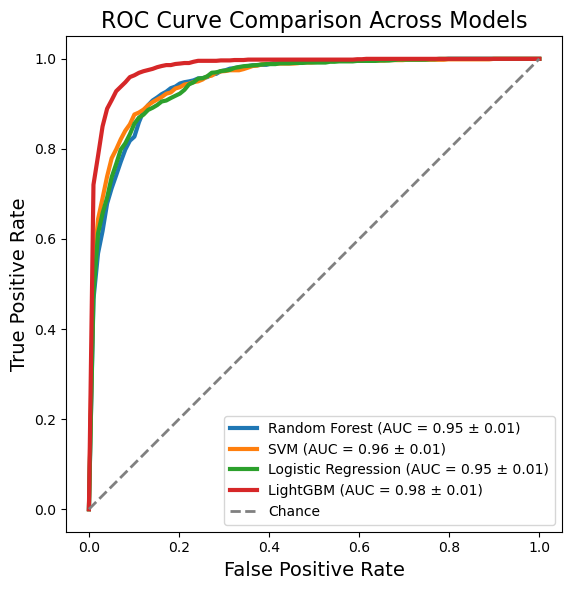

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import lightgbm as lgb

# Optional: define specificity
def specificity_score(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tn / (tn + fp)

# Basic settings
n_cv = 10
mean_fpr = np.linspace(0, 1, 100)
seed = 42
figsize = (8, 6)
eval_metrics = []

# Define X, y, and groups
X = HP_train.drop(['ID', 'visitday', 'label', 'CF', 'CF_eng', 'height'], axis=1).reset_index(drop=True)
y = HP_train['label'].reset_index(drop=True)
groups = HP_train['ID'].values

# Define consistent preprocessing pipelines for each model
models = {
    "Random Forest": ImbPipeline([
        ('imputer', KNNImputer(n_neighbors=5)),
        ('smote', SMOTE(k_neighbors=5, random_state=seed)),
        ('rf', RandomForestClassifier(**rf_best_params))
    ]),
    "SVM": ImbPipeline([
        ('imputer', KNNImputer(n_neighbors=5)),
        ('smote', SMOTE(k_neighbors=5, random_state=seed)),
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel = 'rbf', C = 6.638161971223862, gamma = 0.011258325988373194, probability=True))
    ]),
    "Logistic Regression": ImbPipeline([
        ('imputer', KNNImputer(n_neighbors=5)),
        ('smote', SMOTE(k_neighbors=5, random_state=seed)),
        ('scaler', StandardScaler()),
        ('logreg', LogisticRegression(**logreg_best_params)) #{k: v for k, v in logreg_best_params.items() if v is not None}
    ]),
    "LightGBM": ImbPipeline([
        ('imputer', KNNImputer(n_neighbors=5)),
        ('smote', SMOTE(k_neighbors=5, random_state=seed)),
        ('lgb', lgb.LGBMClassifier(**lgb_best_params))
    ])
}

# Initialize plot
fig, ax = plt.subplots(figsize=figsize)

# Evaluate each model
for model_name, model in models.items():
    print(f"\nEvaluating: {model_name}")
    tprs, aucs, other_metrics = [], [], []

    gkf = GroupKFold(n_splits=n_cv)
    for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        model.fit(X_train, y_train)
        y_score = model.predict_proba(X_test)[:, 1]

        # ROC curve and AUC
        fpr, tpr, threshold = roc_curve(y_test, y_score)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        aucs.append(auc(fpr, tpr))

        # Youden's J statistic for optimal threshold
        youden = tpr - fpr
        cutoff = threshold[np.argmax(youden)]
        y_pred_binary = (y_score >= cutoff).astype(int)

        # Metrics
        accu = accuracy_score(y_test, y_pred_binary)
        prec = precision_score(y_test, y_pred_binary)
        sensi = recall_score(y_test, y_pred_binary)
        speci = specificity_score(y_test, y_pred_binary)
        other_metrics.append([accu, prec, sensi, speci])

    # Summary statistics
    mean_tpr = np.mean(tprs, axis=0)
    std_tpr = np.std(tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = np.mean(aucs)
    std_auc = np.std(aucs)

    mean_metrics = np.mean(other_metrics, axis=0).tolist()
    std_metrics = np.std(other_metrics, axis=0).tolist()
    mean_metrics.append(mean_auc)
    std_metrics.append(std_auc)
    eval_metrics.append(mean_metrics)

    # Plot
    ax.plot(mean_fpr, mean_tpr, lw=3,
            label=f"{model_name} (AUC = {mean_auc:.2f} ± {std_auc:.2f})")

# Finalize plot
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", lw=2, label="Chance")
ax.set_xlim([-0.05, 1.05])
ax.set_ylim([-0.05, 1.05])
ax.set_xlabel("False Positive Rate", size=14)
ax.set_ylabel("True Positive Rate", size=14)
ax.set_title("ROC Curve Comparison Across Models", size=16)
ax.legend(loc="lower right")
plt.axis("square")
plt.tight_layout()
plt.show()


In [39]:
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).flatten()
    return tn / (tn + fp)

[LightGBM] [Info] Number of positive: 1419, number of negative: 1419
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005996 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11553
[LightGBM] [Info] Number of data points in the train set: 2838, number of used features: 48
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits

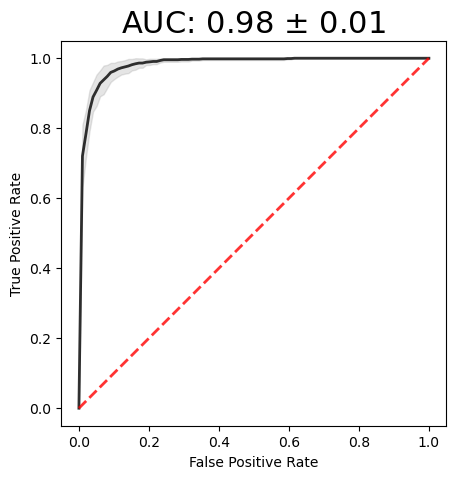

      Accuracy  Precision    Recall  Specificity     AUROC
mean  0.942068   0.906545  0.955216     0.932712  0.980738
std   0.011149   0.027937  0.027695     0.022453  0.005364
0.9837125114925855


In [65]:
from sklearn.model_selection import KFold, GroupKFold

model = lgb.LGBMClassifier(**lgb_best_params)

X_categorical_col=[]
n_sm=5
n_cv=10
seed=42
figsize=(5,5)
prex_axTitle="AUC"
X=HP_train[all_features].reset_index(drop=True)
y=HP_train['label'].reset_index(drop=True)
ID = HP_train['ID']

#X=patient_data.iloc[index_healtyOrPolyp].reset_index(drop=True)
#y=patient_data.iloc[index_healtyOrPolyp]['label'].reset_index(drop=True)
#fileName="default.pdf"
chance=True

# 予測精度を視覚的に評価するために、ROCカーブをプロットする
#cv = StratifiedKFold(n_splits=n_cv,shuffle=True,random_state=seed)
gkf = GroupKFold(n_splits = n_cv)
groups = np.array(ID)

tprs,aucs,other_metrics, rocaucs, cv_pred, imputed_test, visitday, get_misc = [],[],[], [], [], [], [], []
mean_fpr = np.linspace(0, 1, 100)

#fig, ax = plt.subplots(figsize=figsize)
for i, (train, test) in enumerate(gkf.split(X, y, groups)):
    X_train, X_test, y_train, y_test = X.iloc[train,:], X.iloc[test,:], y[train], y[test]
    test_indices = y_test.index  
    get_misc.append(X_test)
    
   # Initialize the imputer
    imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')

    # Fit on training set and transform both training and testing sets
    X_train = imputer.fit_transform(X_train[all_features])  # Fit and transform training set
    X_test = imputer.transform(X_test[all_features])  # Transform test set (without fitting)

    # Convert back to DataFrame with original column names
    X_train = pd.DataFrame(X_train, columns=all_features)
    X_test = pd.DataFrame(X_test, columns=all_features)
    X_test['index'] = test_indices  # Save original indices for traceability
    imputed_test.append(X_test.copy())


    # SMOTE if needs
    if (n_sm != 0)&(X_categorical_col != []):
        sm = SMOTE(categorical_features=X_categorical_col,k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    elif (n_sm != 0)&(X_categorical_col == []):
        sm = SMOTE(k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    
    # Train the model
    model.fit(X_train,y_train)
    # Prediction 
    y_pred = model.predict_proba(X_test[all_features])[:,1]
    cv_pred.append(pd.Series(y_pred, index=test_indices))
    
    # Calculate ROC 
    fpr, tpr, threshold = roc_curve(y_test,y_pred)
    # Calculate best cutoff value
    youden = tpr-fpr
    cutoff = threshold[np.argmax(youden)]
    y_pred_binary = y_pred >= cutoff
    y_pred_binary = [int(i) for i in y_pred_binary]
    # Interporate tor
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    rocauc = roc_auc_score(y_test,y_pred, multi_class='ovr', average='macro')
    
    # Record each metrics
    accu,prec,sensi,speci = accuracy_score(y_test,y_pred_binary),precision_score(y_test,y_pred_binary),recall_score(y_test,y_pred_binary),specificity_score(y_test,y_pred_binary)
    print("y_test == y_pred_binary")
    print(y_test.values == np.array(y_pred_binary))
    other_metrics.append([accu,prec,sensi,speci])
    aucs.append(auc(fpr,tpr))
    rocaucs.append(rocauc)

fig, ax = plt.subplots(figsize=figsize)

# Calculate mean tpr for plotting
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
ax.plot(
    mean_fpr,
    mean_tpr,
    color="black",
    label="Mean ROC",
    lw=2,
    alpha=0.8,
)

# Calculate std using tprs and plot the shade
std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
ax.fill_between(
    mean_fpr,
    tprs_lower,
    tprs_upper,
    color="grey",
    alpha=0.2,
    label=r"$\pm$ 1 std. dev.",
)
if chance:
    ax.plot([0, 1], [0, 1], linestyle="--", lw=2, color="r", label="Chance", alpha=0.8)

ax.set(
    xlim=[-0.05, 1.05],
    ylim=[-0.05, 1.05],
    xlabel="False Positive Rate",
    ylabel="True Positive Rate"
)

# Calculate mean and std of AUROC
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)
mean_rocauc = np.mean(rocaucs)

ax.set_title(""+prex_axTitle+": %0.2f $\pm$ %0.2f" % (mean_auc, std_auc),fontsize=22)
#ax.legend(fontsize=16, bbox_to_anchor=(1, 0), loc='lower right', borderaxespad=1, frameon=False)
# ax.legend(loc="lower right")
plt.axis('square')
# ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()
#plt.savefig(fileName, bbox_inches="tight")
plt.close()


# Calculate mean and std of other metrics
mean_metrics = np.mean(other_metrics,axis=0).tolist()
mean_metrics.append(mean_auc)
std_metrics = np.std(other_metrics,axis=0).tolist()
std_metrics.append(std_auc)

evalMetrics = pd.DataFrame([mean_metrics,std_metrics],
                                   columns=["Accuracy","Precision","Recall","Specificity","AUROC"],
                                   index=["mean","std"])

print(evalMetrics)
print(mean_rocauc)

In [41]:
lgb_best_params

{'n_estimators': 942,
 'max_depth': 18,
 'num_leaves': 19,
 'learning_rate': 0.09990756928055847}

# Feature selection 

In [23]:
lgb_best_params = {'n_estimators': 942,
 'max_depth': 18,
 'num_leaves': 19,
 'learning_rate': 0.09990756928055847}

In [25]:
from powershap import PowerShap
from collections import Counter

In [26]:
n_cv=10
n_tree= 500
n_synth = 10000
seed = 42
sm_k = 6
figsize = (5,5)

y = HP_train['label'].reset_index(drop=True)
X = HP_train[all_features].reset_index(drop=True)
ID = HP_train['ID'].reset_index(drop=True)


#cv = StratifiedKFold(n_splits=n_cv,shuffle=True,random_state=seed)
# cv = LeaveOneOut()
gkf = GroupKFold(n_splits = n_cv)
groups = np.array(ID)

sm = SMOTE(k_neighbors=sm_k,random_state=seed)

selectedFeatures,aurocs = [],[]

for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
    if type(X) == pd.Series:
        X_train = X.iloc[train_idx].reset_index(drop=True)
        X_test = X.iloc[test_idx].reset_index(drop=True)
    else:
        X_train = X.iloc[train_idx,:].reset_index(drop=True)
        X_test = X.iloc[test_idx,:].reset_index(drop=True)

    # Initialize the imputer
    imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')

    # Fit on training set and transform both training and testing sets
    X_train = imputer.fit_transform(X_train)  # Fit and transform training set
    X_test = imputer.transform(X_test)  # Transform test set (without fitting)

    # Convert back to DataFrame with original column names
    X_train = pd.DataFrame(X_train, columns=X.columns)
    X_test = pd.DataFrame(X_test, columns=X.columns)

    y_train = y[train_idx].reset_index(drop=True)
    y_test = y[test_idx].reset_index(drop=True)

    # inner loopに対してSMOTEを適用（つまりtrainだけ）
    kX_train, ky_train = sm.fit_resample(X_train, y_train)
    # print(len(ky_train[ky_train==1]),len(ky_train[ky_train==0]),kX_train.shape,ky_train.shape)
    model = lgb.LGBMClassifier(**lgb_best_params)

    # PowerShap feature selection
    selector = PowerShap(model=model, power_iterations=500, correction='bonferroni')
    selector.fit(kX_train, ky_train)

    kX_train_selected = selector.transform(kX_train)
    X_test_selected = selector.transform(X_test)

    # Track selected features
    selectedFeatures.append((kX_train_selected.columns))

    # Train on selected features
    model.fit(kX_train_selected, ky_train)

    # Predict
    y_pred = model.predict_proba(X_test_selected)[:, 1]
    auc = roc_auc_score(y_test, y_pred)
    aurocs.append(auc)

from collections import Counter
print(Counter(np.concatenate(selectedFeatures).tolist()))
print("AUROC: ",round(np.array(aurocs).mean(),3),"("+str(round(np.array(aurocs).std(),3))+")")

  0%|          | 0/10 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 1149, number of negative: 1121
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001190 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11765
[LightGBM] [Info] Number of data points in the train set: 2270, number of used features: 49
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.506167 -> initscore=0.024671
[LightGBM] [Info] Start training from score 0.024671
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
 10%|█         | 1/10 [00:01<00:16,  1.81s/it]

[LightGBM] [Info] Number of positive: 1135, number of negative: 1135
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000467 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11786
[LightGBM] [Info] Number of data points in the train set: 2270, number of used features: 49
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
 20%|██        | 2/10 [00:03<00:14,  1.83s/it]

[LightGBM] [Info] Number of positive: 1124, number of negative: 1146
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000463 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11792
[LightGBM] [Info] Number of data points in the train set: 2270, number of used features: 49
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.495154 -> initscore=-0.019384
[LightGBM] [Info] Start training from score -0.019384
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

... (336 outputs left out)

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
 90%|█████████ | 9/10 [00:16<00:01,  1.88s/it]

[LightGBM] [Info] Number of positive: 1141, number of negative: 1137
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000581 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11798
[LightGBM] [Info] Number of data points in the train set: 2278, number of used features: 49
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500878 -> initscore=0.003512
[LightGBM] [Info] Start training from score 0.003512
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
100%|██████████| 10/10 [00:18<00:00,  1.87s/it]


[LightGBM] [Info] Number of positive: 1424, number of negative: 1424
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000497 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 9057
[LightGBM] [Info] Number of data points in the train set: 2848, number of used features: 37
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits 

In [87]:
from collections import Counter
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.impute import KNNImputer
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold
from imblearn.over_sampling import SMOTE
from powershap import PowerShap  # make sure correct import

# Parameters
n_cv = 10
seed = 42
sm_k = 6

# Data
y = HP_train['label'].reset_index(drop=True)
X = HP_train[all_features].reset_index(drop=True)
ID = HP_train['ID'].reset_index(drop=True)

# CV + SMOTE
gkf = GroupKFold(n_splits=n_cv)
groups = np.array(ID)
sm = SMOTE(k_neighbors=sm_k, random_state=seed)

# Results
selectedFeatures = []
aurocs = []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
    print(f"\n--- Fold {fold+1}/{n_cv} ---")

    # Split
    X_train, X_test = X.iloc[train_idx, :], X.iloc[test_idx, :]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Imputation
    imputer = KNNImputer(n_neighbors=5, metric='nan_euclidean')
    X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)
    X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns)

    # SMOTE (only on training)
    kX_train, ky_train = sm.fit_resample(X_train, y_train)

    # New model instance per fold
    model = lgb.LGBMClassifier(**lgb_best_params)

    # PowerShap feature selection
    selector = PowerShap(model=model, power_iterations=500, correction='bonferroni')
    selector.fit(kX_train, ky_train)

    kX_train_selected = selector.transform(kX_train)
    X_test_selected = selector.transform(X_test)

    # Track selected features
    selectedFeatures.append(set(kX_train_selected.columns))

    # Train on selected features
    model.fit(kX_train_selected, ky_train)

    # Predict
    y_pred = model.predict_proba(X_test_selected)[:, 1]
    auc = roc_auc_score(y_test, y_pred)
    aurocs.append(auc)

    print(f"Fold {fold+1} AUROC: {auc:.3f} | Features: {len(kX_train_selected.columns)}")

# Aggregate feature stability
flat_features = [f for fold_feats in selectedFeatures for f in fold_feats]
feature_counts = Counter(flat_features)

print("\n=== Results ===")
print("AUROC: ", round(np.mean(aurocs), 3), " (±", round(np.std(aurocs), 3), ")")
print("Top features:", feature_counts.most_common(10))



--- Fold 1/10 ---


  0%|          | 0/10 [00:00<?, ?it/s]

[LightGBM] [Info] Number of positive: 1149, number of negative: 1121
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.010033 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11765
[LightGBM] [Info] Number of data points in the train set: 2270, number of used features: 49
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.506167 -> initscore=0.024671
[LightGBM] [Info] Start training from score 0.024671
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, b

/Users/kayharuni/anaconda3/envs/conda/lib/python3.11/site-packages/shap/explainers/_tree.py:583: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  


[LightGBM] [Info] Number of positive: 1135, number of negative: 1135
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000670 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11786
[LightGBM] [Info] Number of data points in the train set: 2270, number of used features: 49
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits

/Users/kayharuni/anaconda3/envs/conda/lib/python3.11/site-packages/shap/explainers/_tree.py:583: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  


... (80 outputs left out)

[LightGBM] [Info] Number of positive: 1114, number of negative: 1130
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000668 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11723
[LightGBM] [Info] Number of data points in the train set: 2244, number of used features: 49
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.496435 -> initscore=-0.014260
[LightGBM] [Info] Start training from score -0.014260
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

/Users/kayharuni/anaconda3/envs/conda/lib/python3.11/site-packages/shap/explainers/_tree.py:583: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  


[LightGBM] [Info] Number of positive: 1133, number of negative: 1111
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000512 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11721
[LightGBM] [Info] Number of data points in the train set: 2244, number of used features: 49
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.504902 -> initscore=0.019608
[LightGBM] [Info] Start training from score 0.019608


KeyboardInterrupt: 

In [27]:
featureDict = dict(Counter(np.concatenate(selectedFeatures).tolist()))
featureCountDF = pd.DataFrame({"name":featureDict.keys(),"value":featureDict.values()})
featureOver1 = featureCountDF[featureCountDF["value"]>=1]["name"]
featureOver2 = featureCountDF[featureCountDF["value"]>=2]["name"]
featureOver10 = featureCountDF[featureCountDF["value"]>=10]["name"]
featureOver10.values

array(['age', 'weight', 'SW', 'blood_pressure_sitting_up',
       'blood_pressure_sitting_down', 'wbc', 'lymph', 'mono', 'basophil',
       'MCV', 'MCHC', 'total_cho', 'HDL', 'neutral_fat',
       'blood_sugar_hungry', 'protein_a1', 'protein_a2', 'protein_r',
       'total_bil', 'cholinesterase', 'GOT', 'GPT', 'r_GTP', 'LAP',
       'urea_N', 'Cr', 'Cl', 'Ca', 'PH', 'urine_ratio'], dtype=object)

In [28]:
len(featureOver10)

30

In [29]:
from powershap import PowerShap
from sklearn.metrics import roc_auc_score
import shap

n_cv=10
seed = 42
sm_k = 6


y = HP_train['label'].reset_index(drop=True)
X = HP_train[featureOver10].reset_index(drop=True)
ID = HP_train['ID']

gkf = GroupKFold(n_splits = n_cv)
groups = np.array(ID)

model = lgb.LGBMClassifier(**lgb_best_params)
#cv = StratifiedKFold(n_splits=n_cv,shuffle=True,random_state=seed)
sm = SMOTE(k_neighbors=sm_k,random_state=seed)

aurocs,tprs,shap_values_array = [],[],[]
mean_fpr = np.linspace(0, 1, 100)
for fold, (train, test) in enumerate(gkf.split(X, y, groups)):
    if type(X) == pd.Series:
        X_train = X.iloc[train].reset_index(drop=True)
        X_test = X.iloc[test].reset_index(drop=True)
    else:
        X_train = X.iloc[train,:].reset_index(drop=True)
        X_test = X.iloc[test,:].reset_index(drop=True)

    imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')

    # Fit on training set and transform both training and testing sets
    X_train = imputer.fit_transform(X_train)  # Fit and transform training set
    X_test = imputer.transform(X_test)  # Transform test set (without fitting)

    # Convert back to DataFrame with original column names
    X_train = pd.DataFrame(X_train, columns=X.columns)
    X_test = pd.DataFrame(X_test, columns=X.columns)
    
    y_train = y[train].reset_index(drop=True)
    y_test = y[test].reset_index(drop=True)

    # inner loopに対してSMOTEを適用（つまりtrainだけ）
    kX_train, ky_train = sm.fit_resample(X_train, y_train)
    print(len(ky_train[ky_train==1]),len(ky_train[ky_train==0]),kX_train.shape,ky_train.shape)
    
    model.fit(kX_train, ky_train)
    y_pred = model.predict_proba(X_test)[:,1]
    fpr, tpr, threshold = roc_curve(y_test,y_pred)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    aurocs.append(roc_auc_score(y_test,y_pred))

    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_test)
    #shap_values = np.array(shap_values).transpose(2, 0, 1)[1]
    shap_values = shap_values[1]
    #shap_values_array.append(np.abs(shap_values).mean(0))
    shap_values_array.append(np.abs(shap_values).mean(axis=0))

from collections import Counter
print("AUROC: ",round(np.array(aurocs).mean(),3),"("+str(round(np.array(aurocs).std(),3))+")")

1419 1419 (2838, 30) (2838,)
[LightGBM] [Info] Number of positive: 1419, number of negative: 1419
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000788 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7447
[LightGBM] [Info] Number of data points in the train set: 2838, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM]

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray


1429 1429 (2858, 30) (2858,)
[LightGBM] [Info] Number of positive: 1429, number of negative: 1429
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000894 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7290
[LightGBM] [Info] Number of data points in the train set: 2858, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM]

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray


1403 1403 (2806, 30) (2806,)
[LightGBM] [Info] Number of positive: 1403, number of negative: 1403
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000563 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7227
[LightGBM] [Info] Number of data points in the train set: 2806, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM]

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray


... (10 outputs left out)

1433 1433 (2866, 30) (2866,)
[LightGBM] [Info] Number of positive: 1433, number of negative: 1433
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000855 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7320
[LightGBM] [Info] Number of data points in the train set: 2866, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM]

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray


1424 1424 (2848, 30) (2848,)
[LightGBM] [Info] Number of positive: 1424, number of negative: 1424
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000880 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7273
[LightGBM] [Info] Number of data points in the train set: 2848, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM]

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray


In [30]:
shap_values_array

[array([2.82074116, 1.21783452, 0.74512572, 0.37788692, 0.44936135,
        0.78694211, 2.74029136, 1.81204474, 0.43946105, 0.8310892 ,
        2.22756953, 1.10032059, 1.41774424, 0.82335931, 0.84961148,
        0.93848068, 0.76439619, 0.6291308 , 1.56688591, 0.75379194,
        0.64711229, 0.47840134, 0.85571348, 1.12308976, 1.67501308,
        1.43488278, 1.41581275, 1.29707296, 1.98447115, 0.39445014]),
 array([2.97574282, 1.12315251, 0.56388517, 0.31079224, 0.49896215,
        0.66624997, 3.04902666, 1.57317633, 0.45465818, 0.84363268,
        2.50600055, 1.21436318, 1.5129787 , 1.12483651, 0.89517516,
        1.09395944, 0.75036011, 0.51376981, 1.56253626, 0.74632387,
        0.60303185, 0.51545394, 0.92945488, 1.06560682, 1.93934788,
        1.32649934, 1.33627152, 1.30159457, 1.60756496, 0.43548826]),
 array([2.84018478, 1.28729612, 0.43766551, 0.37958261, 0.51690087,
        0.45993678, 3.03846103, 1.89075677, 0.46181798, 0.68071373,
        2.28669288, 1.02022005, 1.46107598, 

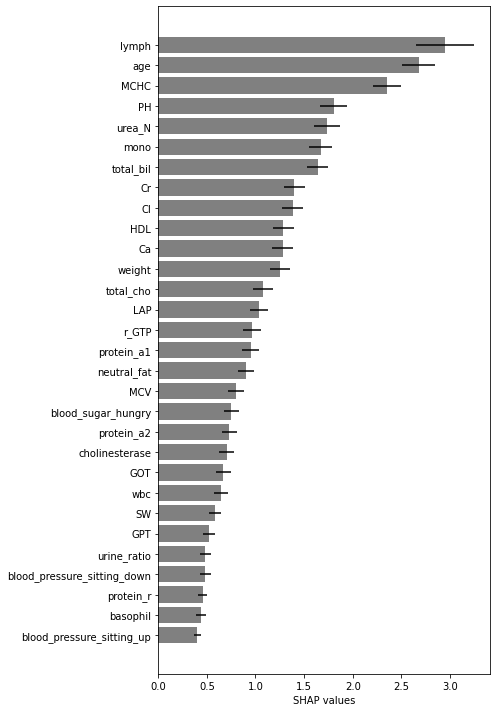

In [31]:
meanSHAP_DF = pd.DataFrame({"Feature":featureOver10,
                            "shapValue":np.array(shap_values_array).mean(0)}) 
meanSHAP_DF = meanSHAP_DF.sort_values("shapValue",ascending=True).reset_index(drop=True)

stdSHAP_DF = pd.DataFrame({"Feature":featureOver10,
                            "shapValue":np.array(shap_values_array).std(0)}) 
stdSHAP_DF = stdSHAP_DF.sort_values("shapValue",ascending=True).reset_index(drop=True)

plt.figure(figsize=(7,10))
plt.barh(meanSHAP_DF["Feature"],meanSHAP_DF["shapValue"],xerr=stdSHAP_DF["shapValue"],color="gray")
plt.xlabel("SHAP values")
plt.tight_layout()
# plt.savefig(path+"/results/GSover7_prediction/shap_KNN_1rm6weeks_FS.png",dpi=200)
plt.show()

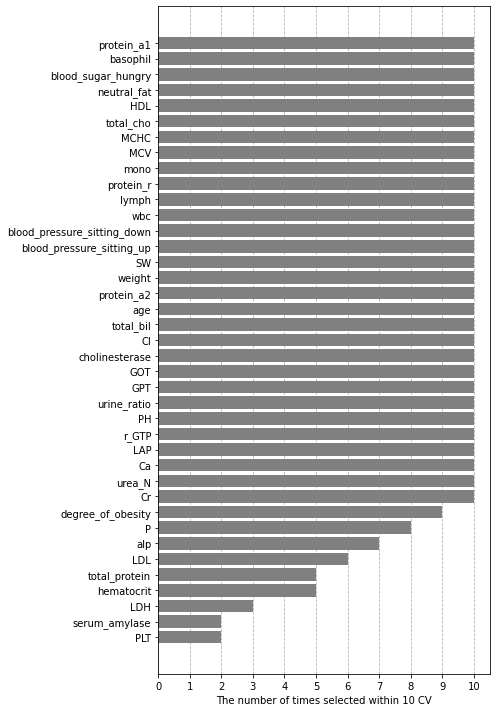

In [32]:
plt.figure(figsize=(7,10))
ax.set_axisbelow(True)
plt.barh(featureCountDF.sort_values("value",ascending=True)["name"],featureCountDF.sort_values("value",ascending=True)["value"],color="gray",zorder=2)
plt.xlabel("The number of times selected within 10 CV")
plt.xticks(range(0,11))
plt.grid(axis="x",linestyle="--",zorder=1)
plt.tight_layout()
# plt.savefig(path+"/results/GSover7_prediction/shap_KNN_1rm6weeks_FS_chosen.png",dpi=200)
plt.show()

# Summary patient characteristics 

In [516]:
patient_data = df_clean.copy()
all = patient_data.loc[(patient_data['label'] == 0) | (patient_data['label'] == 1)]
normal = patient_data.loc[patient_data['label'] == 0]
polyp = patient_data.loc[patient_data['label'] == 1]

In [517]:
from scipy.stats import mannwhitneyu

In [518]:
# age

collect_all_median, collect_normal_median, collect_polyp_median = [], [], []

collect_p = []

def pval_to_symb(pval):
    if pval < 0.0001:
        return '< 0.0001'
    elif pval < 0.001:
        return '< 0.001'
    elif pval < 0.01:
        return '< 0.01'
    elif pval < 0.05:
        return '< 0.05'
    else:
        return 'ns'  # not significant

for column in featureOver10:
    median_all, meadian_normal, median_polyp = np.nanmedian(all[column]), np.nanmedian(normal[column]), np.nanmedian(polyp[column])
    collect_all_median.append(median_all)
    collect_normal_median.append(meadian_normal)
    collect_polyp_median.append(median_polyp)
    stat, p_value = mannwhitneyu(normal[column].dropna(), polyp[column].dropna(), alternative='two-sided')
    symbol = pval_to_symb(p_value)
    collect_p.append(symbol)

In [522]:
df_characteristics = pd.DataFrame({
    'Feature': featureOver10,
    'Overall (n = 3197)': collect_all_median,
    'Normal (n = 1950)': collect_normal_median,
    'Polyp (n = 1247)': collect_polyp_median,
    'p-value': collect_p
})
df_characteristics.reset_index(drop=True)

,Feature,Overall (n = 3197),Normal (n = 1950),Polyp (n = 1247),p-value
0,age,61.000000,57.000000,67.000000,< 0.0001
1,weight,64.200000,62.400000,66.500000,< 0.0001
2,SW,60.800000,60.700000,61.500000,< 0.01
3,blood_pressure_sitting_up,120.000000,120.000000,122.000000,< 0.05
4,blood_pressure_sitting_down,74.000000,78.000000,73.000000,< 0.0001
5,wbc,5.200000,5.200000,5.200000,ns
6,lymph,37.000000,40.000000,32.900000,< 0.0001
7,mono,5.000000,5.000000,5.000000,< 0.0001
8,basophil,0.000000,0.000000,0.000000,ns
9,MCV,94.100000,93.500000,96.000000,< 0.0001


In [526]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [527]:
df_characteristics.to_excel('/Users/kayharuni/Desktop/df_characteristics.xlsx')

# how many features to reduce AUC score 

In [567]:
# please use only the features selected by powershap
patient_data = df_clean.copy()

# Get only healty or polyp patients
index_healtyOrPolyp = [i for i,x in enumerate(patient_data["label"]) if (x==0)|(x==1)]
index_others = [i for i,x in enumerate(patient_data["label"]) if x==999]

X_all = patient_data.drop(['height'],axis=1)
y_all = patient_data["label"]

X_healtyOrPolyp = X_all.iloc[index_healtyOrPolyp]
y_healtyOrPolyp = y_all.iloc[index_healtyOrPolyp]
X_Others = X_all.iloc[index_others]
y_Others = y_all.iloc[index_others]

X_train, X_test, y_train, y_test = train_test_split(X_healtyOrPolyp, y_healtyOrPolyp, test_size=0.05, random_state=42)
test_ID = X_test.ID.unique()
len(test_ID)
HP_df = patient_data.iloc[index_healtyOrPolyp]
HP_test = HP_df[HP_df['ID'].isin(test_ID)]
HP_train = HP_df[~HP_df['ID'].isin(test_ID)]
HP_test
print((len(HP_test)/len(X_healtyOrPolyp))*100)
all_features = df_clean.drop(['height', 'weight', 'CF', 'CF_eng', 'label', 'ID', 'visitday'], axis=1).columns

16.859555833593994


In [568]:
fs_df = meanSHAP_DF.sort_values("shapValue",ascending=False).reset_index(drop=True)

In [569]:
for i in range (len(fs_df),0, -1):
    print(fs_df.iloc[0:i]['Feature'])

0                           lymph
1                             age
2                            MCHC
3                              PH
4                            mono
5                       total_bil
6                          urea_N
7                              Cl
8                             HDL
9                              Ca
10                             Cr
11                            LAP
12                          r_GTP
13                      total_cho
14                     protein_a1
15                         weight
16                    neutral_fat
17             blood_sugar_hungry
18    blood_pressure_sitting_down
19                            MCV
20                     protein_a2
21                             SW
22                 cholinesterase
23                            wbc
24                    urine_ratio
25                            GOT
26              degree_of_obesity
Name: Feature, dtype: object
0                           lymph
1                  

In [570]:
len(meanSHAP_DF)

27

In [571]:
from sklearn.model_selection import KFold, GroupKFold

model = lgb.LGBMClassifier(**lgb_best_params)

X_categorical_col=[]
n_sm=5
n_cv=10
seed=42
figsize=(5,5)
prex_axTitle="AUC"
X=HP_train.reset_index(drop=True)
y=HP_train['label'].reset_index(drop=True)
ID = HP_train['ID']
fs_df = meanSHAP_DF.sort_values("shapValue",ascending=False).reset_index(drop=True)

chance=True

# 予測精度を視覚的に評価するために、ROCカーブをプロットする
#cv = StratifiedKFold(n_splits=n_cv,shuffle=True,random_state=seed)
gkf = GroupKFold(n_splits = n_cv)
groups = np.array(ID)

tprs,aucs,other_metrics, rocaucs, cv_pred, imputed_test, visitday, get_misc = [],[],[], [], [], [], [], []
collect_meanAUC, collect_lenFS = [], []

mean_fpr = np.linspace(0, 1, 100)


for j in range(len(fs_df), 0, -1):

    selected_features = fs_df.iloc[0:j]['Feature']

    for i, (train, test) in enumerate(gkf.split(X, y, groups)):
        X_train, X_test, y_train, y_test = X.iloc[train,:], X.iloc[test,:], y[train], y[test]
        test_indices = y_test.index  
        get_misc.append(X_test)
        
    # Initialize the imputer
        imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')

        # Fit on training set and transform both training and testing sets
        X_train = imputer.fit_transform(X_train[selected_features])  # Fit and transform training set
        X_test = imputer.transform(X_test[selected_features])  # Transform test set (without fitting)

        # Convert back to DataFrame with original column names
        X_train = pd.DataFrame(X_train, columns=selected_features)
        X_test = pd.DataFrame(X_test, columns=selected_features)
        X_test['index'] = test_indices  # Save original indices for traceability
        imputed_test.append(X_test.copy())


        # SMOTE if needs
        if (n_sm != 0)&(X_categorical_col != []):
            sm = SMOTE(categorical_features=X_categorical_col,k_neighbors=n_sm,random_state=seed)
            X_train,y_train = sm.fit_resample(X_train,y_train)
        elif (n_sm != 0)&(X_categorical_col == []):
            sm = SMOTE(k_neighbors=n_sm,random_state=seed)
            X_train,y_train = sm.fit_resample(X_train,y_train)
        
        # Train the model
        model.fit(X_train,y_train)
        # Prediction 
        y_pred = model.predict_proba(X_test[selected_features])[:,1]
        cv_pred.append(pd.Series(y_pred, index=test_indices))
        
        # Calculate ROC 
        fpr, tpr, threshold = roc_curve(y_test,y_pred)
        # Calculate best cutoff value
        youden = tpr-fpr
        cutoff = threshold[np.argmax(youden)]
        y_pred_binary = y_pred >= cutoff
        y_pred_binary = [int(i) for i in y_pred_binary]
        # Interporate tor
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        rocauc = roc_auc_score(y_test,y_pred, multi_class='ovr', average='macro')
        
        # Record each metrics
        accu,prec,sensi,speci = accuracy_score(y_test,y_pred_binary),precision_score(y_test,y_pred_binary),recall_score(y_test,y_pred_binary),specificity_score(y_test,y_pred_binary)
        print("y_test == y_pred_binary")
        print(y_test.values == np.array(y_pred_binary))
        other_metrics.append([accu,prec,sensi,speci])
        aucs.append(auc(fpr,tpr))
        rocaucs.append(rocauc)

    # Calculate mean tpr for plotting
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0

    # Calculate std using tprs and plot the shade
    std_tpr = np.std(tprs, axis=0)
    tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
    tprs_lower = np.maximum(mean_tpr - std_tpr, 0)


    # Calculate mean and std of AUROC
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(aucs)
    mean_rocauc = np.mean(rocaucs)

    # Calculate mean and std of other metrics
    mean_metrics = np.mean(other_metrics,axis=0).tolist()
    mean_metrics.append(mean_auc)
    std_metrics = np.std(other_metrics,axis=0).tolist()
    std_metrics.append(std_auc)

    #evalMetrics = pd.DataFrame([mean_metrics,std_metrics],
                                    #columns=["Accuracy","Precision","Recall","Specificity","AUROC"],
                                    #index=["mean","std"])

    collect_meanAUC.append(mean_auc)
    collect_lenFS.append(len(selected_features))


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
y_test == y_pred_binary
[ True  True  True  True  True  True  True  True  True  True  True  True
  T

In [572]:
collect_meanAUC

[0.9797309130550831,
 0.9794292218359136,
 0.9791696378584338,
 0.9791194584171193,
 0.9789885985565336,
 0.9791184890771157,
 0.9791456024421289,
 0.9791626664274193,
 0.9789936527587784,
 0.9787439291088198,
 0.9786268970075769,
 0.9786308389106433,
 0.9785809869928523,
 0.9785794460288245,
 0.9785099474770582,
 0.9784941906575173,
 0.9785268752818063,
 0.9783008556261418,
 0.9781625792718425,
 0.978023716270509,
 0.97781754478007,
 0.9770501966197707,
 0.9761800302113077,
 0.9752635215499714,
 0.9741764782407059,
 0.9731725164632843,
 0.9720316405622728]

Text(0, 0.5, 'mean AUC')

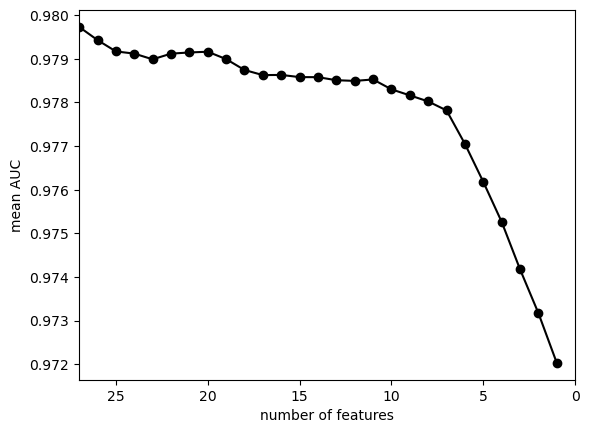

In [573]:
plt.plot(collect_lenFS, collect_meanAUC, color='black')
plt.scatter(collect_lenFS, collect_meanAUC, color='black')
plt.xlim(len(fs_df), 0)
plt.xlabel('number of features')
plt.ylabel('mean AUC')

In [574]:
from sklearn.model_selection import KFold, GroupKFold

model = lgb.LGBMClassifier(**lgb_best_params)

Need_smote=True
sm_k=5
figsize=(5,5)
chance=True
tprs,aucs,other_metrics, rocaucs, cv_pred, imputed_test, visitday, get_misc = [],[],[], [], [], [], [], []
collect_AUC, collect_lenFS = [], []

for j in range(len(fs_df), 0, -1):

    selected_features = fs_df.iloc[0:j]['Feature']

    X_train=HP_train[selected_features]
    X_test=HP_test[selected_features].astype(float)
    y_train=HP_train['label']
    y_test=HP_test['label']


    imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')

    # Fit on training set and transform both training and testing sets
    X_train_imputed = imputer.fit_transform(X_train)  # Fit and transform training set
    X_test_imputed = imputer.transform(X_test)  # Transform test set (without fitting)
    X_train = X_train_imputed.copy()
    X_test = X_test_imputed.copy()

    sm = SMOTE(k_neighbors=sm_k,random_state=seed)
    kX_tr, ky_tr = sm.fit_resample(X_train, y_train)

    model.fit(kX_tr, ky_tr)

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    # ROCカーブの計算
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
    roc_auc = auc(fpr, tpr)
    youden = tpr-fpr
    cutoff = thresholds[np.argmax(youden)]
    y_pred_binary = y_pred_prob >= cutoff
    y_pred_binary = [int(i>0.5) for i in y_pred_binary]
    
    rocauc = roc_auc_score(y_test,y_pred_prob)

    aucs.append(auc(fpr,tpr))

    collect_AUC.append(rocauc)
    collect_lenFS.append(len(selected_features))


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

Text(0, 0.5, 'AUC')

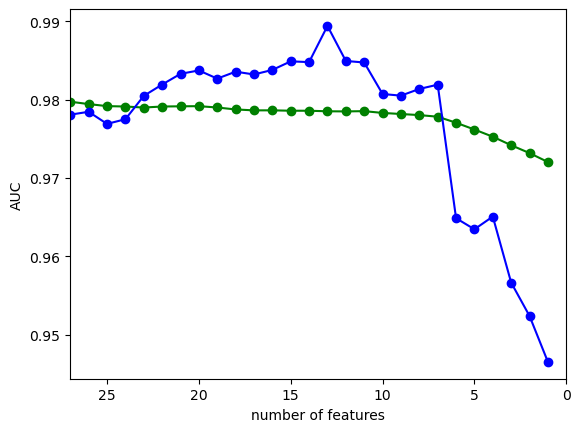

In [575]:
plt.plot(collect_lenFS, collect_meanAUC, color='green')
plt.scatter(collect_lenFS, collect_meanAUC, color='green')
plt.plot(collect_lenFS, collect_AUC, color='blue')
plt.scatter(collect_lenFS, collect_AUC, color='blue')
plt.xlim(len(fs_df), 0)
plt.xlabel('number of features')
plt.ylabel('AUC')

# Collecting the predicted proba of HvsP 

In [332]:
selected = ['age', 'MCHC', 'lymph', 'PH']

In [33]:
# please use only the features selected by powershap
patient_data = df_clean.copy()

# Get only healty or polyp patients
index_healtyOrPolyp = [i for i,x in enumerate(patient_data["label"]) if (x==0)|(x==1)]
index_others = [i for i,x in enumerate(patient_data["label"]) if x==999]

X_all = patient_data.drop(['height'],axis=1)
y_all = patient_data["label"]

X_healtyOrPolyp = X_all.iloc[index_healtyOrPolyp]
y_healtyOrPolyp = y_all.iloc[index_healtyOrPolyp]
X_Others = X_all.iloc[index_others]
y_Others = y_all.iloc[index_others]

X_train, X_test, y_train, y_test = train_test_split(X_healtyOrPolyp, y_healtyOrPolyp, test_size=0.05, random_state=42)
test_ID = X_test.ID.unique()
len(test_ID)
HP_df = patient_data.iloc[index_healtyOrPolyp]
HP_test = HP_df[HP_df['ID'].isin(test_ID)]
HP_train = HP_df[~HP_df['ID'].isin(test_ID)]
HP_test
print((len(HP_test)/len(X_healtyOrPolyp))*100)
all_features = df_clean.drop(['height', 'CF', 'CF_eng', 'label', 'ID', 'visitday'], axis=1).columns

16.859555833593994


In [34]:
lgb_best_params

{'n_estimators': 942,
 'max_depth': 18,
 'num_leaves': 19,
 'learning_rate': 0.09990756928055847}

In [35]:
from sklearn.model_selection import KFold, GroupKFold

model = lgb.LGBMClassifier(**lgb_best_params)
#model = lgb.LGBMClassifier(n_estimators=838)

X_categorical_col=[]
n_sm=5
n_cv=10
seed=42
figsize=(5,5)
prex_axTitle="AUC"
X=HP_train.reset_index(drop=True)
y=HP_train['label'].reset_index(drop=True)
ID = HP_train['ID']

#X=patient_data.iloc[index_healtyOrPolyp].reset_index(drop=True)
#y=patient_data.iloc[index_healtyOrPolyp]['label'].reset_index(drop=True)
#fileName="default.pdf"
chance=True

# 予測精度を視覚的に評価するために、ROCカーブをプロットする
#cv = StratifiedKFold(n_splits=n_cv,shuffle=True,random_state=seed)
gkf = GroupKFold(n_splits = n_cv)
groups = np.array(ID)

tprs,aucs,other_metrics, rocaucs, cv_pred, imputed_test, visitday, get_misc = [],[],[], [], [], [], [], []
mean_fpr = np.linspace(0, 1, 100)

#fig, ax = plt.subplots(figsize=figsize)
for i, (train, test) in enumerate(gkf.split(X, y, groups)):
    X_train, X_test, y_train, y_test = X.iloc[train,:], X.iloc[test,:], y[train], y[test]
    test_indices = y_test.index  
    get_misc.append(X_test)
    
   # Initialize the imputer
    imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')

    # Fit on training set and transform both training and testing sets
    X_train = imputer.fit_transform(X_train[featureOver10])  # Fit and transform training set
    X_test = imputer.transform(X_test[featureOver10])  # Transform test set (without fitting)

    # Convert back to DataFrame with original column names
    X_train = pd.DataFrame(X_train, columns=featureOver10)
    X_test = pd.DataFrame(X_test, columns=featureOver10)
    X_test['index'] = test_indices  # Save original indices for traceability
    imputed_test.append(X_test.copy())


    # SMOTE if needs
    if (n_sm != 0)&(X_categorical_col != []):
        sm = SMOTE(categorical_features=X_categorical_col,k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    elif (n_sm != 0)&(X_categorical_col == []):
        sm = SMOTE(k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    
    # Train the model
    model.fit(X_train,y_train)
    # Prediction 
    y_pred = model.predict_proba(X_test[featureOver10])[:,1]
    cv_pred.append(pd.Series(y_pred, index=test_indices))
    
    # Calculate ROC 
    fpr, tpr, threshold = roc_curve(y_test,y_pred)
    # Calculate best cutoff value
    youden = tpr-fpr
    cutoff = threshold[np.argmax(youden)]
    y_pred_binary = y_pred >= cutoff
    y_pred_binary = [int(i) for i in y_pred_binary]
    # Interporate tor
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    rocauc = roc_auc_score(y_test,y_pred, multi_class='ovr', average='macro')
    
    # Record each metrics
    accu,prec,sensi,speci = accuracy_score(y_test,y_pred_binary),precision_score(y_test,y_pred_binary),recall_score(y_test,y_pred_binary),specificity_score(y_test,y_pred_binary)
    print("y_test == y_pred_binary")
    print(y_test.values == np.array(y_pred_binary))
    other_metrics.append([accu,prec,sensi,speci])
    aucs.append(auc(fpr,tpr))
    rocaucs.append(rocauc)

fig, ax = plt.subplots(figsize=figsize)

# Calculate mean tpr for plotting
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
ax.plot(
    mean_fpr,
    mean_tpr,
    color="black",
    label="Mean ROC",
    lw=2,
    alpha=0.8,
)

# Calculate std using tprs and plot the shade
std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
ax.fill_between(
    mean_fpr,
    tprs_lower,
    tprs_upper,
    color="grey",
    alpha=0.2,
    label=r"$\pm$ 1 std. dev.",
)
if chance:
    ax.plot([0, 1], [0, 1], linestyle="--", lw=2, color="r", label="Chance", alpha=0.8)

ax.set(
    xlim=[-0.05, 1.05],
    ylim=[-0.05, 1.05],
    xlabel="False Positive Rate",
    ylabel="True Positive Rate"
)

# Calculate mean and std of AUROC
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)
mean_rocauc = np.mean(rocaucs)

ax.set_title(""+prex_axTitle+": %0.2f $\pm$ %0.2f" % (mean_auc, std_auc),fontsize=22)
#ax.legend(fontsize=16, bbox_to_anchor=(1, 0), loc='lower right', borderaxespad=1, frameon=False)
# ax.legend(loc="lower right")
plt.axis('square')
# ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()
#plt.savefig(fileName, bbox_inches="tight")
plt.close()


# Calculate mean and std of other metrics
mean_metrics = np.mean(other_metrics,axis=0).tolist()
mean_metrics.append(mean_auc)
std_metrics = np.std(other_metrics,axis=0).tolist()
std_metrics.append(std_auc)

evalMetrics = pd.DataFrame([mean_metrics,std_metrics],
                                   columns=["Accuracy","Precision","Recall","Specificity","AUROC"],
                                   index=["mean","std"])

print(evalMetrics)
print(mean_rocauc)

[LightGBM] [Info] Number of positive: 1419, number of negative: 1419
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000855 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7266
[LightGBM] [Info] Number of data points in the train set: 2838, number of used features: 30
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits 

TypeError: 'numpy.float64' object is not callable

In [395]:
# Combine imputed_test DataFrames
imputed_test_df = pd.concat(imputed_test, axis=0)
get_misc_df = pd.concat(get_misc, axis=0).sort_index()

# Combine cv_pred Series into a single Series
cv_pred_series = pd.concat(cv_pred, axis=0)

# Ensure both have matching indices (original row indices)
imputed_test_df = imputed_test_df.set_index('index').sort_index()
cv_pred_series = cv_pred_series.sort_index()

# Optional: reset index if you want a clean DataFrame
imputed_test_df = imputed_test_df.reset_index(drop=True)
cv_pred_series = cv_pred_series.reset_index(drop=True)
get_misc_df = get_misc_df.reset_index(drop=True)

# Add predictions to the imputed_test_df
imputed_test_df['probability'] = cv_pred_series
imputed_test_df['ID'] = get_misc_df['ID']
imputed_test_df['visitday'] = get_misc_df['visitday']
imputed_test_df['label'] = get_misc_df['label']
imputed_test_df['CF'] = get_misc_df['CF']
imputed_test_df['CF_eng'] = get_misc_df['CF_eng']
imputed_test_df

name,age,SW,degree_of_obesity,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,lymph,mono,basophil,MCV,...,Cl,Ca,PH,urine_ratio,probability,ID,visitday,label,CF,CF_eng
0,47.0,59.3,16.0,130.0,92.0,5.1,47.5,6.0,0.0,93.0,...,103.0,9.9,5.0,1.024,0.001511,119943677.0,1994-03-14,0.0,正常です。,Normal
1,57.0,51.9,-1.0,120.0,80.0,3.5,51.0,6.0,0.0,92.0,...,106.0,9.3,6.0,1.027,0.001460,113211594.0,1994-03-23,0.0,正常です。,Normal
2,37.0,54.7,13.0,120.0,82.0,4.4,39.0,3.0,0.0,93.0,...,105.0,9.6,5.5,1.029,0.000482,111769251.0,1994-03-31,0.0,正常です。,Normal
3,35.0,68.1,12.0,142.0,94.0,5.0,58.0,2.0,1.0,97.0,...,103.0,9.9,5.5,1.023,0.000012,105945004.0,1994-02-14,0.0,正常です。,Normal
4,56.0,62.8,12.0,138.0,82.0,4.6,39.0,8.0,0.0,99.0,...,101.0,9.3,6.0,1.023,0.133204,116667365.0,1994-02-15,0.0,正常です。,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2653,61.0,51.4,7.0,142.0,94.0,5.6,35.0,1.0,0.0,93.0,...,105.0,9.4,5.5,1.027,0.000323,105935243.0,1993-12-07,0.0,正常です。,Normal
2654,42.0,69.7,9.0,134.0,94.0,8.7,42.0,3.0,0.0,92.0,...,101.0,10.3,5.0,1.024,0.000051,101000706.0,1993-12-13,0.0,正常です。,Normal
2655,66.0,57.9,13.0,160.0,100.0,4.6,31.0,6.0,0.0,94.0,...,114.0,9.3,6.0,1.024,0.579432,113542555.0,1993-03-01,0.0,正常です。,Normal
2656,65.0,61.4,-2.0,140.0,82.0,5.0,43.0,3.0,0.0,90.0,...,105.0,9.2,6.5,1.023,0.000631,103650799.0,1993-03-03,0.0,正常です。,Normal


# Collect predicted proba of Others 

[LightGBM] [Info] Number of positive: 1578, number of negative: 1578
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.010165 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6751
[LightGBM] [Info] Number of data points in the train set: 3156, number of used features: 27
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


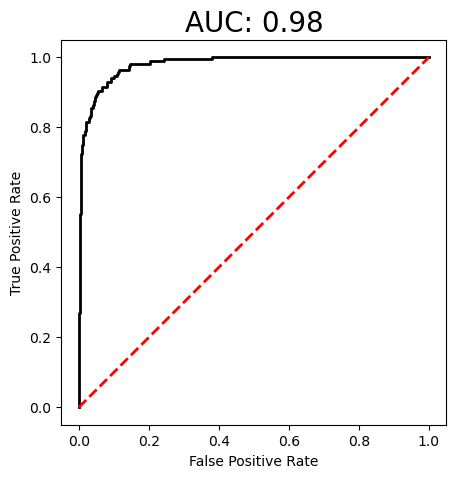

   Accuracy  Precision  Sensitivity  Specificity
0   0.93321   0.883041     0.904192     0.946237


In [396]:
#X_train, X_test, y_train, y_test = train_test_split(X_healtyOrPolyp, y_healtyOrPolyp, test_size=0.1, random_state=42)
#X_test_df = X_test.copy()

def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).flatten()
    return tn / (tn + fp)

clf = lgb.LGBMClassifier(**lgb_best_params)

seed=42
model=clf
X_train=HP_train[featureOver10]
X_test=HP_test[featureOver10].astype(float)
y_train=HP_train['label']
y_test=HP_test['label']

Need_smote=True
sm_k=5
figsize=(5,5)
chance=True
other_metrics=[]

imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')

# Fit on training set and transform both training and testing sets
X_train_imputed = imputer.fit_transform(X_train)  # Fit and transform training set
X_test_imputed = imputer.transform(X_test)  # Transform test set (without fitting)
X_train = X_train_imputed.copy()
X_test = X_test_imputed.copy()

sm = SMOTE(k_neighbors=sm_k,random_state=seed)
kX_tr, ky_tr = sm.fit_resample(X_train, y_train)


model.fit(kX_tr, ky_tr)
y_pred_prob = model.predict_proba(X_test)[:, 1]
# ROCカーブの計算
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)


youden = tpr-fpr
cutoff = thresholds[np.argmax(youden)]
y_pred_binary = y_pred_prob >= cutoff
y_pred_binary = [int(i>0.5) for i in y_pred_binary]

accu,prec,sensi,speci = accuracy_score(y_test,y_pred_binary),precision_score(y_test,y_pred_binary),recall_score(y_test,y_pred_binary),specificity_score(y_test,y_pred_binary)
other_metrics.append([accu,prec,sensi,speci])

evalMetrics = pd.DataFrame([{
    "Accuracy": accu,
    "Precision": prec,
    "Sensitivity": sensi,
    "Specificity": speci
}])


# ROCカーブのプロット
plt.figure(figsize=figsize)
plt.plot(fpr, tpr, color='black', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', size=10)
plt.ylabel('True Positive Rate', size=10)
plt.title(f'AUC: {roc_auc:.2f}', size=20)
# ax.legend(loc="lower right")
plt.axis('square')
# ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()
plt.close()
print(evalMetrics)

In [397]:
X_train=HP_train[featureOver10]
y_train=HP_train['label']
y_test=HP_test['label']
X_test=HP_test[featureOver10]

imp_test = pd.DataFrame(X_test_imputed, columns=featureOver10, index=X_test.index)
imp_test['probability'] = y_pred_prob
imp_test['ID'] = HP_test['ID']
imp_test['visitday'] = HP_test['visitday']
imp_test['label'] = HP_test['label']
imp_test['CF'] = HP_test['CF']
imp_test['CF_eng'] = HP_test['CF_eng']
imp_test

name,age,weight,SW,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,lymph,mono,basophil,MCV,...,Cl,Ca,PH,urine_ratio,probability,ID,visitday,label,CF,CF_eng
60,65.0,64.6,61.4,102.0,80.0,7.7,47.0,9.0,0.0,93.0,...,102.0,9.4,5.0,1.029,0.000067,101006590.0,1994-03-01,0.0,正常です。,Normal
79,51.0,62.6,61.4,140.0,90.0,4.2,47.0,8.0,0.0,94.0,...,106.0,9.6,5.0,1.024,0.000080,103655059.0,1994-03-08,0.0,正常です。,Normal
143,61.0,53.6,51.4,110.0,76.0,6.6,52.0,3.0,0.0,96.0,...,105.0,9.0,6.0,1.025,0.000075,126445175.0,1994-01-11,0.0,正常です。,Normal
164,61.0,66.1,64.3,96.0,70.0,6.4,54.0,3.0,0.0,93.0,...,103.0,9.1,6.5,1.024,0.000108,101000666.0,1994-03-30,0.0,正常です。,Normal
316,56.0,89.6,67.3,128.0,92.0,4.2,53.0,4.0,0.0,92.0,...,106.0,9.0,5.5,1.031,0.164295,112281910.0,1994-07-04,0.0,正常です。,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45623,50.0,74.1,69.7,152.0,80.0,6.6,41.0,2.0,0.0,96.0,...,102.0,9.5,6.0,1.021,0.005699,110035474.0,1993-09-06,0.0,正常です。,Normal
45645,59.0,77.1,65.8,128.0,72.0,3.6,52.0,8.0,0.0,96.0,...,102.0,9.5,6.0,1.028,0.047799,105925171.0,1993-07-15,0.0,正常です。,Normal
45721,54.0,49.1,51.0,102.0,70.0,5.4,55.0,2.0,1.0,94.0,...,102.0,9.8,6.5,1.020,0.000168,110191363.0,1993-08-10,0.0,正常です。,Normal
45769,39.0,71.5,65.8,112.0,72.0,4.0,44.0,3.0,0.0,85.0,...,102.0,9.6,5.5,1.029,0.004224,105925108.0,1993-06-14,0.0,正常です。,Normal


In [398]:
X_train=HP_train[featureOver10]
X_test=X_Others.loc[:,featureOver10]
y_train=HP_train['label']

Need_smote=True
sm_k=5
figsize=(5,5)
chance=True

noimp_others = X_Others

imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')

# Fit on training set and transform both training and testing sets
X_train_imputed = imputer.fit_transform(X_train)  # Fit and transform training set
X_test_imputed = imputer.transform(X_test)  # Transform test set (without fitting)
X_train = X_train_imputed.copy()
X_test = X_test_imputed.copy()

if Need_smote:
    sm = SMOTE(k_neighbors=sm_k,random_state=seed)
    kX_tr, ky_tr = sm.fit_resample(X_train, y_train)
else:
    kX_tr, ky_tr = X_train, y_train
    
y_pred_prob = model.predict_proba(X_test)[:, 1]

In [399]:
imp_others = pd.DataFrame(X_test_imputed, columns=featureOver10, index=index_others)
imp_others['probability'] = y_pred_prob
imp_others['ID'] = patient_data.iloc[index_others]['ID']
imp_others['visitday'] = patient_data.iloc[index_others]['visitday']
imp_others['label'] = patient_data.iloc[index_others]['label']
imp_others['CF'] = patient_data.iloc[index_others]['CF']
imp_others['CF_eng'] = patient_data.iloc[index_others]['CF_eng']
imp_others

name,age,weight,SW,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,lymph,mono,basophil,MCV,...,Cl,Ca,PH,urine_ratio,probability,ID,visitday,label,CF,CF_eng
0,62.0,69.5,61.4,186.0,96.0,5.1,41.0,1.0,1.0,101.0,...,105.0,9.2,5.5,1.024,0.000157,101000592.0,1994-01-07,999.0,NaN,NaN
1,61.0,52.1,54.2,104.0,64.0,3.8,50.0,3.0,0.0,103.0,...,101.0,9.6,5.0,1.016,0.003901,121209859.0,1994-01-07,999.0,NaN,NaN
2,62.0,56.9,52.8,124.0,80.0,4.7,26.0,7.0,0.0,91.0,...,104.0,8.7,5.0,1.014,0.000158,103655851.0,1994-03-14,999.0,経過観察が必要です。,Follow-up observation required
4,59.0,58.0,57.9,118.0,86.0,4.5,41.0,7.0,0.0,93.0,...,101.0,8.8,5.5,1.018,0.000188,105945035.0,1994-03-15,999.0,NaN,NaN
5,55.0,47.5,56.8,120.0,80.0,3.6,31.0,6.0,0.0,85.0,...,102.0,9.3,5.0,1.012,0.000015,126508115.0,1994-03-15,999.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45866,57.0,40.4,51.0,118.0,66.0,5.5,29.0,6.0,2.0,89.0,...,104.0,9.1,6.5,1.021,0.002970,105935014.0,1993-03-02,999.0,直腸に異常所見が認められます。,Abnormal findings in the rectum
45868,43.0,91.1,71.3,160.0,102.0,9.4,38.0,8.0,1.0,85.0,...,102.0,9.9,6.0,1.019,0.001697,105935023.0,1993-03-03,999.0,Ｓ字結腸は経過観察が必要です。,Sigmoid colon requires follow-up observation
45869,61.0,65.0,71.3,125.0,90.0,6.6,23.0,5.0,0.0,93.0,...,106.0,8.9,5.5,1.015,0.100859,101000524.0,1993-03-04,999.0,NaN,NaN
45870,57.0,72.0,64.3,115.0,76.0,5.7,53.0,4.0,0.0,98.0,...,106.0,9.4,5.0,1.022,0.001086,101012004.0,1993-03-04,999.0,結腸は経過観察が必要です。,Colon needs to be monitored


# combined df 

In [400]:
df_proba = pd.concat([imputed_test_df, imp_others, imp_test]).reset_index(drop=True)
df_proba

name,age,SW,degree_of_obesity,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,lymph,mono,basophil,MCV,...,Ca,PH,urine_ratio,probability,ID,visitday,label,CF,CF_eng,weight
0,47.0,59.3,16.0,130.0,92.0,5.1,47.5,6.0,0.0,93.0,...,9.9,5.0,1.024,0.001511,119943677.0,1994-03-14,0.0,正常です。,Normal,NaN
1,57.0,51.9,-1.0,120.0,80.0,3.5,51.0,6.0,0.0,92.0,...,9.3,6.0,1.027,0.001460,113211594.0,1994-03-23,0.0,正常です。,Normal,NaN
2,37.0,54.7,13.0,120.0,82.0,4.4,39.0,3.0,0.0,93.0,...,9.6,5.5,1.029,0.000482,111769251.0,1994-03-31,0.0,正常です。,Normal,NaN
3,35.0,68.1,12.0,142.0,94.0,5.0,58.0,2.0,1.0,97.0,...,9.9,5.5,1.023,0.000012,105945004.0,1994-02-14,0.0,正常です。,Normal,NaN
4,56.0,62.8,12.0,138.0,82.0,4.6,39.0,8.0,0.0,99.0,...,9.3,6.0,1.023,0.133204,116667365.0,1994-02-15,0.0,正常です。,Normal,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45868,50.0,69.7,NaN,152.0,80.0,6.6,41.0,2.0,0.0,96.0,...,9.5,6.0,1.021,0.005699,110035474.0,1993-09-06,0.0,正常です。,Normal,74.1
45869,59.0,65.8,NaN,128.0,72.0,3.6,52.0,8.0,0.0,96.0,...,9.5,6.0,1.028,0.047799,105925171.0,1993-07-15,0.0,正常です。,Normal,77.1
45870,54.0,51.0,NaN,102.0,70.0,5.4,55.0,2.0,1.0,94.0,...,9.8,6.5,1.020,0.000168,110191363.0,1993-08-10,0.0,正常です。,Normal,49.1
45871,39.0,65.8,NaN,112.0,72.0,4.0,44.0,3.0,0.0,85.0,...,9.6,5.5,1.029,0.004224,105925108.0,1993-06-14,0.0,正常です。,Normal,71.5


# time series 

In [401]:
df_proba = df_proba.sort_values(by=['ID', 'visitday'])

day = []

for patient in df_proba.ID.unique():
   patient_data = df_proba.loc[df_proba['ID'] == patient]
   for j in range(len(patient_data['visitday'])):
        delta = (patient_data['visitday'].iloc[j]) - (patient_data['visitday'].iloc[0])
        num_days = delta.days
        day.append(num_days)

df_proba['day'] = day

df_proba

name,age,SW,degree_of_obesity,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,lymph,mono,basophil,MCV,...,PH,urine_ratio,probability,ID,visitday,label,CF,CF_eng,weight,day
44890,42.0,72.1,NaN,152.0,94.0,5.80,44.0,5.0,1.0,95.0,...,5.0,1.023,0.000379,101000051.0,1993-04-08,999.0,NaN,NaN,84.2,0
2622,46.0,65.8,4.0,110.0,76.0,6.50,48.0,2.0,0.0,89.0,...,5.5,1.020,0.000495,101000052.0,1993-10-18,0.0,正常です。,Normal,NaN,0
44926,46.0,60.7,NaN,112.0,80.0,6.70,20.0,9.0,0.0,87.0,...,6.0,1.024,0.021098,101000053.0,1993-02-17,999.0,NaN,NaN,64.5,0
45208,46.0,60.7,NaN,122.0,80.0,6.20,37.0,5.0,0.0,90.0,...,6.0,1.030,0.014440,101000053.0,1993-08-12,999.0,結腸は経過観察が必要です。,Colon needs to be monitored,64.5,176
2714,47.0,60.7,NaN,110.0,74.0,5.10,44.0,6.0,1.0,88.0,...,8.0,1.023,0.003553,101000053.0,1994-03-02,999.0,NaN,NaN,64.5,378
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44427,49.0,67.2,NaN,117.0,78.0,4.09,37.7,5.0,0.0,93.5,...,6.0,1.023,0.839829,128284365.0,2019-04-12,999.0,異常なし,No abnormalities,76.7,0
44057,58.0,63.5,NaN,93.0,56.0,4.91,36.5,7.0,1.0,90.3,...,5.5,1.007,0.894816,128299563.0,2019-05-22,999.0,大腸憩室,Colonic diverticulum,66.7,0
43665,52.0,71.3,NaN,116.0,67.0,4.01,25.9,6.0,0.0,86.3,...,6.0,1.031,0.991010,128308722.0,2019-05-27,999.0,異常なし,No abnormalities,76.1,0
44452,37.0,61.6,NaN,101.0,67.0,4.69,32.2,3.0,0.0,84.2,...,5.5,1.026,0.011902,128330336.0,2019-06-03,999.0,NaN,NaN,56.9,0


In [402]:
df_proba['ID'] = df_proba['ID'].astype(int)
polPatient = (df_proba.loc[df_proba['label'] == 1])['ID'].unique()
uniquePatient = (df_proba.loc[(df_proba['label'] == 1) | (df_proba['label'] == 0)])['ID'].unique()
print(f'The number of unique patients {len(uniquePatient)}')
print(f'The number of unique patients with polyp is {len(polPatient)}')
print(f'The number of unique patients always healthy must be {len(uniquePatient)-len(polPatient)}')

The number of unique patients 1433
The number of unique patients with polyp is 726
The number of unique patients always healthy must be 707


In [376]:
df_proba['CF_eng'].value_counts([])

NaN                                           34132
Did not check this time                        3791
Follow-up observation required                 2237
Normal                                         1948
Colon polyps                                   1207
                                              ...  
Anal vascular malformations                       1
Suspected colonic diverticulum                    1
After colon surgery. Follow-up is required        1
Sigmoid colon is normal                           1
Suspected anal polyps                             1
Name: CF_eng, Length: 61, dtype: int64

In [618]:
noabn_ID = df_proba.loc[df_proba['CF_eng'] == 'No abnormalities'].ID.unique()

In [619]:
len(noabn_ID)

314

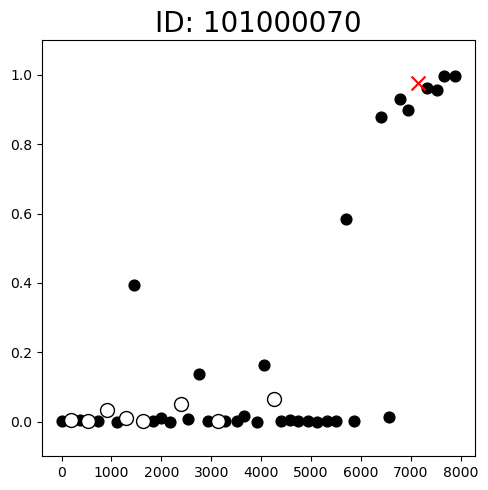

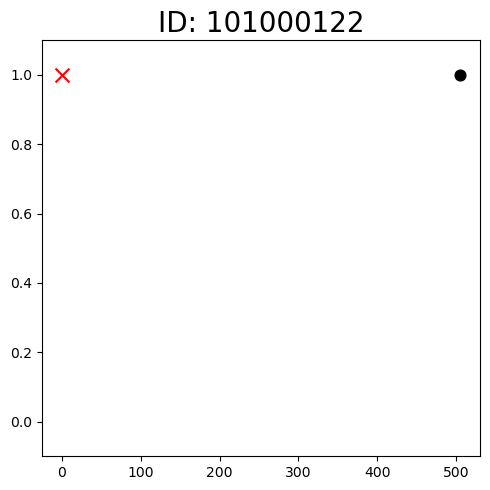

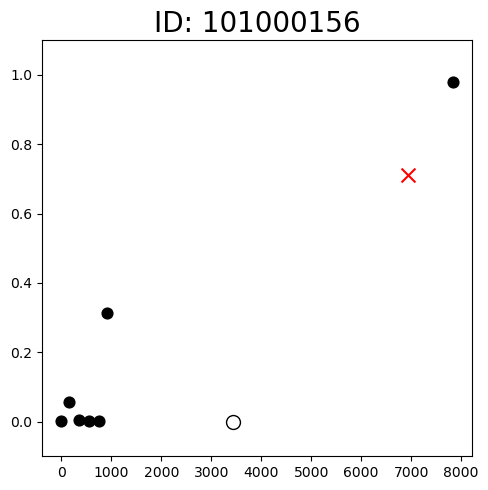

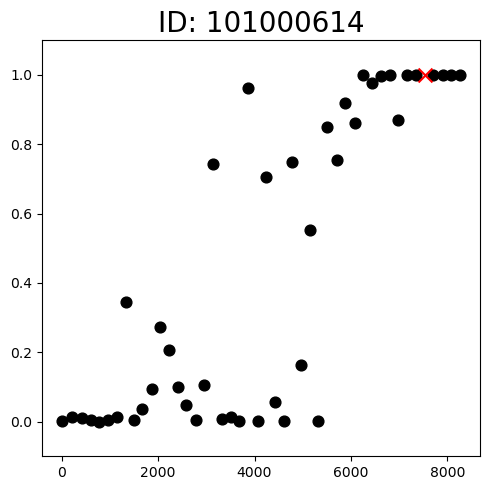

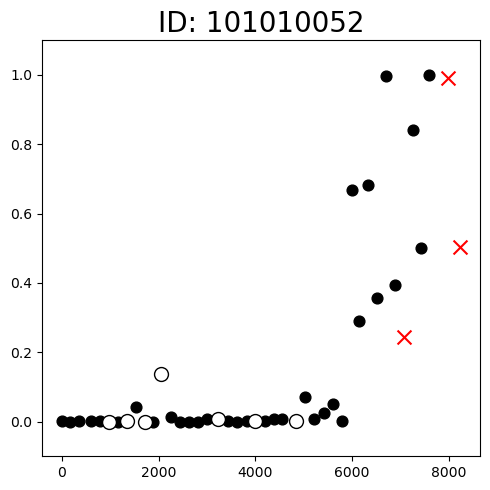

...

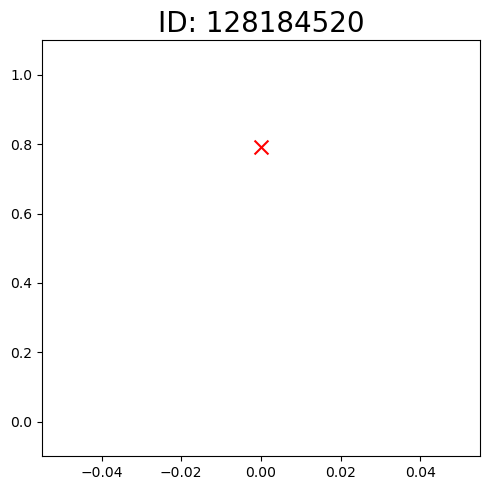

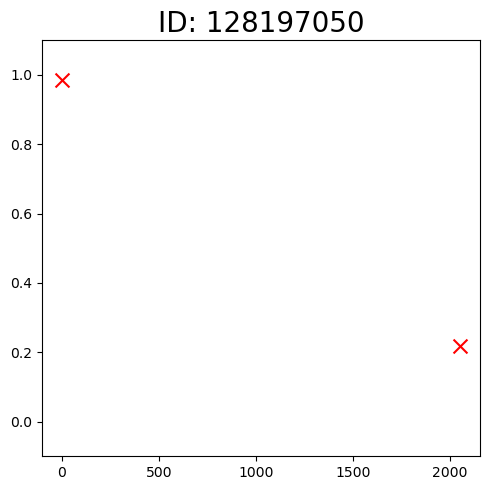

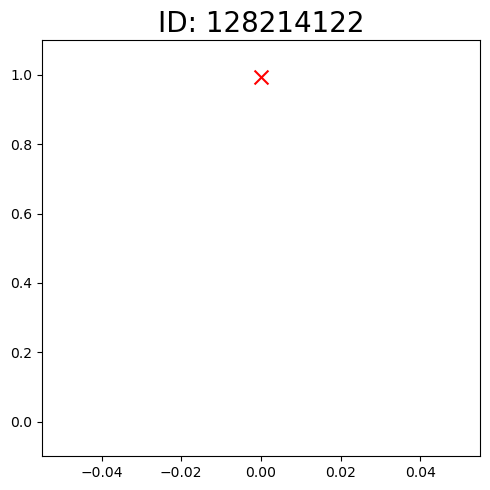

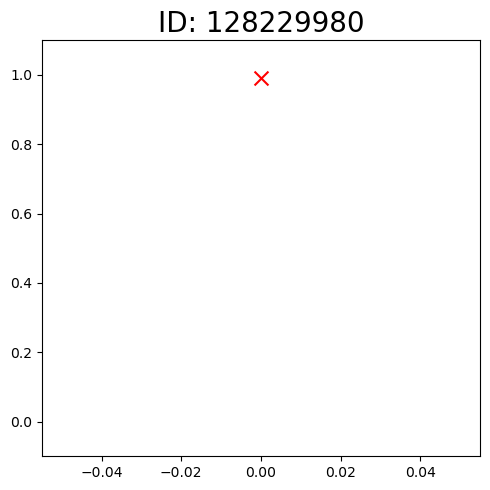

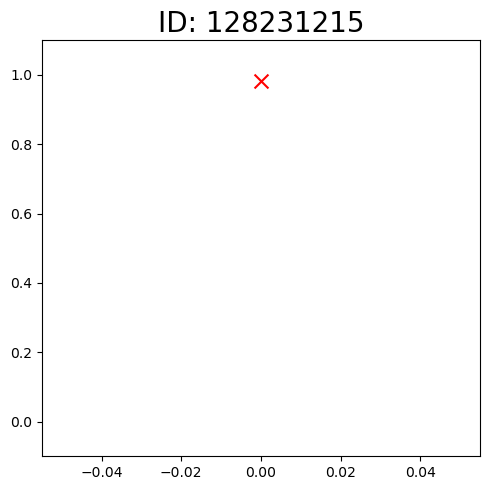

In [403]:
import matplotlib.pyplot as plt

# Set y-axis limits
y_min = -0.1
y_max = 1.1

for id in polPatient:
    fig, ax = plt.subplots(figsize=(5, 5))

    selection = df_proba[df_proba['ID'] == id]
    # Plot for each label
        
    if not selection[selection['label'] == 999].empty:
        ax.scatter(selection['day'][selection['label'] == 999],
                    selection['probability'][selection['label'] == 999],
                    marker='o', color='black', s=60)
        
    if not selection[selection['label'] == 0].empty:
        ax.scatter(selection['day'][selection['label'] == 0],
                    selection['probability'][selection['label'] == 0],
                    marker='o', edgecolors='black', facecolors='white', s=100)

    if not selection[selection['label'] == 1].empty:
        ax.scatter(selection['day'][selection['label'] == 1],
                    selection['probability'][selection['label'] == 1],
                    marker='x', color='red', s=100)
        
    #if not selection[selection['CF_eng'] == 'No abnormalities'].empty:
        #ax.scatter(selection['day'][selection['CF_eng'] == 'No abnormalities'],
                    #selection['probability'][selection['CF_eng'] == 'No abnormalities'],
                    #marker='^', color='orange', edgecolors='black', s=200)


    # Labels and limits
    ax.set_ylim(y_min, y_max)
    ax.set_title(f'ID: {id}', fontsize=20)
    plt.tight_layout()
    #plt.savefig(f'/Users/kayharuni/Desktop/June_July/noabn_patients/{id}.png')
    plt.show()

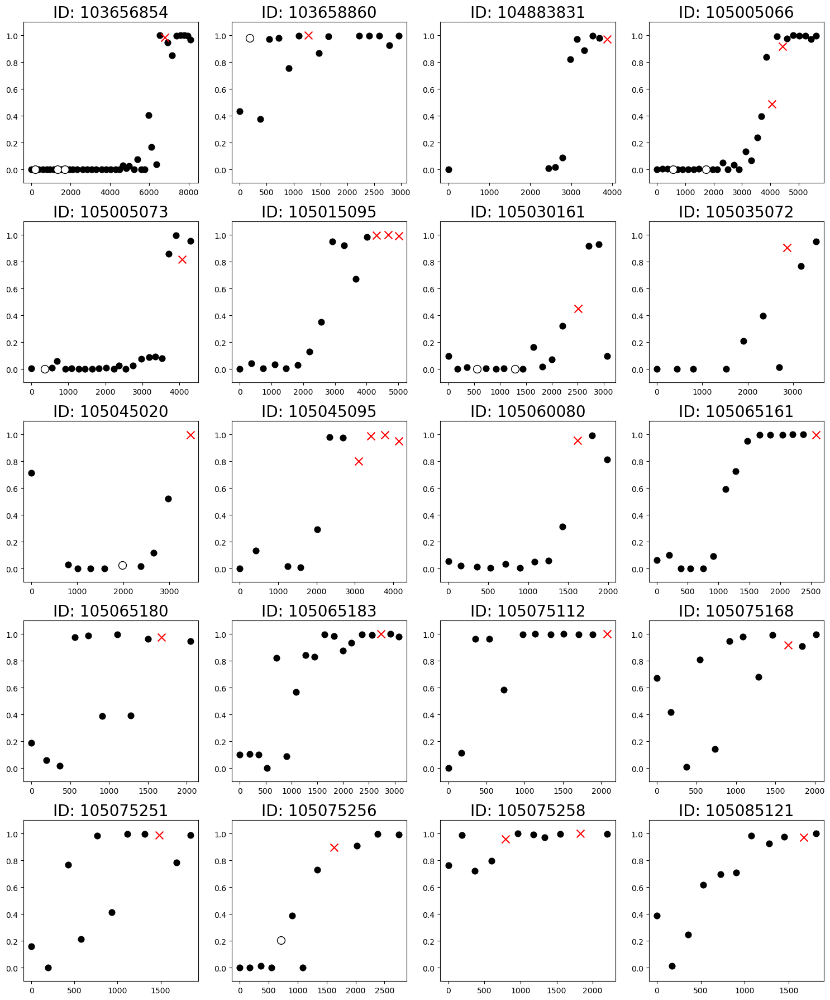

In [536]:
import matplotlib.pyplot as plt

# Custom color palette (optional if you're not using it directly)
custom_palette = {
    0: '#f5df4e',
    999: 'grey',
    1: '#4b4fdb'
}

# Set y-axis limits
y_min = -0.1
y_max = 1.1

patients = [103656854,103658860,104883831,105005066,105005073,105015095,105030161,105035072,105045020,105045095
,105060080,105065161,105065180,105065183,105075112,105075168,105075251,105075256,105075258,105085121]

# Setup plot
fig, axes = plt.subplots(5, 4, figsize=(15, 18))
axes = axes.flatten()

for i, patient_id in enumerate(patients):
    selection = df_proba[df_proba['ID'] == patient_id]
    ax =axes[i]
    # Plot for each label
        
    if not selection[selection['label'] == 999].empty:
        ax.scatter(selection['day'][selection['label'] == 999],
                   selection['probability'][selection['label'] == 999],
                   marker='o', color='black', s=60)
        
    if not selection[selection['label'] == 0].empty:
        ax.scatter(selection['day'][selection['label'] == 0],
                   selection['probability'][selection['label'] == 0],
                   marker='o', edgecolors='black', facecolors='white', s=100)

    if not selection[selection['label'] == 1].empty:
        ax.scatter(selection['day'][selection['label'] == 1],
                   selection['probability'][selection['label'] == 1],
                   marker='x', color='red', s=100)


    # Labels and limits
    ax.set_ylim(y_min, y_max)
    ax.set_title(f'ID: {patient_id}', fontsize=20)
plt.tight_layout()
plt.show()


Start threshold is 0.07882979786503304
Stop threshold is 0.8880640748669301


You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
overflow encountered in exp
You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
overflow encountered in exp
You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.


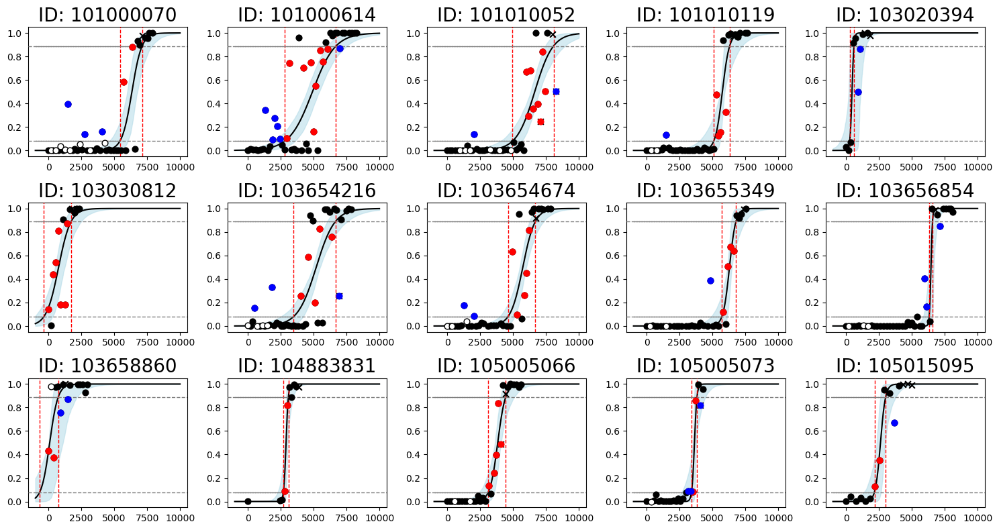

In [554]:
import numpy as np
import matplotlib.pyplot as plt
from statistics import mode

# Thresholds
healthy_data = df_proba[df_proba['label'] == 0]
polyp_data = df_proba[df_proba['label'] == 1]
threshold_1 = np.mean(healthy_data['probability'])
threshold_2 = np.mean(polyp_data['probability'])

print(f'Start threshold is {threshold_1}')
print(f'Stop threshold is {threshold_2}')

trans_index = []
early_index = []
late_index = []
fluctuating_collection = []
transition_collection = []
early_collection, late_collection = [], []


# Setup plot
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
axes = axes.flatten()

for i in range(0, 15):  # Only 10 subplots available
    np.random.seed(42)
    ax = axes[i]

    # Individual-level parameters
    g_i = indiv_param.iloc[i]['g_mode']
    s_i = indiv_param.iloc[i]['s_mode']
    ID = int(indiv_param.iloc[i]['id'])

    # Random effect SDs
    g_randeff_sd = randef_param.iloc[i]['eta_g_sd']
    s_randeff_sd = randef_param.iloc[i]['eta_s_sd']

    # Simulation settings
    n_sim = 1000
    time = np.linspace(-1000, 10000, 1000)

    # Simulate random effects
    eta_g_samples = np.random.normal(0, scale=g_randeff_sd, size=n_sim)
    eta_s_samples = np.random.normal(0, scale=s_randeff_sd, size=n_sim)
    g_samples = g_i * np.exp(eta_g_samples)
    s_samples = s_i * np.exp(eta_s_samples)

    # Generate curves
    curves = [1 / (1 + np.exp(-g_sim * (time - s_sim))) for g_sim, s_sim in zip(g_samples, s_samples)]
    curves = np.array(curves)
    lower = np.percentile(curves, 2.5, axis=0)
    upper = np.percentile(curves, 97.5, axis=0)
    median = np.median(curves, axis=0)

    # Original curve
    y_orig = 1 / (1 + np.exp(-g_i * (time - s_i)))

    transition_1 = np.argmax(y_orig > threshold_1)
    t_transition_1 = time[transition_1]
    transition_2 = np.argmax(y_orig > threshold_2)
    t_transition_2 = time[transition_2] 

    # Plot base curves
    ax.axvline(t_transition_1, color='red', linestyle='--', linewidth=1, label='Transition thresholds', zorder=3)
    ax.axvline(t_transition_2, color='red', linestyle='--', linewidth=1, zorder=3)
    ax.axhline(threshold_1, color='grey', linestyle='--', linewidth=1, label = 'Transition thresholds', zorder=3)
    ax.axhline(threshold_2, color='grey', linestyle='--', linewidth=1, zorder=3)
    ax.plot([-1000, t_transition_1], [threshold_1, threshold_1], color='grey', linestyle='--', linewidth=1, zorder=3)
    ax.plot([-1000, t_transition_2], [threshold_2, threshold_2], color='grey', linestyle='--', linewidth=1, zorder=3)
    ax.fill_between(time, lower, upper, color='lightblue', alpha=0.5, zorder=1)
    ax.plot(time, y_orig, 'black', label='Original fit', zorder=2)

    fluctuating_points = None


    # Observed data (if any)
    select_id = df_pol10[df_pol10['ID'] == ID]

    t1, t2 = sorted([t_transition_1, t_transition_2])
    transition_points = select_id[(select_id['day'] > t1) & (select_id['day'] < t2) & 
                                  (select_id['probability'] > threshold_1) & (select_id['probability'] < threshold_2)]
    
    if not select_id.empty:
        for label_val, marker, face, edge in [(999, 'o', 'black', 'black'),
                                              (1, 'x', 'black', 'black'),
                                              (0, 'o', 'white', 'black')]:
            subset = select_id[select_id['label'] == label_val]
            if not subset.empty:
                ax.scatter(subset['day'], subset['probability'], marker=marker,
                           facecolors=face, edgecolors=edge, s=40, zorder=4)

        # Define transition regions
        if t_transition_1 < t_transition_2:
            early_points = select_id[(select_id['day'] < t_transition_1) & (select_id['probability'] < threshold_1)]

            fluctuating_points = early_points.loc[
            (early_points['probability'] > threshold_1) & 
            (early_points['probability'] < threshold_2)]
            
            late_points = select_id[(select_id['day'] > t_transition_2) & (select_id['probability'] > threshold_2)]
        else:
            early_points = select_id[(select_id['day'] < t_transition_1) & (select_id['probability'] < threshold_2)]

            fluctuating_points = early_points.loc[
            (early_points['probability'] > threshold_1) & 
            (early_points['probability'] < threshold_2)]

            late_points = select_id[(select_id['day'] > t_transition_1) & (select_id['probability'] > threshold_2)]

        # Pretransition
        pretransition = early_points[early_points['day'] > (min(t_transition_1, t_transition_2) - 365)]
        

        if not pretransition.empty:
            pretransition_points.append(pretransition)
        elif not early_points.empty:
            pretransition = early_points.loc[[early_points['day'].idxmax()]]
            pretransition_points.append(pretransition)

        # Append indices
        early_index.extend(early_points.index.tolist())
        late_index.extend(late_points.index.tolist())

        if not transition_points.empty:
            ax.scatter(transition_points['day'], transition_points['probability'], c='red',
                       s=40, label='Transition points', zorder=5)
    else:
        ax.text(0.5, 0.5, 'No observed data', ha='center', va='center',
                transform=ax.transAxes, fontsize=14, color='gray', alpha=0.7)
        
    fluctuating_points = select_id[((select_id['day'] < t_transition_1) & (select_id['probability'] < threshold_2) & (select_id['probability'] > threshold_1)) |
                                   ((select_id['day'] > t_transition_2) & (select_id['probability'] < threshold_2) & (select_id['probability'] > threshold_1))]
        
    early_collection.append(early_points)
    late_collection.append(late_points)
    fluctuating_collection.append(fluctuating_points)
    transition_collection.append(transition_points)
    ax.scatter(fluctuating_points['day'].values, fluctuating_points['probability'].values, c='blue', s=40, label='Fluctuating points', zorder=5)

    ax.set_title(f'ID: {ID}', size=20)
    ax.grid(False)

plt.tight_layout()
plt.show()


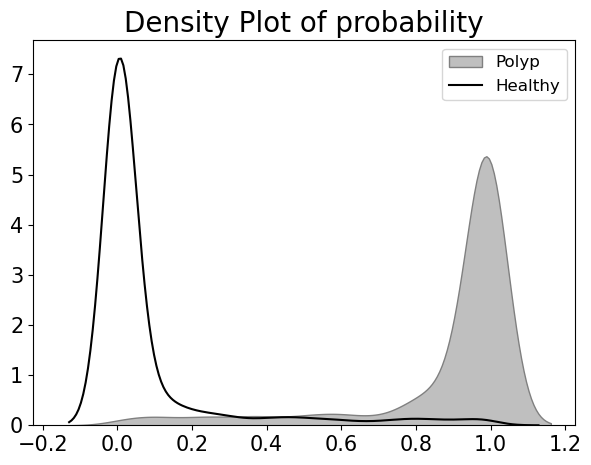

In [556]:
column = 'probability'
polyp_patients = df_proba[df_proba["label"]==1][column]
normal_patient = df_proba[df_proba["label"]==0][column]

plt.figure(figsize=(7,5))
sns.kdeplot(polyp_patients, label='Polyp', alpha=0.5, fill=True, color='grey')
sns.kdeplot(normal_patient, label='Healthy', color='black', fill=False)
plt.xlabel("")
plt.yticks(size=15)
plt.xticks(size=15)
plt.ylabel('')
plt.title(f'Density Plot of {column}', size=20)
plt.legend(fontsize = 12)
plt.show() 

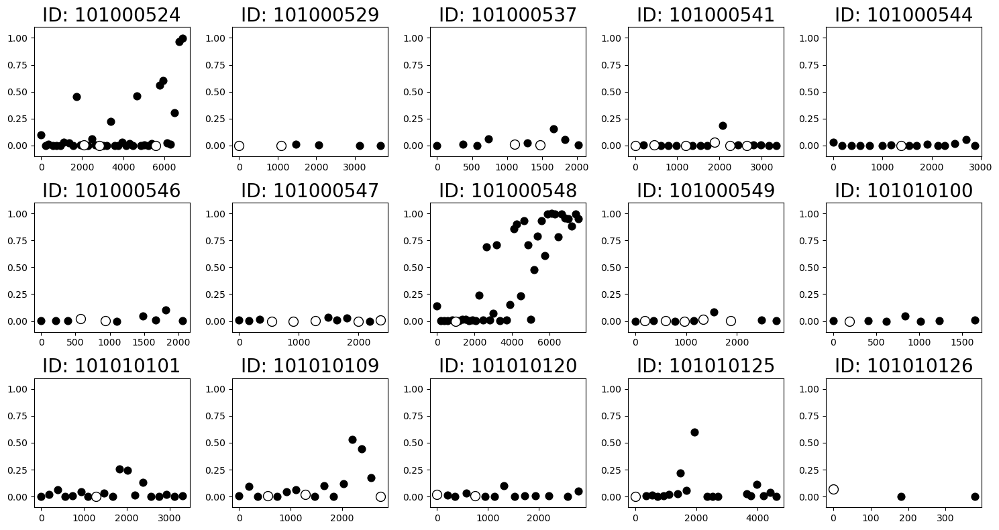

In [555]:
import matplotlib.pyplot as plt

# Custom color palette (optional if you're not using it directly)
custom_palette = {
    0: '#f5df4e',
    999: 'grey',
    1: '#4b4fdb'
}

# Set y-axis limits
y_min = -0.1
y_max = 1.1

#patients = [101000052, 101000053, 101000058, 101000060, 101000069, 101000073,101000093, 101000095, 101000101]
patients = [101000524, 101000529, 101000537, 101000541,101000544, 101000546, 101000547, 101000548, 101000549, 101010100, 101010101, 101010109, 101010120, 101010125, 101010126]

# Setup plot
fig, axes = plt.subplots(3, 5, figsize=(15, 8))
axes = axes.flatten()

for i, patient_id in enumerate(patients):
    selection = df_proba[df_proba['ID'] == patient_id]
    ax =axes[i]
    # Plot for each label
        
    if not selection[selection['label'] == 999].empty:
        ax.scatter(selection['day'][selection['label'] == 999],
                   selection['probability'][selection['label'] == 999],
                   marker='o', color='black', s=60)
        
    if not selection[selection['label'] == 0].empty:
        ax.scatter(selection['day'][selection['label'] == 0],
                   selection['probability'][selection['label'] == 0],
                   marker='o', edgecolors='black', facecolors='white', s=100)


    # Labels and limits
    ax.set_ylim(y_min, y_max)
    ax.set_title(f'ID: {patient_id}', fontsize=20)
plt.tight_layout()
plt.show()


In [545]:
always_healthyID

array([101000052, 101000053, 101000058, 101000060, 101000069, 101000073,
       101000093, 101000095, 101000101, 101000102, 101000118, 101000130,
       101000144, 101000147, 101000169, 101000174, 101000180, 101000183,
       101000184, 101000513, 101000524, 101000529, 101000537, 101000541,
       101000544, 101000546, 101000547, 101000548, 101000549, 101000552,
       101000569, 101000572, 101000583, 101000585, 101000601, 101000604,
       101000606, 101000610, 101000611, 101000612, 101000615, 101000619,
       101000624, 101000631, 101000632, 101000634, 101000635, 101000640,
       101000643, 101000659, 101000666, 101000675, 101000700, 101000704,
       101000706, 101000713, 101000716, 101000718, 101000725, 101000727,
       101006070, 101006095, 101006097, 101006174, 101006513, 101006527,
       101006540, 101006542, 101006544, 101006563, 101006589, 101006590,
       101006599, 101006603, 101006606, 101006612, 101006617, 101006629,
       101006652, 101006657, 101006706, 101006707, 

In [404]:
always_healthyID = uniquePatient[~np.isin(uniquePatient, polPatient)].astype(int)

print(f'The number of unique patients always healthy must be {len(always_healthyID)}')

The number of unique patients always healthy must be 707


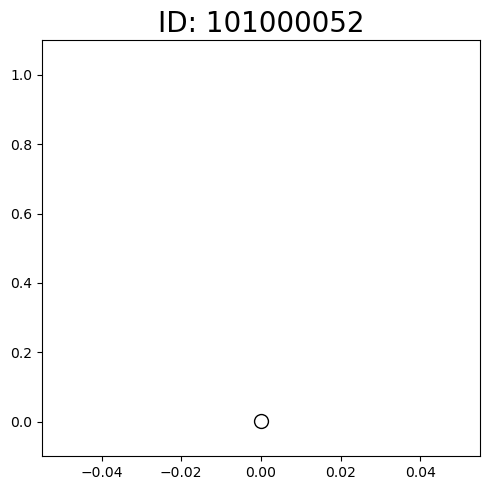

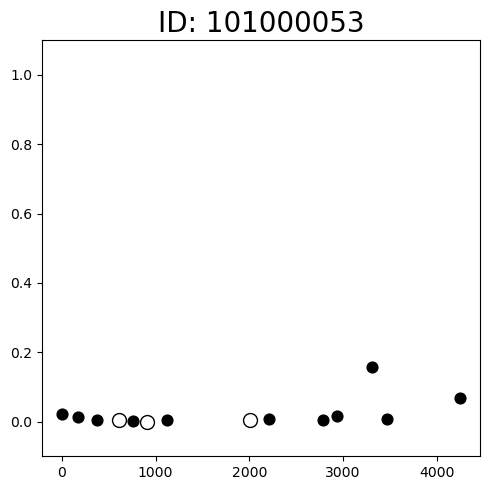

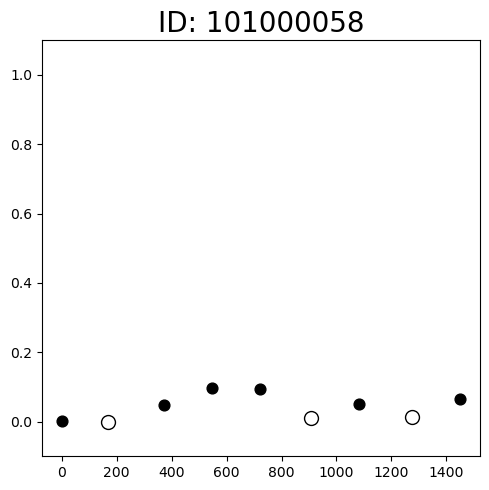

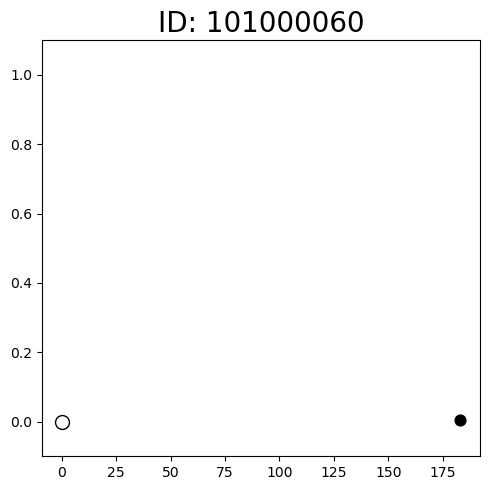

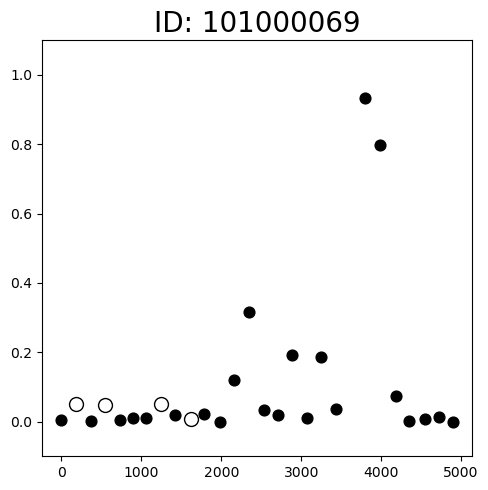

...

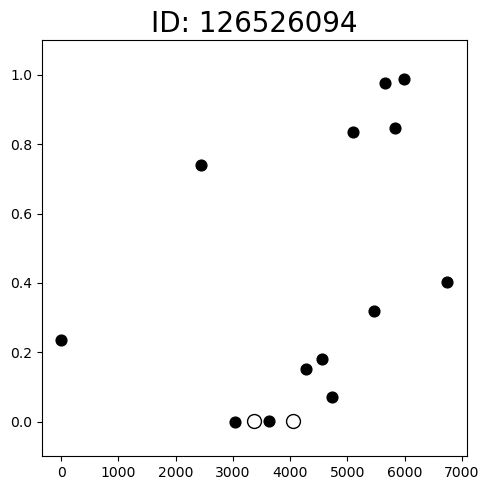

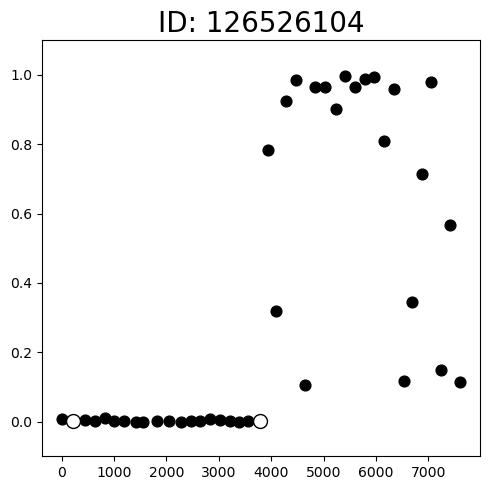

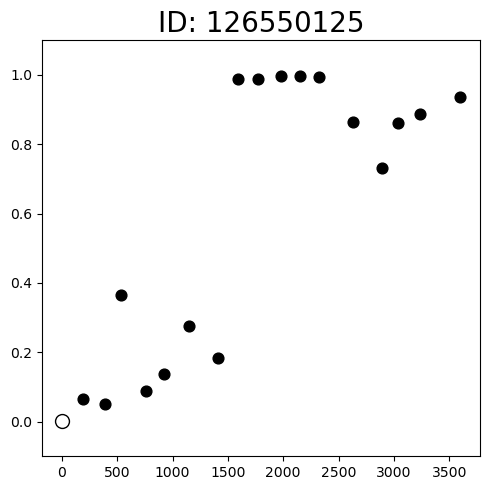

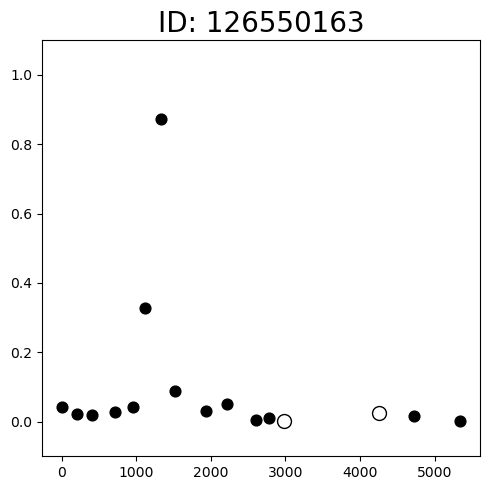

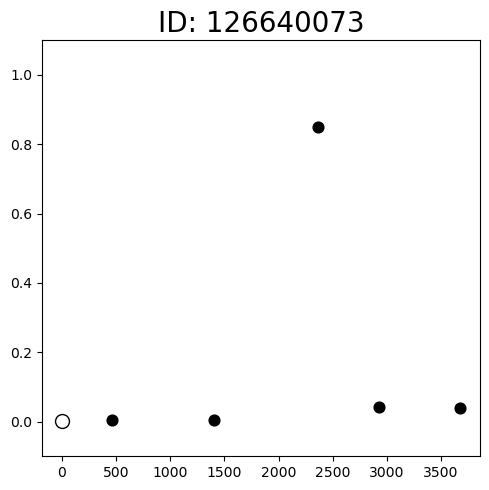

In [405]:
import matplotlib.pyplot as plt

# Set y-axis limits
y_min = -0.1
y_max = 1.1

for id in always_healthyID.tolist():
    fig, ax = plt.subplots(figsize=(5, 5))

    selection = df_proba[df_proba['ID'] == id]
    # Plot for each label
        
    if not selection[selection['label'] == 999].empty:
        ax.scatter(selection['day'][selection['label'] == 999],
                    selection['probability'][selection['label'] == 999],
                    marker='o', color='black', s=60)
        
    if not selection[selection['label'] == 0].empty:
        ax.scatter(selection['day'][selection['label'] == 0],
                    selection['probability'][selection['label'] == 0],
                    marker='o', edgecolors='black', facecolors='white', s=100)

    if not selection[selection['label'] == 1].empty:
        ax.scatter(selection['day'][selection['label'] == 1],
                    selection['probability'][selection['label'] == 1],
                    marker='x', color='red', s=100)

    # Labels and limits
    ax.set_ylim(y_min, y_max)
    ax.set_title(f'ID: {id}', fontsize=20)
    plt.tight_layout()
    #plt.savefig(f'/Users/kayharuni/Desktop/colorectal_cancer/no_polyp_timeseries/{id}.png')
    plt.show()

In [406]:
# collect polyp patients with at least 10 visits 

df_proba_polyp = df_proba.loc[df_proba['ID'].isin(polPatient)]

ID_more10 = []

for i in polPatient:
    if len(df_proba_polyp.loc[df_proba_polyp['ID']==i]) > 9:
        ID_more10.append(i)
        
df_pol10 = df_proba_polyp.loc[df_proba_polyp['ID'].isin(ID_more10)]
df_pol10

name,age,SW,degree_of_obesity,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,lymph,mono,basophil,MCV,...,PH,urine_ratio,probability,ID,visitday,label,CF,CF_eng,weight,day
44882,49.0,62.1,NaN,106.0,78.0,4.40,46.0,8.0,0.0,93.0,...,7.0,1.020,0.001697,101000070,1993-02-16,999.0,NaN,NaN,65.8,0
45863,49.0,62.1,NaN,100.0,70.0,4.40,55.5,6.0,0.0,92.0,...,6.0,1.018,0.003760,101000070,1993-08-18,0.0,正常です。,Normal,66.3,183
2748,50.0,62.1,NaN,108.0,74.0,3.30,43.0,8.0,0.0,92.0,...,6.5,1.021,0.003516,101000070,1994-02-18,999.0,NaN,NaN,63.9,367
45354,50.0,62.1,NaN,110.0,74.0,4.50,40.0,6.0,0.0,89.0,...,5.0,1.027,0.000351,101000070,1994-08-03,0.0,正常です。,Normal,64.7,533
3537,51.0,62.1,NaN,110.0,85.0,4.00,55.0,1.0,0.0,95.0,...,5.5,1.028,0.000377,101000070,1995-02-24,999.0,NaN,NaN,66.6,738
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45780,62.0,52.3,NaN,114.0,72.0,3.60,18.4,4.0,0.0,101.0,...,6.0,1.015,0.999508,126633224,2014-10-20,1.0,大腸ポリープ,Colon polyps,54.6,6598
40087,64.0,52.3,NaN,124.0,82.0,3.40,23.4,4.0,1.0,99.0,...,5.5,1.005,0.996841,126633224,2015-10-28,999.0,大腸メラノーシス,Melanosis coli,54.5,6971
45814,65.0,51.7,NaN,134.0,80.0,3.77,21.0,4.0,0.0,95.2,...,5.5,1.012,0.977672,126633224,2016-10-27,1.0,大腸ポリープ,Colon polyps,55.0,7336
45853,66.0,52.2,NaN,113.0,70.0,3.26,21.2,5.0,1.0,95.5,...,6.0,1.009,0.999467,126633224,2018-01-23,1.0,大腸ポリープ,Colon polyps,54.9,7789


In [407]:
# collect polyp patients with at least 10 visits 

df_proba_healthy = df_proba.loc[df_proba['ID'].isin(always_healthyID)]

ID_more10_healthy = []

for i in always_healthyID:
    if len(df_proba_healthy.loc[df_proba_healthy['ID']==i]) > 9:
        ID_more10_healthy.append(i)
        
df_pol10_healthy = df_proba_healthy.loc[df_proba_healthy['ID'].isin(ID_more10_healthy)]
df_pol10_healthy

name,age,SW,degree_of_obesity,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,lymph,mono,basophil,MCV,...,PH,urine_ratio,probability,ID,visitday,label,CF,CF_eng,weight,day
44926,46.0,60.7,NaN,112.0,80.0,6.7,20.0,9.0,0.0,87.0,...,6.0,1.024,0.021098,101000053,1993-02-17,999.0,NaN,NaN,64.5,0
45208,46.0,60.7,NaN,122.0,80.0,6.2,37.0,5.0,0.0,90.0,...,6.0,1.030,0.014440,101000053,1993-08-12,999.0,結腸は経過観察が必要です。,Colon needs to be monitored,64.5,176
2714,47.0,60.7,NaN,110.0,74.0,5.1,44.0,6.0,1.0,88.0,...,8.0,1.023,0.003553,101000053,1994-03-02,999.0,NaN,NaN,64.5,378
100,48.0,60.7,6.0,112.0,80.0,4.8,50.0,6.0,0.0,89.0,...,6.0,1.029,0.005096,101000053,1994-10-17,0.0,正常です。,Normal,NaN,607
3533,48.0,61.4,NaN,112.0,78.0,6.0,33.0,5.0,2.0,88.0,...,6.5,1.030,0.000605,101000053,1995-03-22,999.0,NaN,NaN,64.5,763
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10732,52.0,56.1,NaN,110.0,68.0,7.3,30.0,4.0,2.0,91.0,...,5.0,1.025,0.010131,126550163,2001-05-22,999.0,NaN,NaN,62.5,2777
880,53.0,56.0,9.0,100.0,70.0,7.7,19.0,3.0,1.0,91.0,...,5.0,1.025,0.001788,126550163,2001-12-06,0.0,正常です。,Normal,NaN,2975
1116,56.0,55.6,9.0,108.0,72.0,7.8,25.0,3.0,0.0,92.0,...,6.5,1.015,0.025768,126550163,2005-06-08,0.0,正常です。,Normal,NaN,4255
16420,57.0,55.7,NaN,100.0,72.0,7.3,30.0,1.0,0.0,92.0,...,6.0,1.030,0.017507,126550163,2006-09-19,999.0,NaN,NaN,61.0,4723


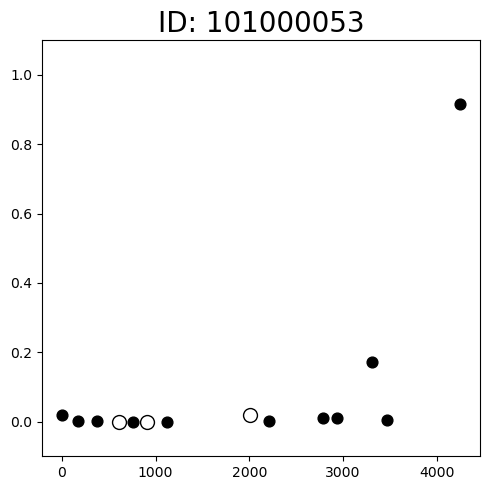

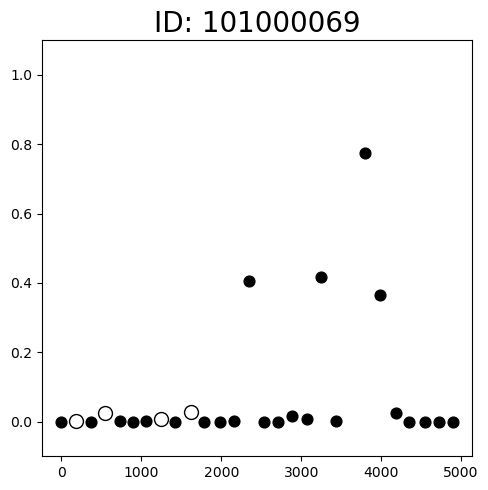

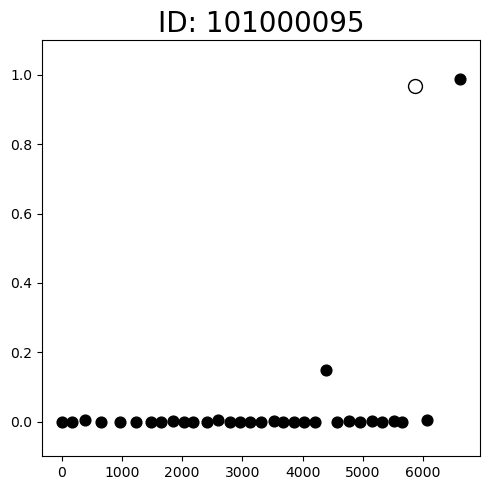

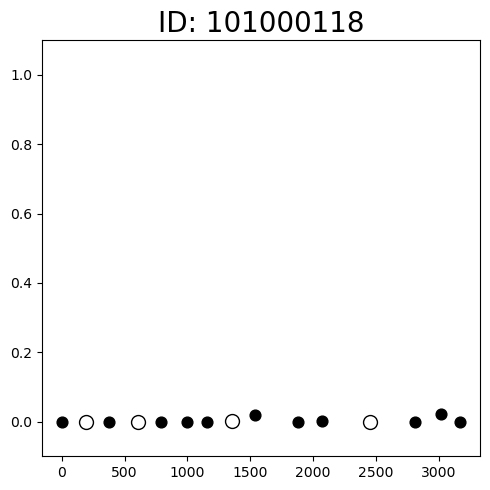

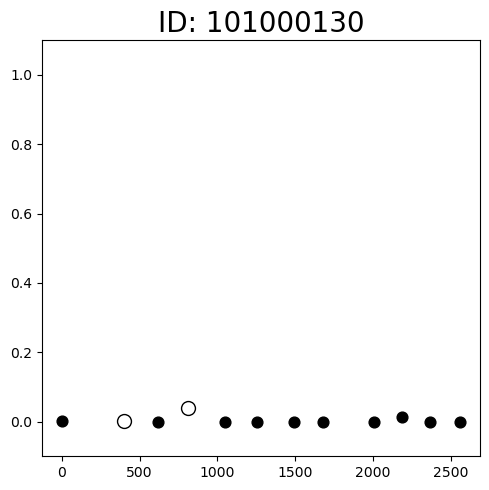

...

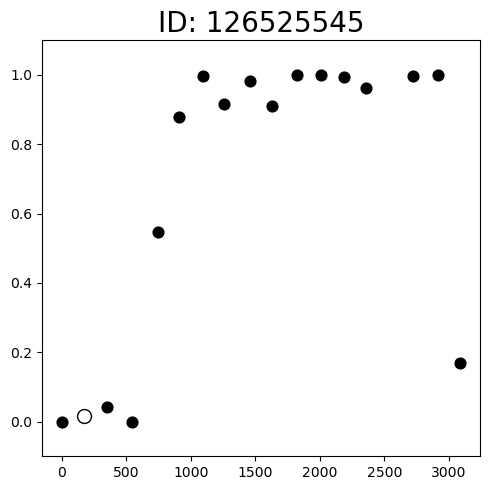

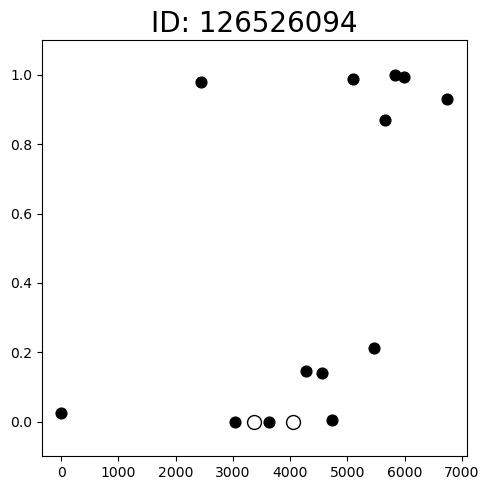

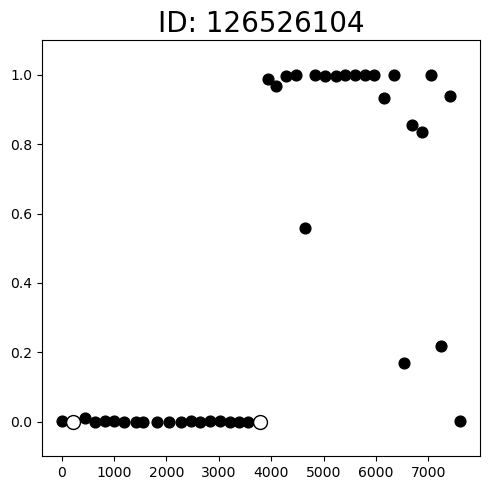

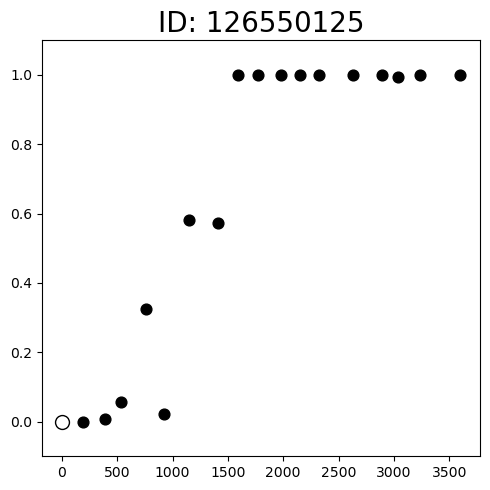

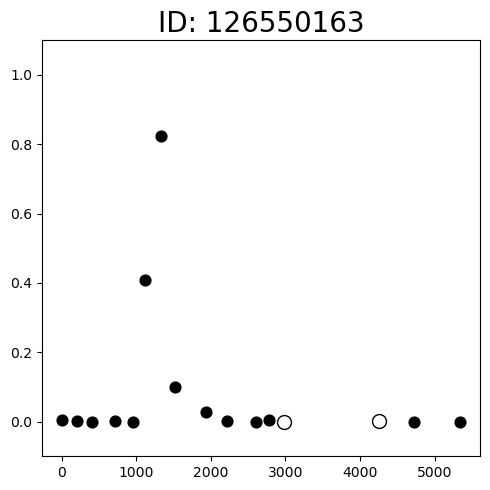

In [626]:
import matplotlib.pyplot as plt

# Set y-axis limits
y_min = -0.1
y_max = 1.1

for id in df_pol10_healthy['ID'].unique():
    fig, ax = plt.subplots(figsize=(5, 5))

    selection = df_proba[df_proba['ID'] == id]
    # Plot for each label
        
    if not selection[selection['label'] == 999].empty:
        ax.scatter(selection['day'][selection['label'] == 999],
                    selection['probability'][selection['label'] == 999],
                    marker='o', color='black', s=60)
        
    if not selection[selection['label'] == 0].empty:
        ax.scatter(selection['day'][selection['label'] == 0],
                    selection['probability'][selection['label'] == 0],
                    marker='o', edgecolors='black', facecolors='white', s=100)

    if not selection[selection['label'] == 1].empty:
        ax.scatter(selection['day'][selection['label'] == 1],
                    selection['probability'][selection['label'] == 1],
                    marker='x', color='red', s=100)

    # Labels and limits
    ax.set_ylim(y_min, y_max)
    ax.set_title(f'ID: {id}', fontsize=20)
    plt.tight_layout()
    #plt.savefig(f'/Users/kayharuni/Desktop/colorectal_cancer/no_polyp_timeseries/{id}.png')
    plt.show()

In [411]:
normal_data = df_proba[df_proba['label']==0]
polyp_data = df_proba[df_proba['label']==1]

In [420]:
huh = np.mean(normal_data['probability'])

In [424]:
print(f'mean probability normal: {np.mean(normal_data["probability"])}')
print(f'mean probability polyp: {np.mean(polyp_data["probability"])}')

mean probability normal: 0.07882979786503304
mean probability polyp: 0.8880640748669301


In [425]:
suh = df_pol10_healthy.copy()

In [426]:
suh['stage'] = np.where(suh['probability'] < mean_healthy, 0, 2)
suh = suh.drop(suh.loc[suh['probability'] > mean_healthy].index)
suh

name,age,SW,degree_of_obesity,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,lymph,mono,basophil,MCV,...,urine_ratio,probability,ID,visitday,label,CF,CF_eng,weight,day,stage
44926,46.0,60.7,NaN,112.0,80.0,6.7,20.0,9.0,0.0,87.0,...,1.024,0.021098,101000053,1993-02-17,999.0,NaN,NaN,64.5,0,0
45208,46.0,60.7,NaN,122.0,80.0,6.2,37.0,5.0,0.0,90.0,...,1.030,0.014440,101000053,1993-08-12,999.0,結腸は経過観察が必要です。,Colon needs to be monitored,64.5,176,0
2714,47.0,60.7,NaN,110.0,74.0,5.1,44.0,6.0,1.0,88.0,...,1.023,0.003553,101000053,1994-03-02,999.0,NaN,NaN,64.5,378,0
100,48.0,60.7,6.0,112.0,80.0,4.8,50.0,6.0,0.0,89.0,...,1.029,0.005096,101000053,1994-10-17,0.0,正常です。,Normal,NaN,607,0
3533,48.0,61.4,NaN,112.0,78.0,6.0,33.0,5.0,2.0,88.0,...,1.030,0.000605,101000053,1995-03-22,999.0,NaN,NaN,64.5,763,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10732,52.0,56.1,NaN,110.0,68.0,7.3,30.0,4.0,2.0,91.0,...,1.025,0.010131,126550163,2001-05-22,999.0,NaN,NaN,62.5,2777,0
880,53.0,56.0,9.0,100.0,70.0,7.7,19.0,3.0,1.0,91.0,...,1.025,0.001788,126550163,2001-12-06,0.0,正常です。,Normal,NaN,2975,0
1116,56.0,55.6,9.0,108.0,72.0,7.8,25.0,3.0,0.0,92.0,...,1.015,0.025768,126550163,2005-06-08,0.0,正常です。,Normal,NaN,4255,0
16420,57.0,55.7,NaN,100.0,72.0,7.3,30.0,1.0,0.0,92.0,...,1.030,0.017507,126550163,2006-09-19,999.0,NaN,NaN,61.0,4723,0


In [427]:
suh.to_csv('/Users/kayharuni/Desktop/df_always_normal.csv', index=False)

In [428]:
collect_day = []
for id in df_pol10.ID.unique():
    collect_day.append(df_pol10[df_pol10['ID'] == id].iloc[-1]['day'])
years = ([day/365 for day in collect_day])
print(f'median number of years: {np.median(years)}')
print(f'mean number of years: {np.mean(years)}')
print(f'minimum number of years: {np.min(years)}')
print(f'maximum number of years: {np.max(years)}')

median number of years: 11.591780821917808
mean number of years: 13.162319158865676
minimum number of years: 4.449315068493151
maximum number of years: 26.389041095890413


In [429]:
df_pol10.to_csv("/Users/kayharuni/Desktop/df_pol10.csv", index=False)

# modeling NLME 

In [430]:
indiv_param = pd.read_csv("/Users/kayharuni/Desktop/ib_lab/colorectar_cancer/monolix/pol10_new/IndividualParameters/estimatedIndividualParameters.txt")
randef_param = pd.read_csv("/Users/kayharuni/Desktop/ib_lab/colorectar_cancer/monolix/pol10_new/IndividualParameters/estimatedRandomEffects.txt")
pop_params = pd.read_csv('/Users/kayharuni/Desktop/ib_lab/colorectar_cancer/monolix/pol10_new/populationParameters.txt', index_col=0).T

: 

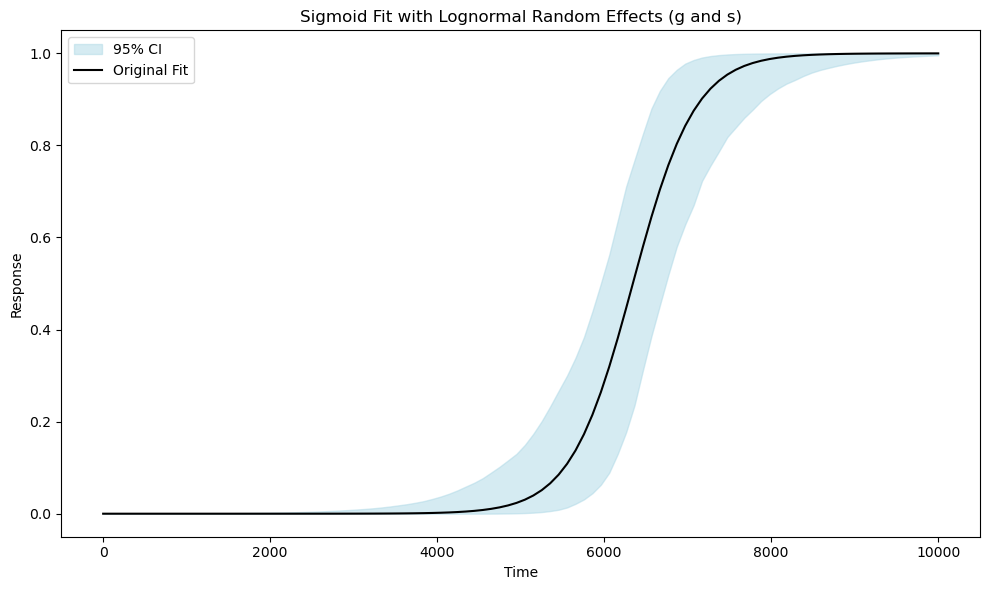

In [431]:
import numpy as np
import matplotlib.pyplot as plt

# Individual-level mode estimates (from Monolix)
g_i = indiv_param.iloc[0]['g_mode']   # e.g., 0.0051
s_i = indiv_param.iloc[0]['s_mode']   # e.g., 6625.78

# Random effects standard deviations (log-scale)
g_sd = randef_param.iloc[0]['eta_g_sd']  
s_sd = randef_param.iloc[0]['eta_s_sd']  

# Simulation settings
n_sim = 1000
time = np.linspace(0, 10000, 100)

# Simulate from zero-mean normal distribution (on log scale)
g_samples = np.random.normal(0, scale=g_sd, size=n_sim)
s_samples = np.random.normal(0, scale=s_sd, size=n_sim)

# Apply lognormal transformation
g_samples = g_i * np.exp(g_samples)
s_samples = s_i * np.exp(s_samples)

# Generate response curves
curves = []
for g_sim, s_sim in zip(g_samples, s_samples):
    y = 1 / (1 + np.exp(-g_sim * (time - s_sim)))
    curves.append(y)

# Convert list to array and compute percentiles
curves = np.array(curves)
lower = np.percentile(curves, 2.5, axis=0)
upper = np.percentile(curves, 97.5, axis=0)
median = np.median(curves, axis=0)

# Original curve (using point estimates)
y_orig = 1 / (1 + np.exp(-g_i * (time - s_i)))

# Plot
plt.figure(figsize=(10, 6))
plt.fill_between(time, lower, upper, color='lightblue', alpha=0.5, label='95% CI')
plt.plot(time, y_orig, 'black', label='Original Fit')
plt.xlabel('Time')
plt.ylabel('Response')
plt.title("Sigmoid Fit with Lognormal Random Effects (g and s)")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()


start threshold is 0.07882979786503304
stop threshold is 0.8880640748669301


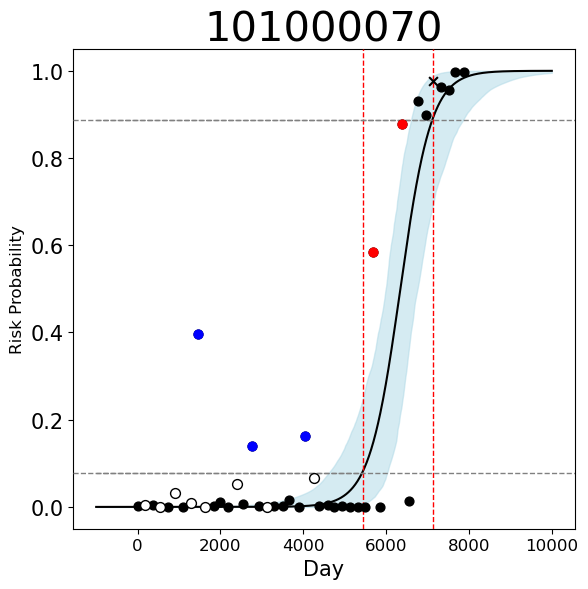

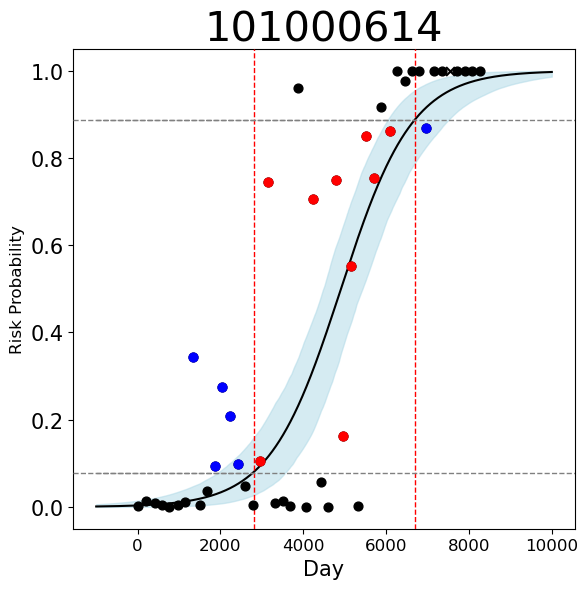

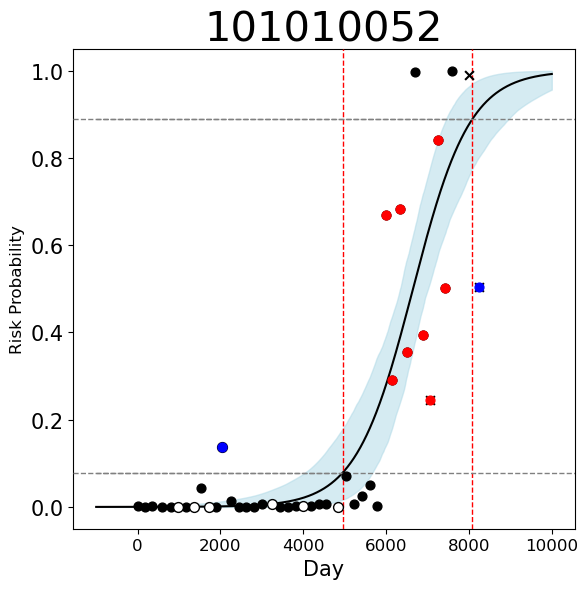

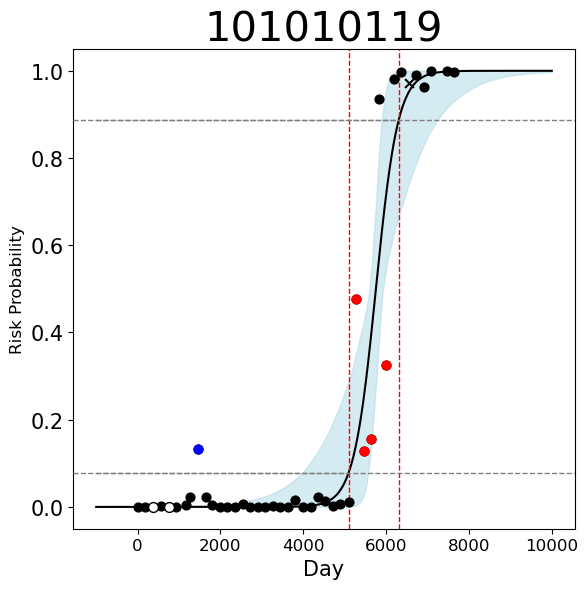

overflow encountered in exp


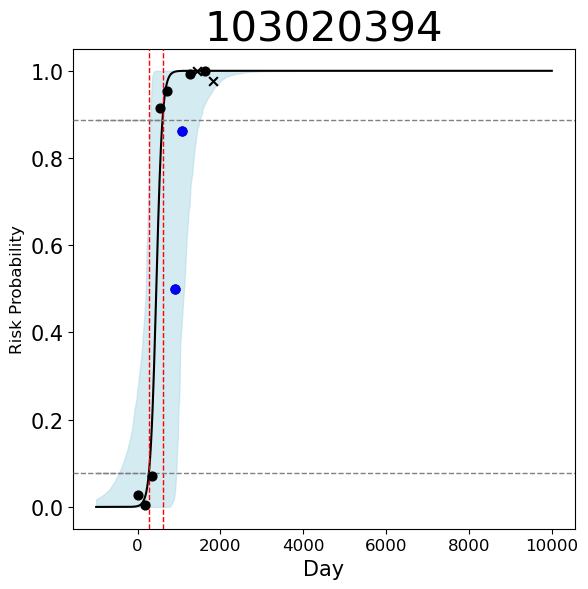

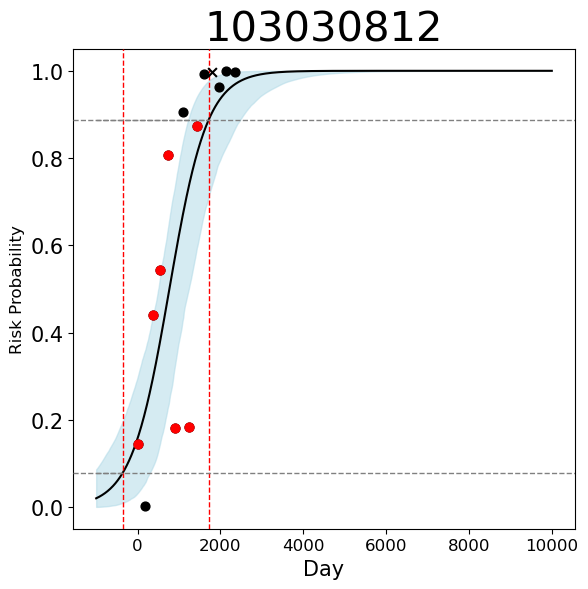

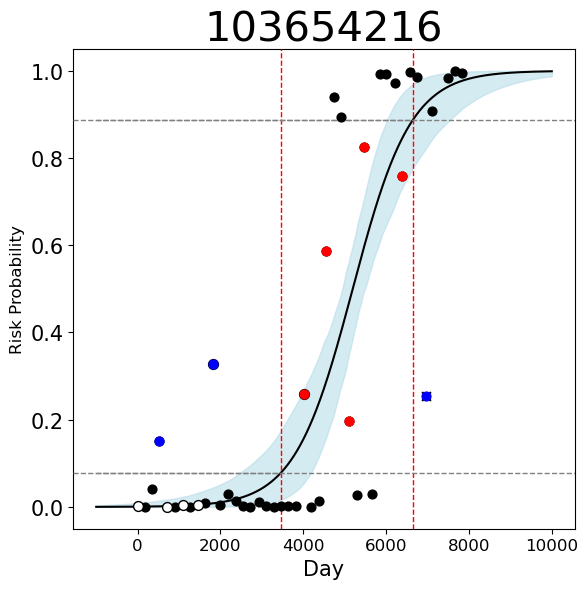

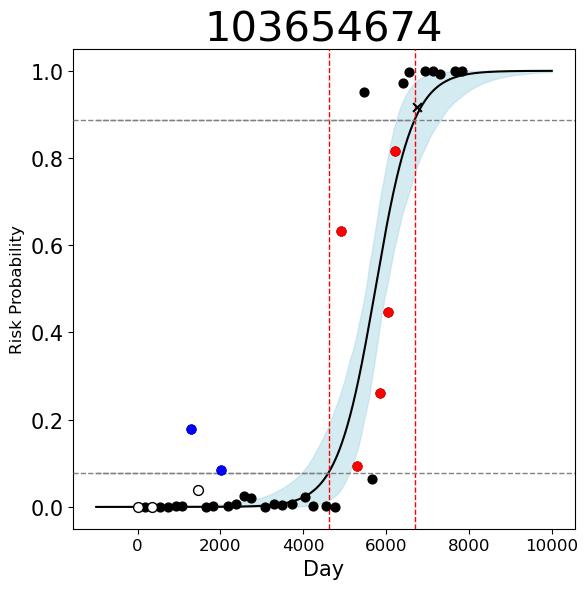

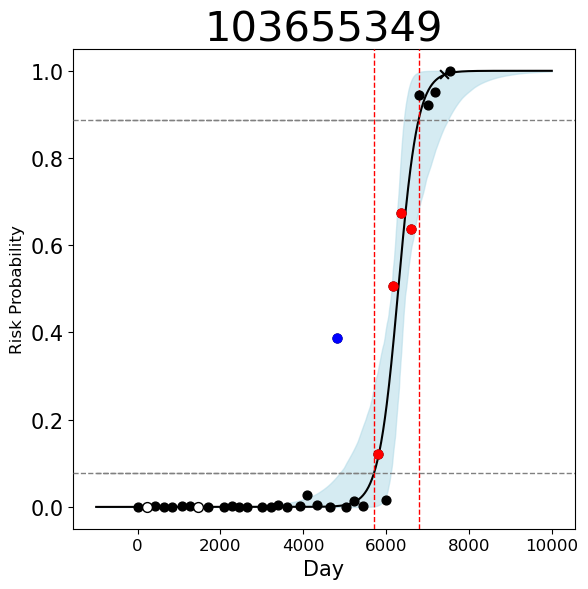

...

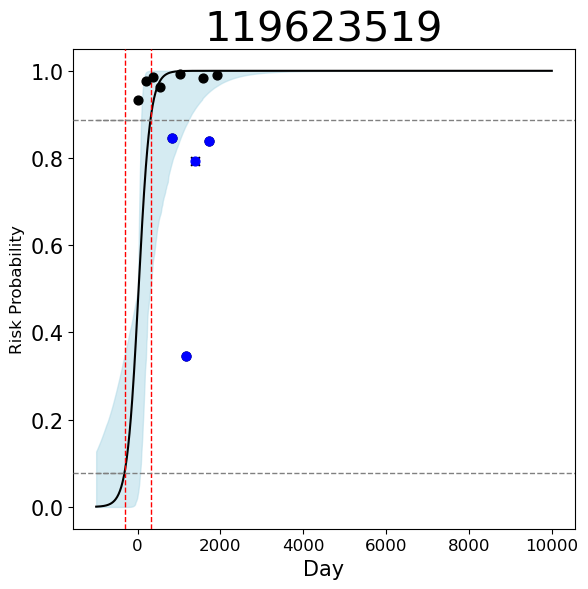

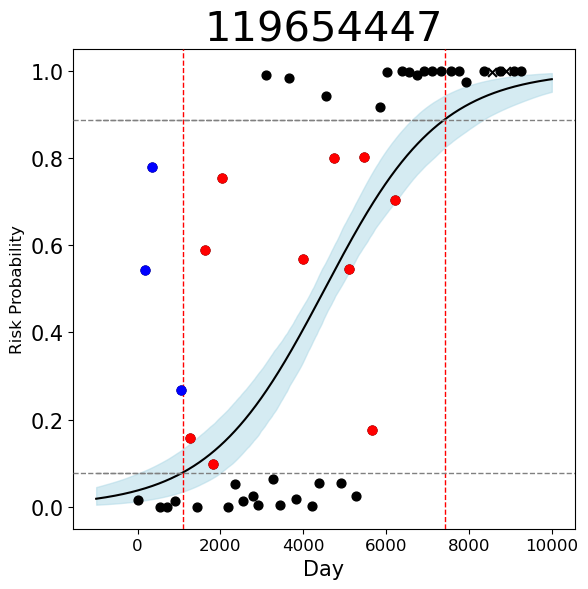

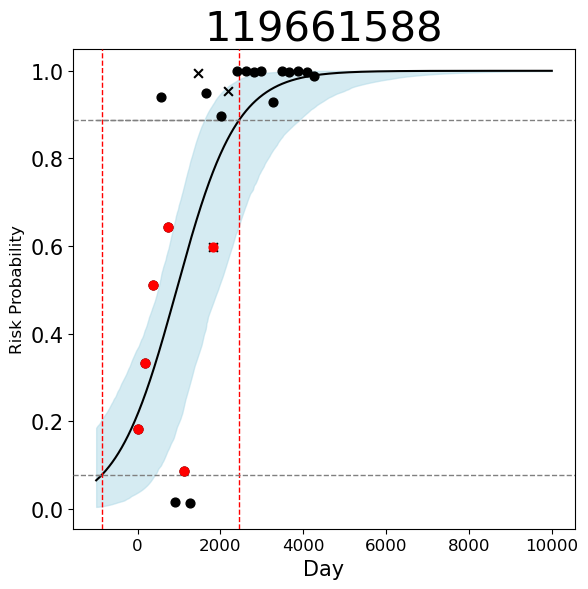

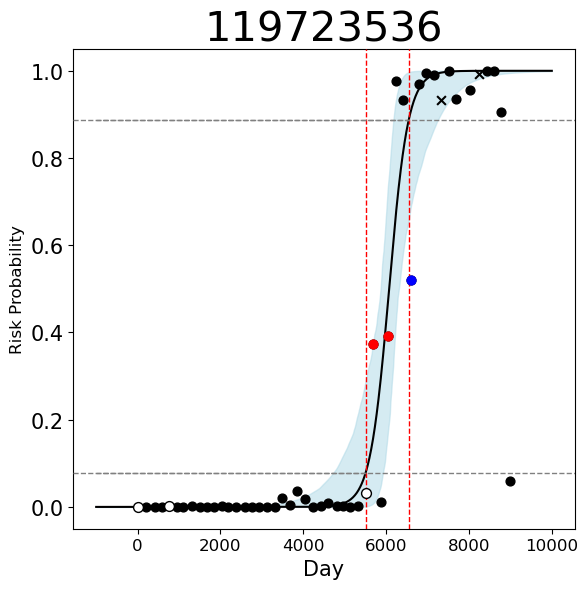

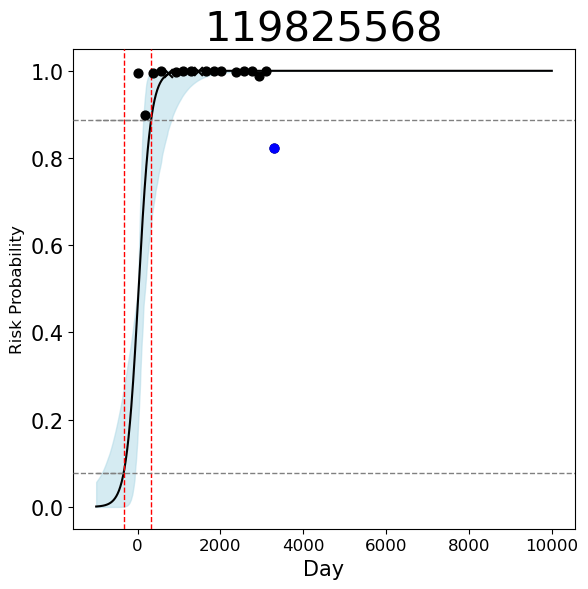

In [432]:
healthy_data = df_proba[df_proba['label']==0]
polyp_data = df_proba[df_proba['label']==1]
threshold_1 = np.mean(healthy_data['probability'])
threshold_2 = np.mean(polyp_data['probability'])
print(f'start threshold is {threshold_1}')
print(f'stop threshold is {threshold_2}')
trans_index = []
early_index = []
late_index = []
pretransition_points = []
fluctuating_collection = []
transition_collection = []
early_collection, late_collection = [], []

df_pol10 = df_pol10.reset_index(drop=True)

for i in range(0, len(indiv_param)):
    np.random.seed(42)

    # Individual-level mode estimates (from Monolix)
    g_i = indiv_param.iloc[i]['g_mode']   
    s_i = indiv_param.iloc[i]['s_mode']  
    ID = indiv_param.iloc[i]['id'].astype(int)

    # Random effects standard deviations (log-scale)
    g_randeff_sd = randef_param.iloc[i]['eta_g_sd']  # e.g., 0.7
    s_randeff_sd = randef_param.iloc[i]['eta_s_sd']  # e.g., 0.02

    # Simulation settings
    n_sim = 1000
    time = np.linspace(-1000, 10000, 1000)

    # Simulate from zero-median normal distribution (on log scale)
    eta_g_samples = np.random.normal(0, scale=g_randeff_sd, size=n_sim)
    eta_s_samples = np.random.normal(0, scale=s_randeff_sd, size=n_sim)

    # Apply lognormal transformation
    g_samples = g_i * np.exp(eta_g_samples)
    s_samples = s_i * np.exp(eta_s_samples)

    # Generate response curves
    curves = []
    for g_sim, s_sim in zip(g_samples, s_samples):
        y = 1 / (1 + np.exp(-g_sim * (time - s_sim)))
        curves.append(y)

    # Convert list to array and compute percentiles
    curves = np.array(curves)
    lower = np.percentile(curves, 2.5, axis=0)
    upper = np.percentile(curves, 97.5, axis=0)
    median = np.median(curves, axis=0)

    # Original curve (using point estimates)
    y_orig = 1 / (1 + np.exp(-g_i * (time - s_i)))

    # defining the transition thresholds

    above_thresh1 = np.where(y_orig > threshold_1)[0]
    if len(above_thresh1) == 0:
        continue
    transition_1 = above_thresh1[0]
    t_transition_1 = time[transition_1]

    above_thresh2 = np.where(y_orig > threshold_2)[0]
    if len(above_thresh2) == 0:
        continue
    transition_2 = above_thresh2[0]
    t_transition_2 = time[transition_2]


    # Confidence Interval of lower asymptote/early progression
    select_id = df_pol10[df_pol10['ID'] == ID]
    all_days = select_id['day']
    all_proba = select_id['probability']
    
    
    t1, t2 = sorted([t_transition_1, t_transition_2])
    transition_points = select_id[(select_id['day'] > t1) & (select_id['day'] < t2) & 
                                  (select_id['probability'] > threshold_1) & (select_id['probability'] < threshold_2)]
    fluctuating_points = None

    if t_transition_1 < t_transition_2:
        early_points = select_id[(select_id['day'] < t_transition_1) & (select_id['probability'] < threshold_1)]
        late_points = select_id[(select_id['day'] > t_transition_2) & (select_id['probability'] > threshold_2)]

        #pretransition = early_points[early_points['day'] > (t_transition_1 - ((365)*1))]

        #if not pretransition.empty:
            #pretransition_points.append(pretransition)
        #elif not early_points.empty:
            #pretransition = early_points.loc[[early_points['day'].idxmax()]] #ensure its a dtaaframe not a series
            #pretransition_points.append(pretransition)
        #else:
            #continue
    #else:
        #early_points = select_id[(select_id['day'] < t_transition_2) & (select_id['probability'] < threshold_1)]
        #late_points = select_id[(select_id['day'] > t_transition_1) & (select_id['probability'] > threshold_2)]

        #pretransition = early_points.loc[early_points['day'] > (t_transition_2 - ((365)*1))]

        #if not pretransition.empty:
            #pretransition_points.append(pretransition)
        #elif not early_points.empty:
            #pretransition = early_points.loc[[early_points['day'].idxmax()]]
            #pretransition_points.append(pretransition)
        #else:
            #continue

    early_index.extend(early_points.index.tolist())
    late_index.extend(late_points.index.tolist())

    if not transition_points.empty:
        transition_day = transition_points['day']
        transition_proba = transition_points['probability']
        trans_index.extend(transition_points.index.tolist())
    else:
        transition_day = None
        transition_proba = None

    fluctuating_points = select_id[((select_id['day'] < t_transition_1) & (select_id['probability'] < threshold_2) & (select_id['probability'] > threshold_1)) |
                                   ((select_id['day'] > t_transition_2) & (select_id['probability'] < threshold_2) & (select_id['probability'] > threshold_1))]

    #fluctuating_points = early_points.loc[
        #(early_points['probability'] > threshold_1) & 
        #(early_points['probability'] < threshold_2)]
    
    early_collection.append(early_points)
    late_collection.append(late_points)
    fluctuating_collection.append(fluctuating_points)
    transition_collection.append(transition_points)
    
    # Plot
    fig, ax = plt.subplots(figsize=(6, 6))
    plt.axvline(t_transition_1, color='red', linestyle='--', linewidth=1, label = 'Transition thresholds', zorder=3)
    plt.axvline(t_transition_2, color='red', linestyle='--', linewidth=1, zorder=3)
    plt.axhline(threshold_1, color='grey', linestyle='--', linewidth=1, label = 'Transition thresholds', zorder=3)
    plt.axhline(threshold_2, color='grey', linestyle='--', linewidth=1, zorder=3)
    plt.plot([-1000, t_transition_1], [threshold_1, threshold_1], color='grey', linestyle='--', linewidth=1, zorder=3)
    plt.plot([-1000, t_transition_2], [threshold_2, threshold_2], color='grey', linestyle='--', linewidth=1, zorder=3)
    plt.fill_between(time, lower, upper, color='lightblue', alpha=0.5, zorder=1)
    plt.plot(time, y_orig, 'black', label = 'Original fit', zorder=2)

    if not select_id[select_id['label'] == 999].empty:
        ax.scatter(select_id['day'][select_id['label'] == 999],
                   select_id['probability'][select_id['label'] == 999],
                   marker='o', color='black', s=40, zorder=4)
        
    if not select_id[select_id['label'] == 1].empty:
        ax.scatter(select_id['day'][select_id['label'] == 1],
                   select_id['probability'][select_id['label'] == 1],
                   marker='x', color='black', s=40, zorder=4)
        
    if not select_id[select_id['label'] == 0].empty:
        ax.scatter(select_id['day'][select_id['label'] == 0],
                   select_id['probability'][select_id['label'] == 0],
                   marker='o', edgecolors='black', facecolors='white', s=50, zorder=4)
    
    plt.scatter(fluctuating_points['day'].values, fluctuating_points['probability'].values, c='blue', s=40, label='Fluctuating points', zorder=5)

    #plt.plot(time, median, 'blue', label = 'Median fit')
    if transition_proba is not None:
        plt.scatter(transition_day, transition_proba, c='red', s=40, label = 'Transition points', zorder=5)

    
    plt.xlabel('Day', size=15)
    plt.ylabel('Risk Probability', size=12)
    plt.yticks(size=15)
    plt.xticks(size=12)
    plt.title(f'{ID}', size=30)
    plt.grid(False)
    #plt.legend()
    plt.tight_layout()
    #plt.savefig(f'/Users/kayharuni/Desktop/April/graph_CI/{ID}.png', bbox_inches='tight')
    plt.show()

In [434]:
check_corr = df_clean[featureOver10]
check_corr

,age,weight,SW,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,lymph,mono,basophil,MCV,...,total_bil,cholinesterase,r_GTP,LAP,urea_N,Cr,Cl,Ca,PH,urine_ratio
0,62.0,69.5,61.4,186.0,96.0,5.1,41.0,1.0,1.0,101.0,...,0.6,-0.177906,17.0,0.033201,18.0,0.8,105.0,9.2,5.5,1.024
1,61.0,52.1,54.2,104.0,64.0,3.8,50.0,3.0,0.0,103.0,...,1.0,-0.209769,11.0,-0.222132,14.0,0.7,101.0,9.6,5.0,1.016
2,62.0,56.9,52.8,124.0,80.0,4.7,26.0,7.0,0.0,91.0,...,0.6,-0.045317,10.0,-0.647686,15.0,0.8,104.0,8.7,5.0,1.014
3,47.0,68.6,59.3,130.0,92.0,5.1,47.5,6.0,0.0,93.0,...,0.9,1.506700,188.0,3.295781,17.0,1.0,103.0,9.9,5.0,1.024
4,59.0,58.0,57.9,118.0,86.0,4.5,41.0,7.0,0.0,93.0,...,0.5,0.700885,9.0,-0.307243,14.0,0.8,101.0,8.8,5.5,1.018
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45868,43.0,91.1,71.3,160.0,102.0,9.4,38.0,8.0,1.0,85.0,...,0.9,1.965110,62.0,1.111271,15.0,1.0,102.0,9.9,6.0,1.019
45869,61.0,65.0,71.3,125.0,90.0,6.6,23.0,5.0,0.0,93.0,...,1.2,-1.020723,22.0,0.033201,17.0,0.9,106.0,8.9,5.5,1.015
45870,57.0,72.0,64.3,115.0,76.0,5.7,53.0,4.0,0.0,98.0,...,0.8,0.906450,97.0,1.593565,21.0,1.0,106.0,9.4,5.0,1.022
45871,56.0,52.9,55.7,120.0,80.0,4.5,49.0,7.0,2.0,93.0,...,0.5,0.148942,44.0,1.593565,18.0,0.9,106.0,9.0,5.0,1.020


In [436]:
# Plot the heatmap between features in the dataframe
import seaborn as sb

plt.figure(figsize=(20,20))
sb.heatmap(check_corr.corr(), annot=True,
           cbar=True, cmap='RdBu', fmt='.1f')
plt.show()

# Violinplot features along dev 

In [103]:
# Add 'group' labels

from statannotations.Annotator import Annotator , StatResult
statsmodels.stats.multitest.multipletests

early_points_labeled = df_pol10.iloc[early_index]
early_points_labeled['group'] = 'Early, Low risk'

transition_points_labeled = df_pol10.iloc[trans_index]
transition_points_labeled['group'] = 'Transition'

late_points_labeled = df_pol10.iloc[late_index]
late_points_labeled['group'] = 'Late, High risk'

# Combine them
combined_df = pd.concat([early_points_labeled, transition_points_labeled, late_points_labeled], ignore_index=True)

for column in featureOver10:
    plt.figure(figsize=(8, 6))
    x='group'
    y = column
    order = ['Early, Low risk', 'Transition', 'Late, High risk']

    ax = sns.violinplot(data=combined_df, x=x, y=y, order=order, palette=['#6f915e', '#e89f56', '#eb4034'])

    pairs = [('Early, Low risk', 'Transition'), ('Early, Low risk','Late, High risk'), ('Transition', 'Late, High risk')]

    annotator = Annotator(ax, pairs, data=combined_df, x=x, y=y, order=order)
    annotator.configure(test='Mann-Whitney', 
                        text_format='star', 
                        loc='outside')
    
    annotator.apply_and_annotate()
    annotator.data.stat_value

    print(f"{column} of Low: {np.median(combined_df[combined_df[x] == 'Early, Low risk'][column])}")
    print(f"{column} of Transition: {np.median(combined_df[combined_df[x] == 'Transition'][column])}")
    print(f"{column} of High: {np.median(combined_df[combined_df[x] == 'Late, High risk'][column])}")

    plt.title(column, size=25, y = 1.3)
    plt.ylabel('')
    plt.xlabel('')
    plt.xticks(size=20)
    plt.yticks(size=15)
    plt.tight_layout()
    #plt.savefig(f"/Users/kayharuni/Desktop/thesis_figures/compare_stages/{column}_violin.png", bbox_inches='tight')
    plt.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Early, Low risk vs. Transition: Mann-Whitney-Wilcoxon test two-sided, P_val:8.454e-64 U_stat=6.244e+05
Transition vs. Late, High risk: Mann-Whitney-Wilcoxon test two-sided, P_val:4.809e-48 U_stat=1.052e+06
Early, Low risk vs. Late, High risk: Mann-Whitney-Wilcoxon test two-sided, P_val:0.000e+00 U_stat=2.740e+06



A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



AttributeError: 'Annotator' object has no attribute 'data'

In [437]:
df_pol10[featureOver10].columns

Index(['age', 'weight', 'SW', 'blood_pressure_sitting_up',
       'blood_pressure_sitting_down', 'wbc', 'lymph', 'mono', 'basophil',
       'MCV', 'MCHC', 'total_cho', 'HDL', 'neutral_fat', 'blood_sugar_hungry',
       'protein_a1', 'protein_a2', 'total_bil', 'cholinesterase', 'r_GTP',
       'LAP', 'urea_N', 'Cr', 'Cl', 'Ca', 'PH', 'urine_ratio'],
      dtype='object', name='name')

In [438]:
import matplotlib.pyplot as plt
from scipy.stats import kruskal, mannwhitneyu

#separate into 3 different stage groups
early_points_labeled = df_pol10.iloc[early_index]
early_points_labeled['group'] = 'Early, Low risk'

transition_points_labeled = df_pol10.iloc[trans_index]
transition_points_labeled['group'] = 'Transition'

late_points_labeled = df_pol10.iloc[late_index]
late_points_labeled['group'] = 'Late, High risk'

combined_df = pd.concat([early_points_labeled, transition_points_labeled, late_points_labeled])

# Helper function to get star labels from p-values
def pval_to_stars(pval):
    if pval < 0.0001:
        return '****'
    elif pval < 0.001:
        return '***'
    elif pval < 0.01:
        return '**'
    elif pval < 0.05:
        return '*'
    else:
        return 'ns'  # not significant

for column in featureOver10:

    h_statistic, p_value_kruskal = kruskal(early_points_labeled[column], transition_points_labeled[column], late_points_labeled[column])
    
    print(f'\n{column}')
    print(f'Kruskal-Wallis p = {p_value_kruskal:.4f}')

    if p_value_kruskal < 0.05:

        pvalues = [
            mannwhitneyu(early_points_labeled[column], transition_points_labeled[column], alternative='two-sided').pvalue,
            mannwhitneyu(transition_points_labeled[column], late_points_labeled[column], alternative='two-sided').pvalue,
            mannwhitneyu(early_points_labeled[column], late_points_labeled[column], alternative='two-sided').pvalue
        ]

        # Bonferroni correction
        reject, p_adjusted, _, _ = multipletests(pvalues, alpha=0.05, method='bonferroni')

        plt.figure(figsize=(8, 8))
        x = 'group'
        y = column
        order = ['Early, Low risk', 'Transition', 'Late, High risk']
        palette = ['#6f915e', '#e89f56', '#eb4034']

        ax = sns.violinplot(data=combined_df, x=x, y=y, order=order, palette=palette)

        # Define pairs as plot positions on x-axis
        pairs_positions = [(0,1), (1,2), (0,2)]

        # Determine max y value to position stars above plots
        y_max = combined_df[column].max()
        y_min = combined_df[column].min()
        y_range = y_max - y_min

        # Height settings for annotations
        heights = [y_max + 0.05*y_range, y_max + 0.1*y_range, y_max + 0.15*y_range]

        for (x1, x2), pval, rej, height in zip(pairs_positions, p_adjusted, reject, heights):
            star = pval_to_stars(pval)
            # Draw line between groups
            ax.plot([x1, x1, x2, x2], [height-0.01*y_range, height, height, height-0.01*y_range], lw=1.5, c='k')
            # Add star text
            ax.text((x1 + x2) * 0.5, height + 0.01*y_range, star, ha='center', va='bottom', color='k', fontsize=10)

        plt.title(column, size=25)
        plt.ylabel('')
        plt.xlabel('')
        plt.xticks(size=20)
        plt.yticks(size=15)
        plt.tight_layout()
        plt.show()
    else:
        print(f"No significant overall difference for {column}; pairwise tests skipped.")



age
Kruskal-Wallis p = 0.0000



A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




weight
Kruskal-Wallis p = nan
No significant overall difference for weight; pairwise tests skipped.

SW
Kruskal-Wallis p = 0.0031




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




blood_pressure_sitting_up
Kruskal-Wallis p = 0.0045




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



... (42 outputs left out)


PH
Kruskal-Wallis p = 0.0000




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




urine_ratio
Kruskal-Wallis p = 0.0000




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



# Parameter prediction 

In [459]:
healthy_data = df_proba[df_proba['label']==0]
polyp_data = df_proba[df_proba['label']==1]
threshold_1 = np.mean(healthy_data['probability'])
threshold_2 = np.mean(polyp_data['probability'])
print(f'start threshold is {threshold_1}')
print(f'stop threshold is {threshold_2}')
trans_index = []
early_index = []
late_index = []
preinflection_points = []
fluctuating_collection = []
transition_collection = []
early_collection, late_collection = [], []

df_pol10 = df_pol10.reset_index(drop=True)

for i in range(0, len(indiv_param)):
    np.random.seed(42)

    # Individual-level mode estimates (from Monolix)
    g_i = indiv_param.iloc[i]['g_mode']   
    s_i = indiv_param.iloc[i]['s_mode']  
    ID = indiv_param.iloc[i]['id'].astype(int)

    # Random effects standard deviations (log-scale)
    g_randeff_sd = randef_param.iloc[i]['eta_g_sd']  # e.g., 0.7
    s_randeff_sd = randef_param.iloc[i]['eta_s_sd']  # e.g., 0.02

    # Simulation settings
    n_sim = 1000
    time = np.linspace(-1000, 10000, 1000)

    # Simulate from zero-median normal distribution (on log scale)
    eta_g_samples = np.random.normal(0, scale=g_randeff_sd, size=n_sim)
    eta_s_samples = np.random.normal(0, scale=s_randeff_sd, size=n_sim)

    # Apply lognormal transformation
    g_samples = g_i * np.exp(eta_g_samples)
    s_samples = s_i * np.exp(eta_s_samples)

    # Generate response curves
    curves = []
    for g_sim, s_sim in zip(g_samples, s_samples):
        y = 1 / (1 + np.exp(-g_sim * (time - s_sim)))
        curves.append(y)

    # Convert list to array and compute percentiles
    curves = np.array(curves)
    lower = np.percentile(curves, 2.5, axis=0)
    upper = np.percentile(curves, 97.5, axis=0)
    median = np.median(curves, axis=0)

    # Original curve (using point estimates)
    y_orig = 1 / (1 + np.exp(-g_i * (time - s_i)))

    # defining the transition thresholds

    above_thresh1 = np.where(y_orig > threshold_1)[0]
    if len(above_thresh1) == 0:
        continue
    transition_1 = above_thresh1[0]
    t_transition_1 = time[transition_1]

    above_thresh2 = np.where(y_orig > threshold_2)[0]
    if len(above_thresh2) == 0:
        continue
    transition_2 = above_thresh2[0]
    t_transition_2 = time[transition_2]


    # Confidence Interval of lower asymptote/early progression
    select_id = df_pol10[df_pol10['ID'] == ID]
    all_days = select_id['day']
    all_proba = select_id['probability']

    preinflection = select_id.loc[(select_id['day'] < s_i) & (select_id['day'] > (s_i - ((365)*1)))]

    if not preinflection.empty:
        preinflection_points.append(preinflection)
    else:
        continue

    
    t1, t2 = sorted([t_transition_1, t_transition_2])
    transition_points = select_id[(select_id['day'] > t1) & (select_id['day'] < t2) & 
                                  (select_id['probability'] > threshold_1) & (select_id['probability'] < threshold_2)]
    fluctuating_points = None

    if t_transition_1 < t_transition_2:
        early_points = select_id[(select_id['day'] < t_transition_1) & (select_id['probability'] < threshold_1)]
        late_points = select_id[(select_id['day'] > t_transition_2) & (select_id['probability'] > threshold_2)]
    
    else:
        early_points = select_id[(select_id['day'] < t_transition_2) & (select_id['probability'] < threshold_1)]
        late_points = select_id[(select_id['day'] > t_transition_1) & (select_id['probability'] > threshold_2)]

    early_index.extend(early_points.index.tolist())
    late_index.extend(late_points.index.tolist())

    if not transition_points.empty:
        transition_day = transition_points['day']
        transition_proba = transition_points['probability']
        trans_index.extend(transition_points.index.tolist())
    else:
        transition_day = None
        transition_proba = None

    fluctuating_points = select_id[((select_id['day'] < t_transition_1) & (select_id['probability'] < threshold_2) & (select_id['probability'] > threshold_1)) |
                                   ((select_id['day'] > t_transition_2) & (select_id['probability'] < threshold_2) & (select_id['probability'] > threshold_1))]
    
    early_collection.append(early_points)
    late_collection.append(late_points)
    fluctuating_collection.append(fluctuating_points)
    transition_collection.append(transition_points)
    
    # Plot
    #fig, ax = plt.subplots(figsize=(6, 6))
    #plt.axvline(t_transition_1, color='red', linestyle='--', linewidth=1, label = 'Transition thresholds', zorder=3)
    #plt.axvline(t_transition_2, color='red', linestyle='--', linewidth=1, zorder=3)
    #plt.axhline(threshold_1, color='grey', linestyle='--', linewidth=1, label = 'Transition thresholds', zorder=3)
    #plt.axhline(threshold_2, color='grey', linestyle='--', linewidth=1, zorder=3)
    #plt.plot([-1000, t_transition_1], [threshold_1, threshold_1], color='grey', linestyle='--', linewidth=1, zorder=3)
    #plt.plot([-1000, t_transition_2], [threshold_2, threshold_2], color='grey', linestyle='--', linewidth=1, zorder=3)
    #plt.fill_between(time, lower, upper, color='lightblue', alpha=0.5, zorder=1)
    #plt.plot(time, y_orig, 'black', label = 'Original fit', zorder=2)

    #if not select_id[select_id['label'] == 999].empty:
        #ax.scatter(select_id['day'][select_id['label'] == 999],
                   #select_id['probability'][select_id['label'] == 999],
                   #marker='o', color='black', s=40, zorder=4)
        
    #if not select_id[select_id['label'] == 1].empty:
        #ax.scatter(select_id['day'][select_id['label'] == 1],
                   #select_id['probability'][select_id['label'] == 1],
                   #marker='x', color='black', s=40, zorder=4)
        
    #if not select_id[select_id['label'] == 0].empty:
        #ax.scatter(select_id['day'][select_id['label'] == 0],
                   #select_id['probability'][select_id['label'] == 0],
                   #marker='o', edgecolors='black', facecolors='white', s=50, zorder=4)
    
    #plt.scatter(fluctuating_points['day'].values, fluctuating_points['probability'].values, c='blue', s=40, label='Fluctuating points', zorder=5)

    #plt.plot(time, median, 'blue', label = 'Median fit')
    #if transition_proba is not None:
        #plt.scatter(transition_day, transition_proba, c='red', s=40, label = 'Transition points', zorder=5)

    
    #plt.xlabel('Day', size=15)
    #plt.ylabel('Risk Probability', size=12)
    #plt.yticks(size=15)
    #plt.xticks(size=12)
    #plt.title(f'{ID}', size=30)
    #plt.grid(False)
    #plt.legend()
    #plt.tight_layout()
    #plt.savefig(f'/Users/kayharuni/Desktop/April/graph_CI/{ID}.png', bbox_inches='tight')
    #plt.show()

start threshold is 0.07882979786503304
stop threshold is 0.8880640748669301


overflow encountered in exp


KeyboardInterrupt: 

In [628]:
np.mean(healthy_data['probability'])

0.06294665940891327

In [288]:
df_preinflection = pd.concat(preinflection_points, ignore_index=True)  

In [289]:
df_preinflection = df_preinflection.merge(
    indiv_param[['id', 'g_mode', 's_mode']],
    how = 'left',
    left_on='ID', 
    right_on='id'
)

df_preinflection.drop(columns='id', inplace=True)

In [290]:
df_preinflection['day2inflection'] = df_preinflection['s_mode'] - df_preinflection['day']
df_preinflection

,age,SW,degree_of_obesity,eye_pressure_right,eye_pressure_left,blood_pressure_sitting_up,wbc,lymph,mono,MCV,...,probability,ID,visitday,label,CF,CF_eng,day,g_mode,s_mode,day2inflection
0,66.0,59.7,7.0,9.0,9.0,116.0,4.2,42.0,13.0,95.0,...,0.090989,101000070,2010-08-18,999.0,今回は検査致しませんでした。,Did not check this time,6392,0.023181,6669.890,277.890
1,67.0,59.6,7.0,11.0,11.0,146.0,3.6,45.0,4.0,95.0,...,0.000548,101000070,2011-02-04,999.0,NaN,NaN,6562,0.023181,6669.890,107.890
2,64.0,64.5,20.0,12.0,12.0,124.0,6.0,38.0,3.0,91.0,...,0.000058,101000614,2007-11-01,999.0,今回は検査致しませんでした。,Did not check this time,5320,0.003216,5541.830,221.830
3,64.0,64.5,23.0,14.0,14.0,134.0,6.6,28.0,5.0,93.0,...,0.750713,101000614,2008-05-07,999.0,NaN,NaN,5508,0.003216,5541.830,33.830
4,60.0,60.2,-3.0,16.0,13.0,100.0,6.6,33.0,5.0,97.0,...,0.597696,101010052,2009-11-24,999.0,NaN,NaN,5998,0.002139,6173.440,175.440
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
796,50.0,61.3,20.0,16.2,17.6,122.0,9.0,39.8,4.0,94.0,...,0.110423,126537368,2012-07-04,999.0,NaN,NaN,2312,0.021858,2619.850,307.850
797,51.0,61.0,19.0,12.0,11.0,104.0,9.0,37.0,4.0,94.0,...,0.031396,126537368,2013-01-29,999.0,NaN,NaN,2521,0.021858,2619.850,98.850
798,71.0,61.1,5.0,10.0,11.0,90.0,6.5,40.0,3.0,95.0,...,0.299792,126550699,2009-08-19,999.0,NaN,NaN,378,0.004856,687.823,309.823
799,71.0,61.1,10.0,12.0,13.0,128.0,4.9,41.0,9.0,98.0,...,0.595309,126550699,2010-02-03,999.0,NaN,NaN,546,0.004856,687.823,141.823


In [291]:
df_preinflection = df_preinflection.drop(['probability','visitday', 'label', 'CF', 'CF_eng', 'day', 's_mode'], axis=1)

In [292]:
X_inf = df_preinflection.reset_index(drop=True)
ID = df_preinflection['ID']
y_inf = df_preinflection[['g_mode']].reset_index(drop=True)

In [294]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import KFold, GroupKFold
from sklearn.impute import KNNImputer
from sklearn.multioutput import MultiOutputRegressor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

cv_pred = []

# Setup
n_cv = 10
n_sm = 0  # Not used in regression
seed = 42
model = MultiOutputRegressor(lgb.LGBMRegressor(n_estimators=1000, random_state=seed))
groups = np.array(ID)
gkf = GroupKFold(n_splits = n_cv)
kf = KFold(n_splits=n_cv, shuffle=True, random_state=seed)

r2s, mses, maes, rmse = [], [], [], []

for i, (train_idx, test_idx) in enumerate(gkf.split(X_inf, y_inf, groups)):
    X_train, X_test = X_inf.iloc[train_idx], X_inf.iloc[test_idx]
    y_train, y_test = y_inf.iloc[train_idx], y_inf.iloc[test_idx]


#for train_idx, test_idx in kf.split(X_inf):
    #X_train, X_test = X_inf.iloc[train_idx], X_inf.iloc[test_idx]
    #y_train, y_test = y_inf.iloc[train_idx], y_inf.iloc[test_idx]

    test_indices = y_test.index  # preserve original indices

    # Imputation
    imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')
    X_train_imp = pd.DataFrame(imputer.fit_transform(X_train[featureOver10]), columns=featureOver10, index=train_idx)
    X_test_imp = pd.DataFrame(imputer.transform(X_test[featureOver10]), columns=featureOver10, index=test_idx)

    # Fit the model
    model.fit(X_train_imp, y_train)

    # Predict
    y_pred = model.predict(X_test_imp)
    y_pred_df = pd.DataFrame(y_pred, index=test_indices, columns=['g_mode_pred'])
    cv_pred.append(y_pred_df)

    # Evaluation
    r2s.append(r2_score(y_test, y_pred, multioutput='raw_values'))
    mses.append(mean_squared_error(y_test, y_pred, multioutput='raw_values'))
    maes.append(mean_absolute_error(y_test, y_pred, multioutput='raw_values'))

# Combine all predictions into a single DataFrame
cv_pred_df = pd.concat(cv_pred).sort_index()

# Display evaluation metrics
r2s = np.array(r2s)
mses = np.array(mses)
maes = np.array(maes)
rmse = np.sqrt(mses)

eval_metrics = pd.DataFrame({
    'R² (mean)': np.mean(r2s, axis=0),
    'R² (std)': np.std(r2s, axis=0),
    'MSE (mean)': np.mean(mses, axis=0),
    'MSE (std)': np.std(mses, axis=0),
    'MAE (mean)': np.mean(maes, axis=0),
    'MAE (std)': np.std(maes, axis=0),
    'RMSE (mean)': np.mean(rmse, axis=0),
    'RMSE (std)': np.std(rmse, axis=0)
}, index=['g_mode'])

print(eval_metrics)

[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

# multiclass prediction of the CF 

In [602]:
df_label = df_ss.copy()
df_label['label'] = df_ss['CF'].copy()
replace_dict = {k:0 for k in ['正常です。', 'Ｓ字結腸は正常です。', '直腸は正常です。']}
#replace_dict.update({k:1 for k in ['大腸ポリープ','多発性大腸ポリープ','盲腸ポリープ','大腸癌','大腸ポリープ疑い', '直腸ポリープ', '潰瘍性大腸炎', '大腸炎']})
replace_dict.update({k:1 for k in ['大腸ポリープ','多発性大腸ポリープ','盲腸ポリープ','大腸癌','大腸ポリープ疑い', '直腸ポリープ']})
replace_dict.update({k:3 for k in ['経過観察が必要です。','直腸手術後。経過観察が必要です。','結腸手術後。経過観察が必要です。','Ｓ字結腸は経過観察が必要です。'
                                   ,'結腸は経過観察が必要です。','直腸は経過観察が必要です。','手術後。経過観察が必要です。','多発性大腸憩室','大腸術後','直腸炎' ,'大腸粘膜下腫瘍','大腸脂肪腫',
                              '大腸びらん','肛門血管形成異常','脱肛','盲腸潰瘍性変化','肛門びらん','直腸粘膜下腫瘍'
                              ,'大腸血管拡張症','直腸びらん','直腸びらん疑い','大腸血管形成異常疑い','大腸潰瘍性変化','肛門憩室','直腸血管形成異常','盲腸びらん','直腸憩室'
                              ,'大腸脂肪腫疑い','大腸粘膜下腫瘍疑い','大腸メラノーシス','大腸炎疑い','今回は検査致しませんでした。','大腸憩室','大腸憩室疑い'
                              ,'内痔核', '肛門ポリープ', '肛門ポリープ疑い', np.nan,'精密検査が必要です。','異常所見が認められます。','再検査が必要です。','結腸に異常所見が認められます。'
                                   ,'直腸は精密検査が必要です。','直腸に異常所見が認められます。','Ｓ字結腸は再検査が必要です。','Ｓ字結腸は精密検査が必要です。'
                                   ,'結腸は再検査が必要です。','結腸は精密検査が必要です。','Ｓ字結腸に異常所見が認められます。', '潰瘍性大腸炎', '大腸炎', '異常なし']})
df_label['label'].replace(replace_dict, inplace=True)
df_label = df_label.reset_index(drop=True)

df_trans = df_label.copy()
df_trans['CF_eng'] = df_trans['CF'].replace({'正常です。':'Normal', 
                                         '結腸は経過観察が必要です。':'Colon needs to be monitored',
                                         '経過観察が必要です。': 'Follow-up observation required',
                                         '今回は検査致しませんでした。': 'Did not check this time',
                                         '精密検査が必要です。': 'A detailed examination is required.', 
                                         '内痔核': 'Internal hemorrhoids', 
                                         '大腸ポリープ': 'Colon polyps', 
                                         '直腸は経過観察が必要です。': 'Rectum requires follow-up observation', 
                                         '再検査が必要です。': 'Re-examination is required',
        'Ｓ字結腸は経過観察が必要です。': 'Sigmoid colon requires follow-up observation', '異常なし': 'No abnormalities', '大腸憩室': 'Colonic diverticulum', '異常所見が認められます。': 'Abnormal findings are observed',
       '結腸に異常所見が認められます。': 'Abnormal findings in the colon', 'Ｓ字結腸は精密検査が必要です。':'Sigmoid colon requires detailed examination', '大腸憩室疑い': 'Suspected colonic diverticulum', '直腸に異常所見が認められます。': 'Abnormal findings in the rectum',
       '結腸手術後。経過観察が必要です。':'After colon surgery. Follow-up is required', 'Ｓ字結腸に異常所見が認められます。':'Abnormal findings in the sigmoid colon', '多発性大腸ポリープ': 'Multiple colonic polyps', 'Ｓ字結腸は正常です。': 'Sigmoid colon is normal',
       '大腸ポリープ疑い': 'Suspected colon polyp', '直腸は正常です。': 'Rectum is normal.', '大腸メラノーシス': 'Melanosis coli', '直腸は精密検査が必要です。': 'A detailed examination of the rectum is required',
       '結腸は精密検査が必要です。': 'The colon requires detailed examination', 'Ｓ字結腸は再検査が必要です。': 'The sigmoid colon needs to be re-examined', '多発性大腸憩室': 'Multiple colonic diverticula', '手術後。経過観察が必要です。':'After surgery, follow-up is required',
       '直腸ポリープ': 'Rectal polyps', '大腸術後': 'After colon surgery', '直腸炎': 'Proctitis', '肛門ポリープ':'Anal polyps', '潰瘍性大腸炎':'Ulcerative colitis', '大腸粘膜下腫瘍':'Colorectal submucosal tumor', '肛門血管形成異常':'Anal vascular malformations',
       '大腸脂肪腫':'Colonic Lipoma', '大腸びらん':'Large intestine erosion', '大腸癌':'Colorectal cancer', '直腸手術後。経過観察が必要です。':'After rectal surgery. Follow-up is required', '結腸は再検査が必要です。':'The colon needs to be re-examined',
       '直腸血管形成異常':'Rectal vascular malformation', '大腸炎':'Colitis', '盲腸ポリープ':'Cecal polyps', '脱肛':'Prolapse', '盲腸びらん':'Cecal erosion', '大腸血管形成異常疑い':'Suspected colonic vascular malformation', '直腸びらん':'Rectal erosion',
       '大腸血管拡張症':'Colonic vascular ectasia', '肛門憩室':'Anal diverticulum', '大腸脂肪腫疑い':'Suspected colonic lipoma', '大腸粘膜下腫瘍疑い':'Suspected colonic submucosal tumor', '盲腸潰瘍性変化':'Cecal ulcerative changes', '大腸潰瘍性変化':'Colonic ulcerative changes',
       '直腸憩室':'Rectal diverticulum', '肛門びらん':'Anal erosion', '直腸粘膜下腫瘍':'Rectal submucosal tumor', '大腸炎疑い':'Suspected colitis', '直腸びらん疑い':'Suspected rectal erosion', '肛門ポリープ疑い':'Suspected anal polyps', np.nan: 'NaN'})

df_trans = df_trans.drop(['eye_pressure_right', 'eye_pressure_left', 'ZTT'], axis=1)
null_indices = df_trans[df_trans.isnull().sum(axis=1) > 25].index
df_trimmed = df_trans.drop(null_indices).reset_index(drop=True)
df_trimmed['height'].iloc[4268] = 157.8 
df_clean = df_trimmed.copy()
cols_convert = df_clean.drop(['visitday', 'CF', 'CF_eng'], axis=1).columns
df_clean[cols_convert] = df_clean[cols_convert].astype(float)
df_clean.dtypes


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


sex                                   float64
age                                   float64
visitday                       datetime64[ns]
height                                float64
weight                                float64
SW                                    float64
degree_of_obesity                     float64
blood_pressure_sitting_up             float64
blood_pressure_sitting_down           float64
wbc                                   float64
lymph                                 float64
mono                                  float64
basophil                              float64
red_blood_cell                        float64
hemo_content                          float64
hematocrit                            float64
MCV                                   float64
MCH                                   float64
MCHC                                  float64
PLT                                   float64
total_cho                             float64
HDL                               

In [607]:
len(featureOver10)

27

In [621]:
df_clean

,sex,age,visitday,height,weight,SW,degree_of_obesity,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,...,K,Cl,Ca,P,PH,urine_ratio,CF,ID,label,CF_eng
0,1.0,62.0,1994-01-07,163.6,69.5,61.4,13.0,186.0,96.0,5.1,...,4.8,105.0,9.2,4.2,5.5,1.024,NaN,101000592.0,3.0,NaN
1,2.0,61.0,1994-01-07,157.2,52.1,54.2,-3.0,104.0,64.0,3.8,...,4.0,101.0,9.6,4.2,5.0,1.016,NaN,121209859.0,3.0,NaN
2,2.0,62.0,1994-03-14,153.7,56.9,52.8,8.0,124.0,80.0,4.7,...,4.0,104.0,8.7,2.8,5.0,1.014,経過観察が必要です。,103655851.0,3.0,Follow-up observation required
3,1.0,47.0,1994-03-14,160.8,68.6,59.3,16.0,130.0,92.0,5.1,...,4.0,103.0,9.9,3.2,5.0,1.024,正常です。,119943677.0,0.0,Normal
4,2.0,59.0,1994-03-15,164.3,58.0,57.9,0.0,118.0,86.0,4.5,...,3.6,101.0,8.8,3.8,5.5,1.018,NaN,105945035.0,3.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45868,1.0,43.0,1993-03-03,177.4,91.1,71.3,28.0,160.0,102.0,9.4,...,3.5,102.0,9.9,3.8,6.0,1.019,Ｓ字結腸は経過観察が必要です。,105935023.0,3.0,Sigmoid colon requires follow-up observation
45869,1.0,61.0,1993-03-04,176.9,65.0,71.3,-8.0,125.0,90.0,6.6,...,4.2,106.0,8.9,3.0,5.5,1.015,NaN,101000524.0,3.0,NaN
45870,1.0,57.0,1993-03-04,168.2,72.0,64.3,12.0,115.0,76.0,5.7,...,4.7,106.0,9.4,3.7,5.0,1.022,結腸は経過観察が必要です。,101012004.0,3.0,Colon needs to be monitored
45871,2.0,56.0,1993-03-04,159.8,52.9,55.7,-4.0,120.0,80.0,4.5,...,4.0,106.0,9.0,3.8,5.0,1.020,Ｓ字結腸は経過観察が必要です。,101018004.0,3.0,Sigmoid colon requires follow-up observation


In [610]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.preprocessing import label_binarize
import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from imblearn.over_sampling import SMOTE, SMOTENC

# Prepare input
X = df_clean[featureOver10].reset_index(drop=True)
y = df_clean['label'].reset_index(drop=True)
ID = df_clean['ID'].reset_index(drop=True)

# Config
col = ['green', 'red', 'orange']
n_sm = 5
X_categorical_col = []
n_cv = 10
figsize = (8, 8)
seed = 42

# Define specificity
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

# Model and labels
model = lgb.LGBMClassifier(**lgb_best_params)
classes = np.unique(y)
y_bin = label_binarize(y, classes=classes)

# Cross-validation
gkf = GroupKFold(n_splits=n_cv)
groups = np.array(ID)
mean_fpr = np.linspace(0, 1, 100)
fig, ax = plt.subplots(figsize=figsize)

# Store metrics
tprs = {i: [] for i in range(len(classes))}
auc_vals = {i: [] for i in range(len(classes))}
all_metrics = []

for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
    X_train, X_test = X.iloc[train_idx, :], X.iloc[test_idx, :]
    y_train, y_test = y[train_idx], y[test_idx]

    imputer = KNNImputer(n_neighbors=5)
    X_train = imputer.fit_transform(X_train)
    X_test = imputer.transform(X_test)

    # Convert back to DataFrame with original column names
    X_train = pd.DataFrame(X_train, columns=featureOver10)
    X_test = pd.DataFrame(X_test, columns=featureOver10)

    # Optional SMOTE here if desired
    if (n_sm != 0)&(X_categorical_col != []):
        sm = SMOTE(categorical_features=X_categorical_col,k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    elif (n_sm != 0)&(X_categorical_col == []):
        sm = SMOTE(k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)

    # Train model
    model.fit(X_train, y_train)
    y_proba = model.predict_proba(X_test)

    # ROC curve per class
    # ROC curve per class
for i in range(len(classes)):
    fpr, tpr, threshold = roc_curve(y_bin[test_idx, i], y_proba[:, i])
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs[i].append(interp_tpr)
    auc_vals[i].append(auc(fpr, tpr))

# Now safely outside the ROC loop
y_test_bin = label_binarize(y_test, classes=classes)

fold_metrics = []
for i in range(len(classes)):
    fpr, tpr, thresholds = roc_curve(y_test_bin[:, i], y_proba[:, i])
    youden_index = tpr - fpr
    best_thresh = thresholds[np.argmax(youden_index)]
    y_pred_binary = (y_proba[:, i] >= best_thresh).astype(int)

    acc = accuracy_score(y_test_bin[:, i], y_pred_binary)
    prec = precision_score(y_test_bin[:, i], y_pred_binary, zero_division=0)
    sens = recall_score(y_test_bin[:, i], y_pred_binary)
    spec = specificity_score(y_test_bin[:, i], y_pred_binary)

    fold_metrics.append([acc, prec, sens, spec])
all_metrics.append(fold_metrics)


# Plot mean ROC curves
for i in range(len(classes)):
    mean_tpr = np.mean(tprs[i], axis=0)
    mean_tpr[-1] = 1.0
    mean_auc_val = np.mean(auc_vals[i])
    std_auc_val = np.std(auc_vals[i])

    ax.plot(
        mean_fpr, mean_tpr,
        label=f"Class {classes[i]} AUROC = {mean_auc_val:.2f} ± {std_auc_val:.2f}",
        lw=3, alpha=0.8, color=col[int(i)]
    )

# Plot chance line
ax.plot([0, 1], [0, 1], linestyle="--", lw=2, color="gray", label="Chance", alpha=0.8)

ax.set(
    xlim=[-0.05, 1.05],
    ylim=[-0.05, 1.05],
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
)
ax.legend(bbox_to_anchor=(1.05, 0.5), fontsize=12)
plt.tight_layout()
plt.show()

# Final AUC report
auc_metrics = {f"Class {cls}": (np.mean(auc_vals[cls]), np.std(auc_vals[cls])) for cls in range(len(classes))}
eval_metrics_df = pd.DataFrame(auc_metrics, index=["mean AUC", "std"])
print(eval_metrics_df)
mean_allmetrics = np.mean(all_metrics, axis=0)
all_metrics_df = pd.DataFrame(mean_allmetrics, columns=['accuracy', 'precision', 'sensitivity', 'specificity'], index=classes)
print("\nEvaluation metrics per class (averaged over folds):")
print(all_metrics_df)


           Class 0   Class 1  Class 2
mean AUC  0.798672  0.740911  0.63175
std       0.000000  0.000000  0.00000

Evaluation metrics per class (averaged over folds):
     accuracy  precision  sensitivity  specificity
0.0  0.612601   0.078864     0.857143     0.602901
1.0  0.587312   0.056680     0.794326     0.580747
3.0  0.553521   0.954601     0.546476     0.648734


# Multiclass prediction of stages 

In [242]:
df_transition = pd.concat(transition_collection)
df_transition['stage'] = 1
df_early = pd.concat(early_collection)
df_early['stage'] = 0
df_late = pd.concat(late_collection)
df_late['stage'] = 2
df_fluctuating = pd.concat(fluctuating_collection)
df_fluctuating['stage'] = 3
df_stages = pd.concat([df_early, df_transition, df_late, df_fluctuating])
df_stages

name,age,weight,SW,blood_pressure_sitting_up,blood_pressure_sitting_down,wbc,lymph,mono,basophil,MCV,...,PH,urine_ratio,probability,ID,visitday,label,CF,CF_eng,day,stage
0,49.0,65.8,62.1,106.0,78.0,4.40,46.0,8.0,0.0,93.0,...,7.0,1.020,0.001697,101000070,1993-02-16,999.0,NaN,NaN,0,0
1,49.0,66.3,62.1,100.0,70.0,4.40,55.5,6.0,0.0,92.0,...,6.0,1.018,0.003760,101000070,1993-08-18,0.0,正常です。,Normal,183,0
2,50.0,63.9,62.1,108.0,74.0,3.30,43.0,8.0,0.0,92.0,...,6.5,1.021,0.003516,101000070,1994-02-18,999.0,NaN,NaN,367,0
3,50.0,64.7,62.1,110.0,74.0,4.50,40.0,6.0,0.0,89.0,...,5.0,1.027,0.000351,101000070,1994-08-03,0.0,正常です。,Normal,533,0
4,51.0,66.6,62.1,110.0,85.0,4.00,55.0,1.0,0.0,95.0,...,5.5,1.028,0.000377,101000070,1995-02-24,999.0,NaN,NaN,738,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11968,63.0,48.4,52.9,113.0,67.0,2.68,34.3,4.0,0.0,93.5,...,5.5,1.024,0.588299,126526159,2019-05-20,1.0,大腸ポリープ,Colon polyps,3664,3
12016,55.0,70.6,60.6,135.0,86.0,9.31,43.0,6.0,0.0,90.3,...,5.5,1.008,0.550871,126537368,2017-02-02,999.0,NaN,NaN,3986,3
12019,56.0,71.2,60.4,125.0,78.0,6.65,42.7,4.0,1.0,91.2,...,5.5,1.008,0.636660,126537368,2018-09-13,999.0,大腸憩室,Colonic diverticulum,4574,3
12020,57.0,72.5,60.7,132.0,96.0,6.91,38.5,3.0,1.0,92.0,...,6.0,1.005,0.640482,126537368,2019-02-14,999.0,NaN,NaN,4728,3


In [297]:
df_stages2 = df_stages.copy()
X = df_stages2[featureOver10].astype(float).reset_index(drop=True)
y = df_stages2['stage'].reset_index(drop=True)
ID = df_stages2['ID'].reset_index(drop=True)

In [243]:
df_stages.to_csv('/Users/kayharuni/Desktop/df_stages.csv', index=False)

In [298]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_curve, auc, accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.preprocessing import label_binarize
import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from imblearn.over_sampling import SMOTE, SMOTENC

# Prepare input
X = df_stages2[featureOver10].reset_index(drop=True)
y = df_stages2['stage'].reset_index(drop=True)
ID = df_stages2['ID'].reset_index(drop=True)

# Config
col = ['green', 'orange', 'red', 'blue']
n_sm = 5
X_categorical_col = []
n_cv = 10
figsize = (8, 8)
seed = 42

# Define specificity
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

# Model and labels
model = lgb.LGBMClassifier(**lgb_best_params)
classes = np.unique(y)
y_bin = label_binarize(y, classes=classes)

# Cross-validation
gkf = GroupKFold(n_splits=n_cv)
groups = np.array(ID)
mean_fpr = np.linspace(0, 1, 100)
fig, ax = plt.subplots(figsize=figsize)

# Store metrics
tprs = {i: [] for i in range(len(classes))}
auc_vals = {i: [] for i in range(len(classes))}
all_metrics = []

for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
    X_train, X_test = X.iloc[train_idx, :], X.iloc[test_idx, :]
    y_train, y_test = y[train_idx], y[test_idx]

    # Optional SMOTE here if desired
    if (n_sm != 0)&(X_categorical_col != []):
        sm = SMOTE(categorical_features=X_categorical_col,k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    elif (n_sm != 0)&(X_categorical_col == []):
        sm = SMOTE(k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)

    # Train model
    model.fit(X_train, y_train)
    y_proba = model.predict_proba(X_test)

    # ROC curve per class
    # ROC curve per class
for i in range(len(classes)):
    fpr, tpr, threshold = roc_curve(y_bin[test_idx, i], y_proba[:, i])
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs[i].append(interp_tpr)
    auc_vals[i].append(auc(fpr, tpr))

# Now safely outside the ROC loop
y_test_bin = label_binarize(y_test, classes=classes)

fold_metrics = []
for i in range(len(classes)):
    fpr, tpr, thresholds = roc_curve(y_test_bin[:, i], y_proba[:, i])
    youden_index = tpr - fpr
    best_thresh = thresholds[np.argmax(youden_index)]
    y_pred_binary = (y_proba[:, i] >= best_thresh).astype(int)

    acc = accuracy_score(y_test_bin[:, i], y_pred_binary)
    prec = precision_score(y_test_bin[:, i], y_pred_binary, zero_division=0)
    sens = recall_score(y_test_bin[:, i], y_pred_binary)
    spec = specificity_score(y_test_bin[:, i], y_pred_binary)

    fold_metrics.append([acc, prec, sens, spec])
all_metrics.append(fold_metrics)


# Plot mean ROC curves
for i in range(len(classes)):
    mean_tpr = np.mean(tprs[i], axis=0)
    mean_tpr[-1] = 1.0
    mean_auc_val = np.mean(auc_vals[i])
    std_auc_val = np.std(auc_vals[i])

    ax.plot(
        mean_fpr, mean_tpr,
        label=f"Class {classes[i]} AUROC = {mean_auc_val:.2f} ± {std_auc_val:.2f}",
        lw=3, alpha=0.8, color=col[int(i)]
    )

# Plot chance line
ax.plot([0, 1], [0, 1], linestyle="--", lw=2, color="gray", label="Chance", alpha=0.8)

ax.set(
    xlim=[-0.05, 1.05],
    ylim=[-0.05, 1.05],
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
)
ax.legend(bbox_to_anchor=(1.05, 0.5), fontsize=12)
plt.tight_layout()
plt.show()

# Final AUC report
auc_metrics = {f"Class {cls}": (np.mean(auc_vals[cls]), np.std(auc_vals[cls])) for cls in range(len(classes))}
eval_metrics_df = pd.DataFrame(auc_metrics, index=["mean AUC", "std"])
print(eval_metrics_df)
mean_allmetrics = np.mean(all_metrics, axis=0)
all_metrics_df = pd.DataFrame(mean_allmetrics, columns=['accuracy', 'precision', 'sensitivity', 'specificity'], index=classes)
print("\nEvaluation metrics per class (averaged over folds):")
print(all_metrics_df)


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

           Class 0   Class 1   Class 2   Class 3
mean AUC  0.994164  0.903175  0.980134  0.861227
std       0.000000  0.000000  0.000000  0.000000

Evaluation metrics per class (averaged over folds):
   accuracy  precision  sensitivity  specificity
0  0.962173   0.928775     0.958824     0.963821
1  0.806984   0.267442     0.873418     0.801471
2  0.921435   0.914972     0.933962     0.908184
3  0.783705   0.245487     0.829268     0.779768


In [386]:
df_stages2

name,age,SW,degree_of_obesity,eye_pressure_right,eye_pressure_left,blood_pressure_sitting_up,wbc,lymph,mono,MCV,...,Cr,Cl,Ca,PH,urine_ratio,probability,ID,label,day,stage
0,49.0,62.1,6.0,11.0,13.0,106.0,4.40,46.0,8.0,93.0,...,0.90,101.0,9.7,7.0,1.020,7.473717e-05,101000070,999.0,0,0
1,49.0,62.1,7.0,11.0,11.0,100.0,4.40,55.5,6.0,92.0,...,0.90,101.0,9.9,6.0,1.018,1.765493e-05,101000070,0.0,183,0
2,50.0,62.1,3.0,10.0,13.0,108.0,3.30,43.0,8.0,92.0,...,1.00,102.0,9.7,6.5,1.021,4.636206e-04,101000070,999.0,367,0
3,50.0,62.1,4.0,9.0,10.0,110.0,4.50,40.0,6.0,89.0,...,1.00,102.0,9.1,5.0,1.027,6.987465e-07,101000070,0.0,533,0
4,51.0,62.1,7.0,9.0,12.0,110.0,4.00,55.0,1.0,95.0,...,1.00,101.0,9.4,5.5,1.028,9.186371e-08,101000070,999.0,738,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12057,49.0,61.6,18.0,13.0,13.0,114.0,10.00,42.1,4.0,93.0,...,0.70,105.0,9.5,5.5,1.030,1.228545e-01,126537368,999.0,1914,3
12058,50.0,61.5,19.0,10.0,10.0,106.0,12.80,28.0,3.0,97.0,...,0.71,105.0,9.5,5.5,1.030,8.583966e-01,126537368,1.0,2144,3
12059,50.0,61.3,20.0,16.2,17.6,122.0,9.00,39.8,4.0,94.0,...,0.65,103.0,9.1,5.5,1.030,1.104232e-01,126537368,999.0,2312,3
12070,56.0,60.4,18.0,9.0,10.0,125.0,6.65,42.7,4.0,91.2,...,0.78,102.0,9.0,5.5,1.008,4.282383e-01,126537368,999.0,4574,3


In [387]:
df_stages

name,age,SW,degree_of_obesity,eye_pressure_right,eye_pressure_left,blood_pressure_sitting_up,wbc,lymph,mono,MCV,...,PH,urine_ratio,probability,ID,visitday,label,CF,CF_eng,day,stage
0,49.0,62.1,6.0,11.0,13.0,106.0,4.40,46.0,8.0,93.0,...,7.0,1.020,7.473717e-05,101000070,1993-02-16,999.0,NaN,NaN,0,0
1,49.0,62.1,7.0,11.0,11.0,100.0,4.40,55.5,6.0,92.0,...,6.0,1.018,1.765493e-05,101000070,1993-08-18,0.0,正常です。,Normal,183,0
2,50.0,62.1,3.0,10.0,13.0,108.0,3.30,43.0,8.0,92.0,...,6.5,1.021,4.636206e-04,101000070,1994-02-18,999.0,NaN,NaN,367,0
3,50.0,62.1,4.0,9.0,10.0,110.0,4.50,40.0,6.0,89.0,...,5.0,1.027,6.987465e-07,101000070,1994-08-03,0.0,正常です。,Normal,533,0
4,51.0,62.1,7.0,9.0,12.0,110.0,4.00,55.0,1.0,95.0,...,5.5,1.028,9.186371e-08,101000070,1995-02-24,999.0,NaN,NaN,738,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12057,49.0,61.6,18.0,13.0,13.0,114.0,10.00,42.1,4.0,93.0,...,5.5,1.030,1.228545e-01,126537368,2011-06-02,999.0,NaN,NaN,1914,3
12058,50.0,61.5,19.0,10.0,10.0,106.0,12.80,28.0,3.0,97.0,...,5.5,1.030,8.583966e-01,126537368,2012-01-18,1.0,大腸ポリープ,Colon polyps,2144,3
12059,50.0,61.3,20.0,16.2,17.6,122.0,9.00,39.8,4.0,94.0,...,5.5,1.030,1.104232e-01,126537368,2012-07-04,999.0,NaN,NaN,2312,3
12070,56.0,60.4,18.0,9.0,10.0,125.0,6.65,42.7,4.0,91.2,...,5.5,1.008,4.282383e-01,126537368,2018-09-13,999.0,大腸憩室,Colonic diverticulum,4574,3


In [394]:
df_stages2 = df_stages.copy().drop(['visitday', 'CF', 'CF_eng'], axis=1)
X = df_stages2.astype(float).reset_index(drop=True)
y = df_stages2['stage'].reset_index(drop=True)
ID = df_stages2['ID'].reset_index(drop=True)

In [395]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.01, stratify=y, random_state=42)
test_ID = X_test.ID.unique()
stage_test = df_stages2[df_stages2['ID'].isin(test_ID)]
stage_train = df_stages2[~df_stages2['ID'].isin(test_ID)]

print((len(stage_test)/len(df_stages2))*100)

23.54484501020309


In [396]:
stage_train_X = stage_train[featureOver10]
stage_train_y = stage_train['stage']
stage_test_X =  stage_test[featureOver10]
stage_test_y = stage_test['stage']

In [391]:
params = {
    'objective': 'multiclass',
    'num_class': 4,
    'metric': 'multi_logloss',
    'verbose': 0,
    'n_estimators': 724,
    'max_depth': 6,
    'num_leaves': 18,
    'learning_rate': 0.07497853179804027
}

train_data = lgb.Dataset(stage_train_X, label=stage_train_y)
valid_data = lgb.Dataset(stage_test_X, label=stage_test_y, reference=train_data)

# Training the Model
num_round = 100
model = lgb.train(params,
                  train_data,
                  num_round,
                  valid_sets=[valid_data])

Found `n_estimators` in params. Will use it instead of argument


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

In [303]:
y_pred = model.predict(stage_test_X,
                       num_iteration=model.best_iteration)
y_pred.shape
y_pred[:4]

array([[9.99750784e-01, 1.10650839e-04, 8.11900145e-07, 1.37753679e-04],
       [9.99886041e-01, 9.53725415e-05, 7.09056684e-08, 1.85152142e-05],
       [9.93380115e-01, 4.27198289e-03, 4.26778112e-05, 2.30522429e-03],
       [9.99946959e-01, 1.26676186e-05, 4.82638645e-08, 4.03255484e-05]])

In [304]:
y_pred = np.argmax(y_pred, axis=1)
y_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [305]:
accuracy = accuracy_score(stage_test_y, y_pred)
print(f'Accuracy: {accuracy}')

Accuracy: 0.8382170862567065


In [308]:
from sklearn.metrics import classification_report
print(classification_report(stage_test_y, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.92      0.92      1029
           1       0.44      0.34      0.39       160
           2       0.86      0.98      0.91      1019
           3       0.38      0.18      0.24       215

    accuracy                           0.84      2423
   macro avg       0.65      0.60      0.61      2423
weighted avg       0.81      0.84      0.82      2423



In [326]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.96      0.94       340
           1       0.56      0.38      0.45        79
           2       0.88      0.96      0.92       530
           3       0.33      0.15      0.20        82

    accuracy                           0.85      1031
   macro avg       0.67      0.61      0.63      1031
weighted avg       0.82      0.85      0.83      1031



In [400]:
params = {
    'objective': 'multiclass',
    'num_class': 4,
    'metric': 'multi_logloss',
    'verbose': 0,
    'n_estimators': 724,
    'max_depth': 6,
    'num_leaves': 18,
    'learning_rate': 0.07497853179804027
}

In [401]:


df_stages2 = df_stages.copy().drop(['visitday', 'CF', 'CF_eng'], axis=1)
X = df_stages2[featureOver10].astype(float).reset_index(drop=True)
y = df_stages2['stage'].reset_index(drop=True)
ID = df_stages2['ID'].reset_index(drop=True)
groups = np.array(ID)
gkf = GroupKFold(n_splits=n_cv)
model = lgb.LGBMClassifier(**params)
n_sm = 5

accu, per_class_precisions, per_class_sensitivity, per_class_f1score = [], [], [], []

for fold_idx, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups)):
    X_train, X_test = X.iloc[train_idx, :], X.iloc[test_idx, :]
    y_train, y_test = y[train_idx], y[test_idx]

    # Optional SMOTE here if desired
    if (n_sm != 0)&(X_categorical_col != []):
        sm = SMOTE(categorical_features=X_categorical_col,k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    elif (n_sm != 0)&(X_categorical_col == []):
        sm = SMOTE(k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)

    # Train model
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    accu.append(accuracy)

    # Classification report as dict
    report = classification_report(y_test, y_pred, output_dict=True)

    # Extract per-class precision (exclude 'accuracy', 'macro avg', etc.)
    fold_precisions = {label: metrics['precision'] for label, metrics in report.items() if label.isdigit()}
    fold_sensitivity = {label: metrics['recall'] for label, metrics in report.items() if label.isdigit()}
    fold_f1score = {label: metrics['f1-score'] for label, metrics in report.items() if label.isdigit()}
    per_class_precisions.append(fold_precisions)
    per_class_sensitivity.append(fold_sensitivity)
    per_class_f1score.append(fold_f1score)



[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

In [341]:
df_prec = pd.DataFrame(per_class_precisions)
print(f'precision: {np.mean(df_prec)}')
df_sensi = pd.DataFrame(per_class_sensitivity)
print(f'sensitivity: {np.mean(df_sensi)}')
df_f1score = pd.DataFrame(per_class_f1score)
print(f'f1-score: {np.mean(df_f1score)}')

precision: 0    0.884633
1    0.392901
2    0.879866
3    0.387388
dtype: float64
sensitivity: 0    0.928060
1    0.295351
2    0.955337
3    0.200133
dtype: float64
f1-score: 0    0.905549
1    0.332620
2    0.915805
3    0.259845
dtype: float64


In a future version, DataFrame.mean(axis=None) will return a scalar mean over the entire DataFrame. To retain the old behavior, use 'frame.mean(axis=0)' or just 'frame.mean()'
In a future version, DataFrame.mean(axis=None) will return a scalar mean over the entire DataFrame. To retain the old behavior, use 'frame.mean(axis=0)' or just 'frame.mean()'
In a future version, DataFrame.mean(axis=None) will return a scalar mean over the entire DataFrame. To retain the old behavior, use 'frame.mean(axis=0)' or just 'frame.mean()'


In [342]:
np.mean(accu)

0.8297699739437194

# prediction with FOBT 

In [3]:
df_fobt = pd.read_csv("/Users/kayharuni/Desktop/colorectal_cancer/data/health_check_english.csv", index_col=0)
df_fobt.columns

Columns (8,9,10,11,12,13,14,16,18,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,50,52,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,72,73,74,76,78,79,80,81,82,83,84,85,86,87,88,89,93,94,95,96,100,101,102,103,104,105,106,107,108,110,111,112,113,114,115,116,117,118,119,121,122,123,125,126,127,128,129,130,131,132,133,134,135,136,137,138,139,140,141,142,143,144,145,146,147,148,149,150,151,152,153,155,156,157,158,159,160,161,162,163,164,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,193,194,196,197,199,200,202,203,204,205,206,207,208,209,210,211,213,214,215,216,217,218,219,220,221,223,224,225,226,227,228,229,230,231,233,234,235,236,237,238,239,240,241,242,243,244,245,246,247,248,249,251,252,254,256,257,259,260,261,262,263,264,265,266,270,271,272,273,274,275,276,277,284,285,286,287,288,289,290,291,292,293,294,295,296,297,298,304,306,315,316,319,320,321,322,323,324,325,326,337,340,342,3

Index(['ID', 'course', 'sex', 'age', 'birthday', 'visitday', 'number',
       '治療継続疾患①(翻訳)', '治療継続疾患②(翻訳)', '治療継続疾患③(翻訳)',
       ...
       'CRP_1', 'ＰＳＡ', 'ＣＡ１２５', 'ヒトパピローマウイルス', '血液型検査', 'ヘリコバクターピロリ抗体',
       'ヘリコバクターピロリ抗体価', 'ペプシノーゲンⅠ', 'ペプシノーゲンⅡ', 'ペプシノーゲンⅠ／Ⅱ'],
      dtype='object', length=388)

In [4]:
df_fobt = df_fobt.copy()
df_fobt['label'] = df_fobt['CF'].copy()
replace_dict = {k:0 for k in ['正常です。', 'Ｓ字結腸は正常です。', '直腸は正常です。']}
#replace_dict.update({k:1 for k in ['大腸ポリープ','多発性大腸ポリープ','盲腸ポリープ','大腸癌','大腸ポリープ疑い', '直腸ポリープ', '潰瘍性大腸炎', '大腸炎']})
replace_dict.update({k:1 for k in ['大腸ポリープ','多発性大腸ポリープ','盲腸ポリープ','大腸癌','大腸ポリープ疑い', '直腸ポリープ']})
replace_dict.update({k:999 for k in ['経過観察が必要です。','直腸手術後。経過観察が必要です。','結腸手術後。経過観察が必要です。','Ｓ字結腸は経過観察が必要です。'
                                   ,'結腸は経過観察が必要です。','直腸は経過観察が必要です。','手術後。経過観察が必要です。','多発性大腸憩室','大腸術後','直腸炎' ,'大腸粘膜下腫瘍','大腸脂肪腫',
                              '大腸びらん','肛門血管形成異常','脱肛','盲腸潰瘍性変化','肛門びらん','直腸粘膜下腫瘍'
                              ,'大腸血管拡張症','直腸びらん','直腸びらん疑い','大腸血管形成異常疑い','大腸潰瘍性変化','肛門憩室','直腸血管形成異常','盲腸びらん','直腸憩室'
                              ,'大腸脂肪腫疑い','大腸粘膜下腫瘍疑い','大腸メラノーシス','大腸炎疑い','今回は検査致しませんでした。','大腸憩室','大腸憩室疑い'
                              ,'内痔核', '肛門ポリープ', '肛門ポリープ疑い', np.nan,'精密検査が必要です。','異常所見が認められます。','再検査が必要です。','結腸に異常所見が認められます。'
                                   ,'直腸は精密検査が必要です。','直腸に異常所見が認められます。','Ｓ字結腸は再検査が必要です。','Ｓ字結腸は精密検査が必要です。'
                                   ,'結腸は再検査が必要です。','結腸は精密検査が必要です。','Ｓ字結腸に異常所見が認められます。', '潰瘍性大腸炎', '大腸炎', '異常なし']})
df_fobt['label'].replace(replace_dict, inplace=True)
df_fobt = df_fobt.reset_index(drop=True)
df_fobt

,ID,course,sex,age,birthday,visitday,number,治療継続疾患①(翻訳),治療継続疾患②(翻訳),治療継続疾患③(翻訳),...,ＰＳＡ,ＣＡ１２５,ヒトパピローマウイルス,血液型検査,ヘリコバクターピロリ抗体,ヘリコバクターピロリ抗体価,ペプシノーゲンⅠ,ペプシノーゲンⅡ,ペプシノーゲンⅠ／Ⅱ,label
0,101000592,510.0,1.0,62,19310531.0,19940107,1,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,999
1,121209859,510.0,2.0,61,19320629.0,19940107,2,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,999
2,103655851,520.0,2.0,62,19310821.0,19940314,4,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,999
3,119943677,520.0,1.0,47,19460501.0,19940314,5,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,105945035,510.0,2.0,59,19340809.0,19940315,1,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,999
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51330,105935023,520.0,1.0,43,19500215.0,19930303,2,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,999
51331,101000524,510.0,1.0,61,19310928.0,19930304,1,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,999
51332,101012004,520.0,1.0,57,19351204.0,19930304,2,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,999
51333,101018004,520.0,2.0,56,19360701.0,19930304,3,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,999


In [5]:
replace_dict = {k:1 for k in ['+','(+)', '3+', '2+','+-']}
replace_dict.update({k:0 for k in ['-','(-)', '量不足']})
replace_dict.update({k:np.NaN for k in ['検体なし', '未検査', '検査不能', 'No sample']})
df_fobt['fecal_occult_blood_1'].replace(replace_dict, inplace=True)

In [6]:
df_fobt['fecal_occult_blood_1'].value_counts([])

0.0    38085
1.0     1524
Name: fecal_occult_blood_1, dtype: int64

In [7]:
df_fobt['fecal_occult_blood_2'].value_counts([])
replace_dict = {k:1 for k in ['+','(+)', '3+', '2+','+-']}
replace_dict.update({k:0 for k in ['-','(-)', '量不足']})
replace_dict.update({k:np.NaN for k in ['検体なし', '未検査', '検査不能', 'No sample', '判定不能']})
df_fobt['fecal_occult_blood_2'].replace(replace_dict, inplace=True)
df_fobt['fecal_occult_blood_2'].value_counts([])

0.0    35407
1.0     1395
Name: fecal_occult_blood_2, dtype: int64

In [8]:
df_stool = df_fobt[['ID', 'fecal_occult_blood_1', 'fecal_occult_blood_2', 'CF', 'label']]
df_stool

,ID,fecal_occult_blood_1,fecal_occult_blood_2,CF,label
0,101000592,NaN,NaN,NaN,999
1,121209859,NaN,NaN,NaN,999
2,103655851,NaN,NaN,経過観察が必要です。,999
3,119943677,NaN,NaN,正常です。,0
4,105945035,NaN,NaN,NaN,999
...,...,...,...,...,...
51330,105935023,NaN,NaN,Ｓ字結腸は経過観察が必要です。,999
51331,101000524,NaN,NaN,NaN,999
51332,101012004,NaN,NaN,結腸は経過観察が必要です。,999
51333,101018004,NaN,NaN,Ｓ字結腸は経過観察が必要です。,999


In [9]:
df_stool['label'].value_counts([])

999    48108
0       1956
1       1271
Name: label, dtype: int64

In [10]:
df_stool = df_stool[df_stool['fecal_occult_blood_1'].notna()]
df_stool = df_stool[df_stool['CF'].notna()]
df_stool = df_stool[df_stool['fecal_occult_blood_2'].notna()]
df_stool

,ID,fecal_occult_blood_1,fecal_occult_blood_2,CF,label
1174,101000069,0.0,0.0,結腸は経過観察が必要です。,999
1178,101000095,0.0,0.0,経過観察が必要です。,999
1184,101000118,0.0,0.0,Ｓ字結腸は経過観察が必要です。,999
1186,101000124,0.0,0.0,今回は検査致しませんでした。,999
1191,101000156,0.0,0.0,経過観察が必要です。,999
...,...,...,...,...,...
50466,111478982,0.0,0.0,大腸憩室,999
50474,119588647,1.0,0.0,大腸ポリープ,1
50494,126507604,0.0,0.0,異常なし,999
50499,110780547,0.0,0.0,異常なし,999


In [11]:
df_stool['label'].value_counts([])

999    6790
0      1387
1      1124
Name: label, dtype: int64

In [25]:
df_stool_hp

,ID,fecal_occult_blood_1,fecal_occult_blood_2,CF,label
1222,101000547,0.0,0.0,正常です。,0
1224,101000548,0.0,0.0,正常です。,0
1255,101000610,0.0,0.0,正常です。,0
1299,101000716,0.0,0.0,正常です。,0
1332,101006612,0.0,0.0,正常です。,0
...,...,...,...,...,...
50403,128081757,0.0,0.0,大腸ポリープ,1
50426,126507790,0.0,0.0,大腸ポリープ,1
50440,122308632,0.0,0.0,大腸ポリープ,1
50474,119588647,1.0,0.0,大腸ポリープ,1


In [23]:
df_stool_hp = df_stool.loc[(df_stool['label']==0)| (df_stool['label']==1)]
X_stool = df_stool_hp[['fecal_occult_blood_1', 'fecal_occult_blood_2']].reset_index(drop=True)
y_stool = df_stool_hp['label'].reset_index(drop=True)
ID = df_stool_hp['ID'].reset_index(drop=True)

In [24]:
from sklearn.model_selection import KFold, GroupKFold

model = lgb.LGBMClassifier()

X_categorical_col=[]
n_sm=5
n_cv=10
seed=42
figsize=(5,5)
prex_axTitle="AUC"
X=X_stool
y=y_stool


#X=patient_data.iloc[index_healtyOrPolyp].reset_index(drop=True)
#y=patient_data.iloc[index_healtyOrPolyp]['label'].reset_index(drop=True)
#fileName="default.pdf"
chance=True

# 予測精度を視覚的に評価するために、ROCカーブをプロットする
cv = StratifiedKFold(n_splits=n_cv,shuffle=True,random_state=seed)
gkf = GroupKFold(n_splits = n_cv)
groups = np.array(ID)

tprs,aucs,other_metrics, rocaucs, cv_pred, imputed_test, visitday, get_misc = [],[],[], [], [], [], [], []
mean_fpr = np.linspace(0, 1, 100)

#fig, ax = plt.subplots(figsize=figsize)
for train, test in cv.split(X, y):
    X_train, X_test, y_train, y_test = X.iloc[train,:], X.iloc[test,:], y[train], y[test]
    test_indices = y_test.index  
    get_misc.append(X_test)
    
   # Initialize the imputer
    #imputer = KNNImputer(n_neighbors=5, weights='uniform', metric='nan_euclidean')

    # Fit on training set and transform both training and testing sets
    #X_train = imputer.fit_transform(X_train[featureOver10])  # Fit and transform training set
    #X_test = imputer.transform(X_test[featureOver10])  # Transform test set (without fitting)

    # Convert back to DataFrame with original column names
    #X_train = pd.DataFrame(X_train, columns=featureOver10)
    #X_test = pd.DataFrame(X_test, columns=featureOver10)
    #X_test['index'] = test_indices  # Save original indices for traceability
    #imputed_test.append(X_test.copy())


    # SMOTE if needs
    if (n_sm != 0)&(X_categorical_col != []):
        sm = SMOTE(categorical_features=X_categorical_col,k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    elif (n_sm != 0)&(X_categorical_col == []):
        sm = SMOTE(k_neighbors=n_sm,random_state=seed)
        X_train,y_train = sm.fit_resample(X_train,y_train)
    
    # Train the model
    model.fit(X_train,y_train, categorical_feature=['fecal_occult_blood_1', 'fecal_occult_blood_2'])
    # Prediction 
    y_pred = model.predict_proba(X_test)[:,1]
    cv_pred.append(pd.Series(y_pred, index=test_indices))
    
    # Calculate ROC 
    fpr, tpr, threshold = roc_curve(y_test,y_pred)
    # Calculate best cutoff value
    youden = tpr-fpr
    cutoff = threshold[np.argmax(youden)]
    y_pred_binary = y_pred >= cutoff
    y_pred_binary = [int(i) for i in y_pred_binary]
    # Interporate tor
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    rocauc = roc_auc_score(y_test,y_pred, multi_class='ovr', average='macro')
    
    # Record each metrics
    accu,prec,sensi,speci = accuracy_score(y_test,y_pred_binary),precision_score(y_test,y_pred_binary),recall_score(y_test,y_pred_binary),specificity_score(y_test,y_pred_binary)
    print("y_test == y_pred_binary")
    print(y_test.values == np.array(y_pred_binary))
    other_metrics.append([accu,prec,sensi,speci])
    aucs.append(auc(fpr,tpr))
    rocaucs.append(rocauc)

fig, ax = plt.subplots(figsize=figsize)

# Calculate mean tpr for plotting
mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
ax.plot(
    mean_fpr,
    mean_tpr,
    color="black",
    label="Mean ROC",
    lw=2,
    alpha=0.8,
)

# Calculate std using tprs and plot the shade
std_tpr = np.std(tprs, axis=0)
tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
ax.fill_between(
    mean_fpr,
    tprs_lower,
    tprs_upper,
    color="grey",
    alpha=0.2,
    label=r"$\pm$ 1 std. dev.",
)
if chance:
    ax.plot([0, 1], [0, 1], linestyle="--", lw=2, color="r", label="Chance", alpha=0.8)

ax.set(
    xlim=[-0.05, 1.05],
    ylim=[-0.05, 1.05],
    xlabel="False Positive Rate",
    ylabel="True Positive Rate"
)

# Calculate mean and std of AUROC
mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.std(aucs)
mean_rocauc = np.mean(rocaucs)

ax.set_title(""+prex_axTitle+": %0.2f $\pm$ %0.2f" % (mean_auc, std_auc),fontsize=22)
#ax.legend(fontsize=16, bbox_to_anchor=(1, 0), loc='lower right', borderaxespad=1, frameon=False)
# ax.legend(loc="lower right")
plt.axis('square')
# ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()
#plt.savefig(fileName, bbox_inches="tight")
plt.close()


# Calculate mean and std of other metrics
mean_metrics = np.mean(other_metrics,axis=0).tolist()
mean_metrics.append(mean_auc)
std_metrics = np.std(other_metrics,axis=0).tolist()
std_metrics.append(std_auc)

evalMetrics = pd.DataFrame([mean_metrics,std_metrics],
                                   columns=["Accuracy","Precision","Recall","Specificity","AUROC"],
                                   index=["mean","std"])

print(evalMetrics)
print(mean_rocauc)

[LightGBM] [Info] Number of positive: 1248, number of negative: 1248
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000603 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6
[LightGBM] [Info] Number of data points in the train set: 2496, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive g

      Accuracy  Precision    Recall  Specificity     AUROC
mean  0.566708   0.633267  0.084592     0.957502  0.520327
std   0.008040   0.071484  0.034401     0.021178  0.010502
0.5203658080241682


,fecal_occult_blood_1,fecal_occult_blood_2
55,0.0,0.0
57,0.0,0.0
77,0.0,0.0
91,0.0,0.0
96,0.0,0.0
...,...,...
2430,0.0,0.0
2436,0.0,0.0
2446,0.0,1.0
2472,0.0,0.0


# UMAP 

In [171]:
#sorted_df = df_clean.sort_values(by='label')
custom_order = [999, 0, 1]
sorted_df = df_clean.copy()
sorted_df['label'] = pd.Categorical(sorted_df['label'], categories=custom_order, ordered=True)
sorted_df = sorted_df.sort_values(by='label')

# please use only the features selected by powershap
patient_data = sorted_df.copy()

# Get only healty or polyp patients
index_healtyOrPolyp = [i for i,x in enumerate(patient_data["label"]) if (x==0)|(x==1)]
index_others = [i for i,x in enumerate(patient_data["label"]) if x==999]

X_all = patient_data.drop(['height'],axis=1)
y_all = patient_data["label"]

X_healtyOrPolyp = X_all.iloc[index_healtyOrPolyp]
y_healtyOrPolyp = y_all.iloc[index_healtyOrPolyp]
X_Others = X_all.iloc[index_others]
y_Others = y_all.iloc[index_others]

In [244]:
X_umap = X_healtyOrPolyp[featureOver10]
y_umap = X_healtyOrPolyp['label']

In [245]:
imputer = KNNImputer(n_neighbors=5)
imputed_X = imputer.fit_transform(X_umap)
imputed_X = pd.DataFrame(imputed_X, columns=[featureOver10])

In [246]:
from umap import umap_ as UMAP
import matplotlib.patches as mpatches

scaled_X = StandardScaler().fit_transform(imputed_X)
embed_umap = UMAP.UMAP(random_state=42).fit_transform(scaled_X)

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.


In [133]:
col = ['black','red']; # Survived patients are shown in red


plt.figure(figsize=(12,12))
#plt.legend(handles = [abnormal, followup], loc='upper right', fontsize = 13)
plt.scatter(embed_umap[:,0],embed_umap[:,1], color = [col[int(i)] for i in y_umap])
plt.xlabel('UMAP 1', fontsize = 30)
plt.ylabel('UMAP 2', fontsize = 30)
plt.tick_params(labelsize = 25)

Supervised UMAP 

In [ ]:
clf = lgb.LGBMClassifier(**lgb_best_params)
clf.fit(X_umap, y_umap)
leaves = clf.predict(X_umap, pred_leaf=True)
from sklearn.preprocessing import OneHotEncoder
M = OneHotEncoder().fit_transform(leaves)
S = (M*M.transpose()).todense()
D = 1 - S/S.max()
D = np.asarray(D)

[LightGBM] [Info] Number of positive: 1258, number of negative: 1952
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000894 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 6802
[LightGBM] [Info] Number of data points in the train set: 3210, number of used features: 51
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.391900 -> initscore=-0.439331
[LightGBM] [Info] Start training from score -0.439331


In [182]:
embed_umap = UMAP.UMAP(random_state=42, metric = 'precomputed').fit_transform(D)

using precomputed metric; inverse_transform will be unavailable
n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.


In [186]:
import numpy as np
import matplotlib.pyplot as plt

col = ['black', 'red']  

# Plot
plt.figure(figsize=(12, 12))
plt.scatter(
    embed_umap[:, 0],
    embed_umap[:, 1],
    color=[col[int(i)] for i in y_umap]
)
plt.xlabel('UMAP 1', fontsize=30)
plt.ylabel('UMAP 2', fontsize=30)
plt.tick_params(labelsize=25)
